# Prédire le défaut de paiement

Ce notebook étudie le dataset Default of Credit Card Clients, disponible dans le dépôt UCI. Il décrit 30 000 clients d’une banque à Taïwan, avec leur profil, leur plafond de crédit et six mois de statuts, relevés et paiements, d’avril à septembre 2005. Les montants sont en nouveaux dollars taïwanais (NT$).

L’objectif est de prédire `DEFAULT`, le défaut de paiement du mois suivant, à partir des informations déjà disponibles. C’est un problème de binary classification : `1` correspond à un défaut et `0` à une absence de défaut. L’enjeu est de repérer les dossiers à risque, tout en limitant les fausses alertes.

On commence par explorer les données. On prépare ensuite les features, puis on compare les modèles et on interprète leurs erreurs.

1. [Exploration des données](#partie-1)
2. [Préparation des données](#partie-2)
3. [Modèles et évaluation](#partie-3)

Source des données : [UCI Machine Learning Repository, Default of Credit Card Clients](https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients), Yeh (2009), DOI 10.24432/C55S3H.


### Exécution et reproductibilité

Les résultats et graphiques enregistrés permettent de lire cette étude sans lancer les calculs.
Pour réexécuter le notebook, suivre le README du dépôt, installer `requirements.txt` avec Python 3.12
et lancer Jupyter depuis la racine du projet. Le dataset est téléchargé depuis UCI au premier lancement.

Le tuning complet représente 12 500 fits internes, auxquels s’ajoutent les refits et le tuning final.
Les recherches sont parallélisées sur CPU et sauvegardées dans `.actualise2_cache/`, exclu de Git.
Les métriques enregistrées proviennent de l’exécution d’origine ; les adaptations du dépôt concernent
l’organisation et les chemins de fichiers.


In [1]:
# Installation si nécessaire :
# %pip install numpy==2.5.4 pandas==3.1.0 matplotlib==3.11.2 seaborn==0.13.2 scikit-learn==1.9.1 xlrd==2.0.2 optuna==5.0.0 catboost==1.2.10 xgboost==3.4.1 lightgbm==4.7.0 joblib==1.6.0 threadpoolctl==3.7.0

from pathlib import Path

# Fonctionne depuis la racine du dépôt ou le dossier notebooks/.
PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == 'notebooks':
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / 'requirements.txt').is_file():
    raise RuntimeError('Lancer Jupyter depuis la racine du dépôt ou notebooks/.')
from threadpoolctl import threadpool_limits
_limite_threads = threadpool_limits(limits=2)

import time
import warnings

import re
from IPython.display import Markdown as _Markdown, display

def format_fr(texte):
    """Nombres au format français dans les explications : 23 972 ; 0,79 ; 22,1 %.
    Le code entre backticks, les numéros de titre et les renvois (§ 3.5.1) ne sont pas modifiés."""
    morceaux = re.split(r'(`[^`]*`|§\s*[\d.]+|^#+\s*[\d.]+)', texte, flags=re.M)
    for i in range(0, len(morceaux), 2):
        m = re.sub(r'(?<=\d),(?=\d{3}\b)', '\u202f', morceaux[i])
        m = re.sub(r'(?<=\d)\.(?=\d)', ',', m)
        morceaux[i] = re.sub(r'(?<=\d)%', '\u00a0%', m)
    return ''.join(morceaux)

class Markdown(_Markdown):
    def __init__(self, data=None, *args, **kwargs):
        super().__init__(format_fr(data) if isinstance(data, str) else data, *args, **kwargs)
from matplotlib.ticker import PercentFormatter, MaxNLocator

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Préparation et évaluation
from sklearn.model_selection import (train_test_split, cross_val_predict,
                                     learning_curve)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, precision_recall_curve,
                             confusion_matrix, ConfusionMatrixDisplay)
from sklearn.inspection import permutation_importance, PartialDependenceDisplay

# Les modèles
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import (RandomForestClassifier, HistGradientBoostingClassifier,
                              VotingClassifier)
from sklearn.neural_network import MLPClassifier

from sklearn.base import clone


warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', context='talk', font_scale=0.85)
plt.rcParams['figure.dpi'] = 110
pd.set_option('display.max_columns', 30)

SEED = 42          # graine aléatoire : mêmes résultats à chaque exécution
BLEU, ROUGE = '#3B6FB6', '#C8423B'

def plis_cv(y, k=5, seed=42):
    """Retourner k couples train/validation après shuffle, en préservant les proportions de classes."""
    y = np.asarray(y).reshape(-1)
    _, premiers, inverse = np.unique(y, return_index=True, return_inverse=True)
    _, ordre_classes = np.unique(premiers, return_inverse=True)
    codes = ordre_classes[inverse]
    nb_classes = len(premiers)
    if k < 2 or np.min(np.bincount(codes)) < k:
        raise ValueError('Chaque classe doit contenir au moins k observations.')
    ordonnes = np.sort(codes)
    allocation = np.array([np.bincount(ordonnes[i::k], minlength=nb_classes) for i in range(k)])
    affectation = np.empty(len(y), dtype=int)
    rng = np.random.RandomState(seed)
    for classe in range(nb_classes):
        numeros = np.repeat(np.arange(k), allocation[:, classe])
        rng.shuffle(numeros)
        affectation[codes == classe] = numeros
    return [(np.flatnonzero(affectation != i), np.flatnonzero(affectation == i)) for i in range(k)]


<a id="partie-1"></a>
# Partie 1 - Exploration des données

On regarde d’abord ce que contient le fichier : les types de colonnes, les distributions et les liens avec DEFAULT. Les observations guideront ensuite la préparation des features.

## 1.1 Découvrir les premières lignes

Le fichier contient 30 000 observations, 23 features, un identifiant et une target. On commence par regarder quelques lignes avant de résumer les distributions.


In [2]:
from io import BytesIO
from urllib.request import urlopen
from zipfile import ZipFile

fichier_donnees = PROJECT_ROOT / 'data' / 'default of credit card clients.xls'
url_dataset = 'https://archive.ics.uci.edu/static/public/350/default%2Bof%2Bcredit%2Bcard%2Bclients.zip'
if not fichier_donnees.exists():
    with urlopen(url_dataset, timeout=60) as reponse:
        archive = ZipFile(BytesIO(reponse.read()))
    nom_xls = next(nom for nom in archive.namelist() if nom.lower().endswith('.xls'))
    fichier_donnees.parent.mkdir(parents=True, exist_ok=True)
    fichier_donnees.write_bytes(archive.read(nom_xls))

df_brut = pd.read_excel(fichier_donnees, header=1)
assert df_brut.shape == (30000, 25)
df_source = df_brut.rename(columns={
    'PAY_0': 'PAY_1',
    'default payment next month': 'DEFAULT',
}).copy()
statuts = [f'PAY_{k}' for k in range(1, 7)]
factures = [f'BILL_AMT{k}' for k in range(1, 7)]
paiements = [f'PAY_AMT{k}' for k in range(1, 7)]

print(f'{df_source.shape[0]:,} clients ; {df_source.shape[1]} colonnes')
print('25 colonnes = 1 identifiant + 23 caractéristiques + 1 cible')
display(df_source.head(3))

30,000 clients ; 25 colonnes
25 colonnes = 1 identifiant + 23 caractéristiques + 1 cible


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_1,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,DEFAULT
0,1,20000,2,2,1,24,2,2,-1,-1,-2,-2,3913,3102,689,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,0,2,2682,1725,2682,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,0,0,29239,14027,13559,14331,14948,15549,1518,1500,1000,1000,1000,5000,0


## 1.2 Les features du dataset

Chaque ligne représente un client. Les features décrivent son profil et son historique ; `DEFAULT` est la target que l’on cherchera à prédire.

| Famille | Colonnes | Ce qu’elles représentent |
|---|---|---|
| Identifiant | `ID` | Numéro du client |
| Profil | `SEX`, `EDUCATION`, `MARRIAGE` | Catégories décrivant le client |
| Âge et crédit | `AGE`, `LIMIT_BAL` | Âge en années et plafond en NT$ |
| Statuts de remboursement | `PAY_1` à `PAY_6` | Statuts mensuels ; un code positif indique des mois de retard |
| Relevés | `BILL_AMT1` à `BILL_AMT6` | Montants des relevés en NT$ |
| Paiements | `PAY_AMT1` à `PAY_AMT6` | Montants payés chaque mois en NT$ |
| Target | `DEFAULT` | Défaut le mois suivant : 1 = oui, 0 = non |

Les colonnes sont stockées comme des entiers, mais elles n’ont pas toutes le même sens. `EDUCATION=2` désigne une catégorie ; ce n’est pas une quantité. `ID` sert seulement à identifier une ligne, et `DEFAULT` devra être séparée des inputs du modèle.

Pour lire les codes : `SEX` vaut 1 pour homme et 2 pour femme ; `EDUCATION` vaut 1 pour études supérieures, 2 pour université, 3 pour secondaire et 4 pour autre ; `MARRIAGE` vaut 1 pour marié, 2 pour célibataire et 3 pour autre. Les autres codes sont présents dans le fichier mais demandent une clarification. Les codes de paiement `-2` et `0` ne sont pas précisés dans le dictionnaire utilisé.

On vérifie ci-dessous les types, les valeurs manquantes et les codes de la target. Un relevé négatif ou un paiement nul reste une valeur observée : cela ne suffit pas à le classer comme donnée manquante.

## 1.3 Contrôler les colonnes

On vérifie les types, les valeurs manquantes, l’unicité de ID et les valeurs de la target. L’absence de valeurs manquantes ne suffit pas à garantir que tous les codes sont documentés.


In [3]:
controle_brut = pd.DataFrame({
    'Type informatique': df_source.dtypes.astype(str),
    'Valeurs manquantes': df_source.isna().sum(),
    'Valeurs distinctes': df_source.nunique(),
})
display(controle_brut)
print(f'ID uniques : {df_source.ID.is_unique}')
print(f'Cellules manquantes : {df_source.isna().sum().sum()}')
print(f'Codes de la cible : {sorted(df_source.DEFAULT.unique())}')
print('Aucune valeur absente ne signifie pas que tous les codes sont documentés.')

,Type informatique,Valeurs manquantes,Valeurs distinctes
ID,int64,0,30000
LIMIT_BAL,int64,0,81
SEX,int64,0,2
EDUCATION,int64,0,7
MARRIAGE,int64,0,4
AGE,int64,0,56
PAY_1,int64,0,11
PAY_2,int64,0,11
PAY_3,int64,0,11
PAY_4,int64,0,11


ID uniques : True
Cellules manquantes : 0
Codes de la cible : [np.int64(0), np.int64(1)]
Aucune valeur absente ne signifie pas que tous les codes sont documentés.


In [4]:
# Sous-ensemble de travail pour l’EDA ; détails du train/test split en section 2.7.
masque_representants = ~df_source.drop(columns='ID').duplicated()
indices_representants = df_source.index[masque_representants]
pos_train, pos_test = train_test_split(
    np.arange(len(indices_representants)), test_size=0.2,
    stratify=df_source.loc[indices_representants, 'DEFAULT'],
    shuffle=True, random_state=SEED,
)
df_exploration = df_source.loc[indices_representants[pos_train]].copy()
assert set(pos_train).isdisjoint(pos_test)

## 1.4 Répartition de la target

On regarde combien de clients font défaut. Les effectifs et proportions ci-dessous portent sur les 23 972 clients utilisés pour l’EDA, issus du train set ; le dataset brut contient 30 000 lignes. Le train/test split sera détaillé en section 2.7.

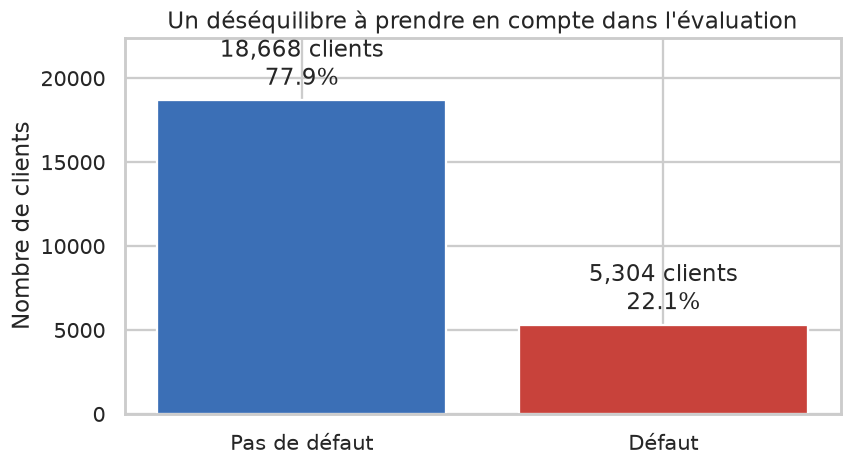

Explication : sur 23 972 clients explorés, 5 304 font défaut (22,1 %) : il y a environ 3,5 fois plus de clients sans défaut. Répondre toujours « pas de défaut » donnerait déjà 77,9 % d’accuracy, avec un recall nul. On comparera donc les modèles avec la ROC-AUC (qualité du classement) et on jugera les décisions avec la precision, le recall et le F1, plutôt qu’avec l’accuracy seule.

In [5]:
effectifs = df_exploration['DEFAULT'].value_counts().reindex([0, 1], fill_value=0)
taux_reference = df_exploration['DEFAULT'].mean()
fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(['Pas de défaut', 'Défaut'], effectifs.values, color=[BLEU, ROUGE])
ax.bar_label(bars, labels=[f'{n:,} clients\n{n / len(df_exploration):.1%}' for n in effectifs], padding=5)
ax.set(title="Un déséquilibre à prendre en compte dans l'évaluation", ylabel='Nombre de clients',
       ylim=(0, effectifs.max() * 1.2))
plt.tight_layout()
plt.show()
display(Markdown(
    f'Explication : sur {len(df_exploration):,} clients explorés, {effectifs.loc[1]:,} font défaut '
    f'({taux_reference:.1%}) : il y a environ {effectifs.loc[0]/effectifs.loc[1]:.1f} fois plus de clients sans défaut. '
    f'Répondre toujours « pas de défaut » donnerait déjà {1-taux_reference:.1%} d’accuracy, avec un recall nul. '
    'On comparera donc les modèles avec la ROC-AUC (qualité du classement) et on jugera les décisions '
    'avec la precision, le recall et le F1, plutôt qu’avec l’accuracy seule.'
))

## 1.5 Distributions et boxplots

On regarde l’âge, le plafond et les paiements pour comprendre les ordres de grandeur. Les histograms montrent où se concentrent les clients.

Dans un boxplot, le trait central est la médiane. La boîte va du premier quartile (Q1, 25 %) au troisième quartile (Q3, 75 %) : elle contient les 50 % de valeurs centrales. L’intervalle `IQR = Q3 - Q1` sert à définir les moustaches, qui vont jusqu’aux dernières valeurs à moins de `1,5 × IQR` des bords de la boîte. Les points au-delà sont des valeurs éloignées, pas forcément des erreurs.

Les deux boxplots comparent les clients avec et sans défaut. Pour les paiements, l’axe `symlog` permet de garder les zéros tout en affichant les grands montants. Les quartiles restent calculés sur les montants bruts : seul l’affichage change.

,count,mean,std,min,25%,50%,75%,95%,99%,max
AGE,23972.0,35.5,9.2,21.0,28.0,34.0,41.0,53.0,60.0,75.0
LIMIT_BAL,23972.0,167272.6,129869.9,10000.0,50000.0,140000.0,240000.0,430000.0,500000.0,1000000.0
BILL_AMT1,23972.0,51270.6,73242.0,-165580.0,3580.0,22587.0,67724.0,200346.4,348535.6,964511.0
PAY_AMT1,23972.0,5652.1,16680.8,0.0,1000.0,2100.0,5009.0,18332.4,65614.0,873552.0


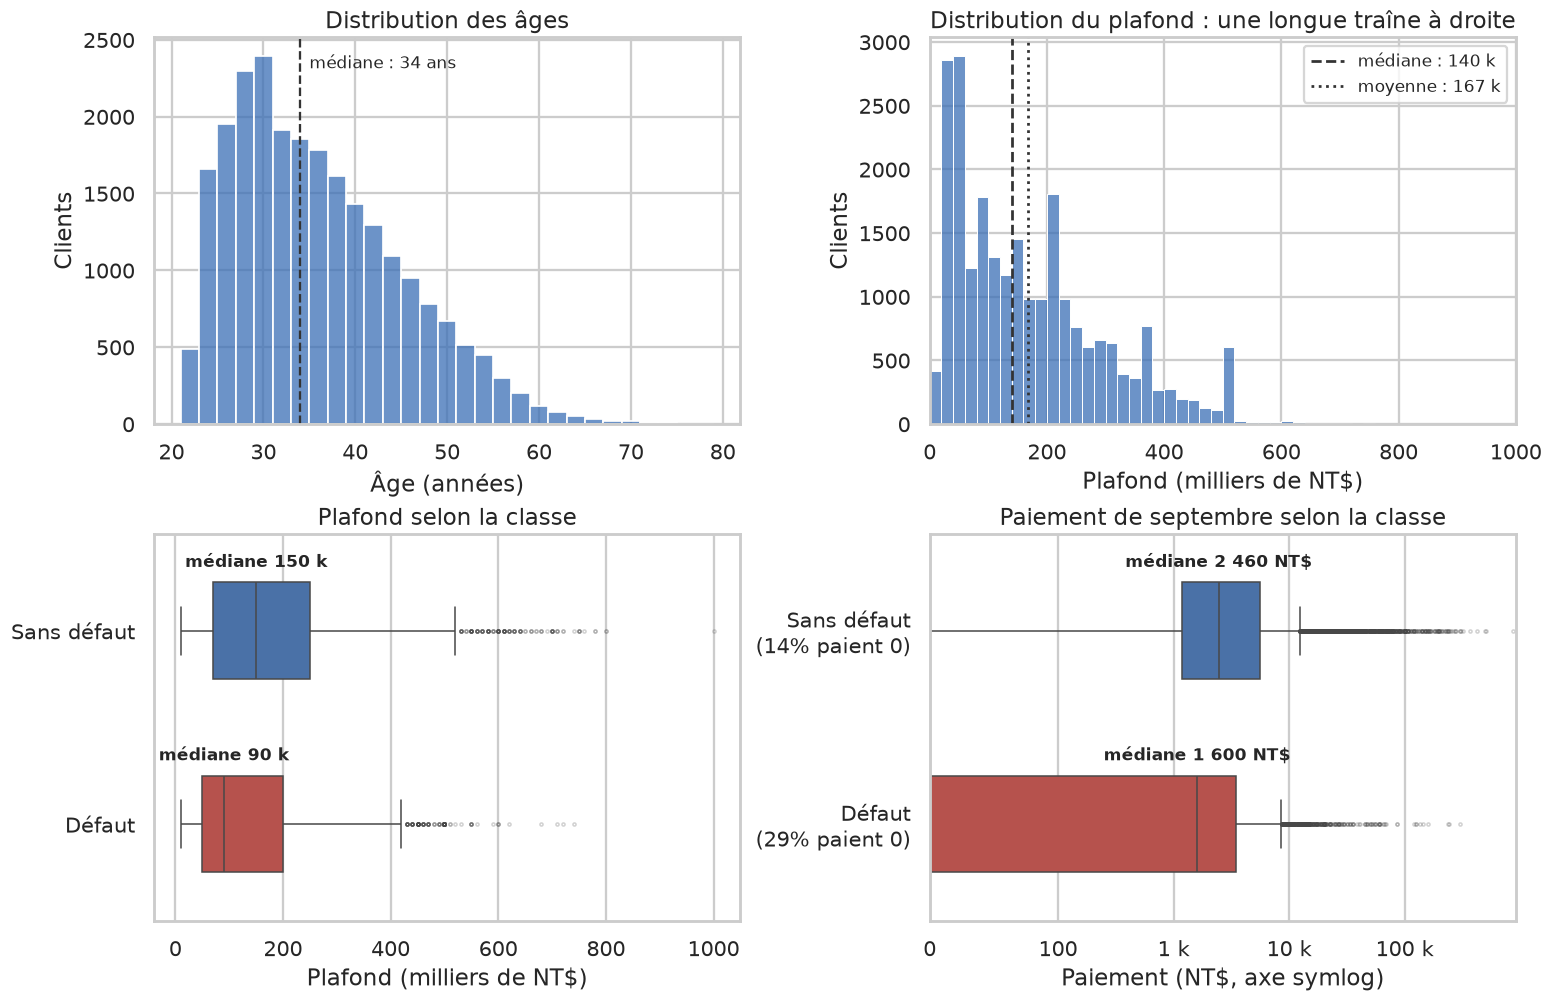

Explication : l’âge médian est de 34 ans. Le plafond moyen (167 273 NT$) dépasse sa médiane (140 000 NT$) : les grands plafonds tirent la moyenne vers le haut. Le plafond médian est de 150 000 NT$ sans défaut contre 90 000 NT$ avec défaut ; pour le paiement de septembre, 2 460 contre 1 600 NT$, avec 29 % de paiements nuls chez les clients en défaut contre 14 % chez les autres. Les centres diffèrent, mais les boîtes se recouvrent largement : aucun montant seul ne sépare les deux classes, il faudra combiner plusieurs features. Les écarts d’échelle (le 99e percentile des paiements atteint 65 614 NT$) justifient un scaling pour les modèles sensibles aux unités.

In [6]:
resume_numerique = df_exploration[['AGE', 'LIMIT_BAL', 'BILL_AMT1', 'PAY_AMT1']].describe(
    percentiles=[.25, .5, .75, .95, .99]).T
display(resume_numerique.round(1))

from matplotlib.ticker import FuncFormatter
CLASSES = ['Sans défaut', 'Défaut']
PALETTE_CLASSES = {'Sans défaut': BLEU, 'Défaut': ROUGE}
_explo = df_exploration.assign(Classe=df_exploration.DEFAULT.map({0: 'Sans défaut', 1: 'Défaut'}),
                               PLAFOND_K=df_exploration.LIMIT_BAL / 1000)

def _milliers(x, pos=None):
    if x == 0:
        return '0'
    return f'{x/1000:g} k' if abs(x) >= 1000 else f'{x:g}'

fig, axes = plt.subplots(2, 2, figsize=(14, 9), layout='constrained')
# Histogrammes : médiane (et moyenne pour le plafond) tracées pour lire l'asymétrie
sns.histplot(df_exploration.AGE, bins=range(21, 81, 2), color=BLEU, ax=axes[0, 0])
_med_age = df_exploration.AGE.median()
axes[0, 0].axvline(_med_age, color='#333333', ls='--', lw=1.5)
axes[0, 0].text(_med_age + 1, axes[0, 0].get_ylim()[1] * .92, f'médiane : {_med_age:.0f} ans', fontsize=11)
axes[0, 0].set(title='Distribution des âges', xlabel='Âge (années)', ylabel='Clients')

sns.histplot(_explo.PLAFOND_K, bins=range(0, 1020, 20), color=BLEU, ax=axes[0, 1])
for valeur, style, nom in [(_explo.PLAFOND_K.median(), '--', 'médiane'), (_explo.PLAFOND_K.mean(), ':', 'moyenne')]:
    axes[0, 1].axvline(valeur, color='#333333', ls=style, lw=1.8, label=f'{nom} : {valeur:.0f} k')
axes[0, 1].legend(loc='upper right', fontsize=11)
axes[0, 1].set(title='Distribution du plafond : une longue traîne à droite',
               xlabel='Plafond (milliers de NT$)', ylabel='Clients', xlim=(0, 1000))

# Boxplots horizontaux : classes nommées, montants en milliers, médianes écrites
for ax, colonne, titre, xlabel in [
        (axes[1, 0], 'PLAFOND_K', 'Plafond selon la classe', 'Plafond (milliers de NT$)'),
        (axes[1, 1], 'PAY_AMT1', 'Paiement de septembre selon la classe', 'Paiement (NT$, axe symlog)')]:
    sns.boxplot(data=_explo, y='Classe', x=colonne, order=CLASSES, hue='Classe', palette=PALETTE_CLASSES,
                legend=False, width=.5, fliersize=2, flierprops={'alpha': .25}, ax=ax)
    for i, classe in enumerate(CLASSES):
        mediane = _explo.loc[_explo.Classe == classe, colonne].median()
        texte = f'médiane {mediane:.0f} k' if colonne == 'PLAFOND_K' else f'médiane {mediane:,.0f} NT$'.replace(',', ' ')
        ax.text(mediane, i - .33, texte, ha='center', fontsize=11, weight='bold')
    ax.set(title=titre, xlabel=xlabel, ylabel='')
    ax.grid(axis='y', visible=False)
axes[1, 1].set_xscale('symlog', linthresh=100)
axes[1, 1].set_xlim(left=0)
axes[1, 1].xaxis.set_major_formatter(FuncFormatter(_milliers))
_parts_zero = [_explo.loc[_explo.Classe == classe, 'PAY_AMT1'].eq(0).mean() for classe in CLASSES]
axes[1, 1].set_yticks(range(2), [f'{classe}\n({p:.0%} paient 0)' for classe, p in zip(CLASSES, _parts_zero)])
plt.show()

_q = df_exploration.groupby('DEFAULT')[['LIMIT_BAL', 'PAY_AMT1']].quantile([.25, .5, .75]).unstack()
_zero_paiement = df_exploration.groupby('DEFAULT')['PAY_AMT1'].apply(lambda x: x.eq(0).mean())
display(Markdown(
    f'Explication : l’âge médian est de {df_exploration.AGE.median():.0f} ans. Le plafond moyen '
    f'({df_exploration.LIMIT_BAL.mean():,.0f} NT$) dépasse sa médiane ({df_exploration.LIMIT_BAL.median():,.0f} NT$) : '
    'les grands plafonds tirent la moyenne vers le haut. '
    f'Le plafond médian est de {_q.loc[0, ("LIMIT_BAL", .5)]:,.0f} NT$ sans défaut contre {_q.loc[1, ("LIMIT_BAL", .5)]:,.0f} NT$ avec défaut ; '
    f'pour le paiement de septembre, {_q.loc[0, ("PAY_AMT1", .5)]:,.0f} contre {_q.loc[1, ("PAY_AMT1", .5)]:,.0f} NT$, '
    f'avec {_zero_paiement.loc[1]:.0%} de paiements nuls chez les clients en défaut contre {_zero_paiement.loc[0]:.0%} chez les autres. '
    'Les centres diffèrent, mais les boîtes se recouvrent largement : aucun montant seul ne sépare les deux classes, '
    'il faudra combiner plusieurs features. Les écarts d’échelle (le 99e percentile des paiements atteint '
    f'{df_exploration.PAY_AMT1.quantile(.99):,.0f} NT$) justifient un scaling pour les modèles sensibles aux unités.'
))

## 1.6 Profil, plafond et défaut

Chaque point donne le **taux de défaut** d’un groupe. Le trait gris autour est un intervalle de confiance à 95 % (méthode de Wilson) : il s’élargit quand le groupe est petit. Le tiret vertical rappelle le taux moyen. L’effectif `n` est écrit à côté de chaque libellé.

Tous les panneaux partagent la **même échelle horizontale** : on compare directement l’écart entre groupes d’une variable à l’autre, sans avoir à relire des hauteurs de colonnes.

Les codes non documentés sont conservés pour montrer le fichier tel qu’il est. Les groupes de moins de 300 clients sont tracés en point creux : leur intervalle très large rappelle qu’on ne peut pas conclure sur leur taux.

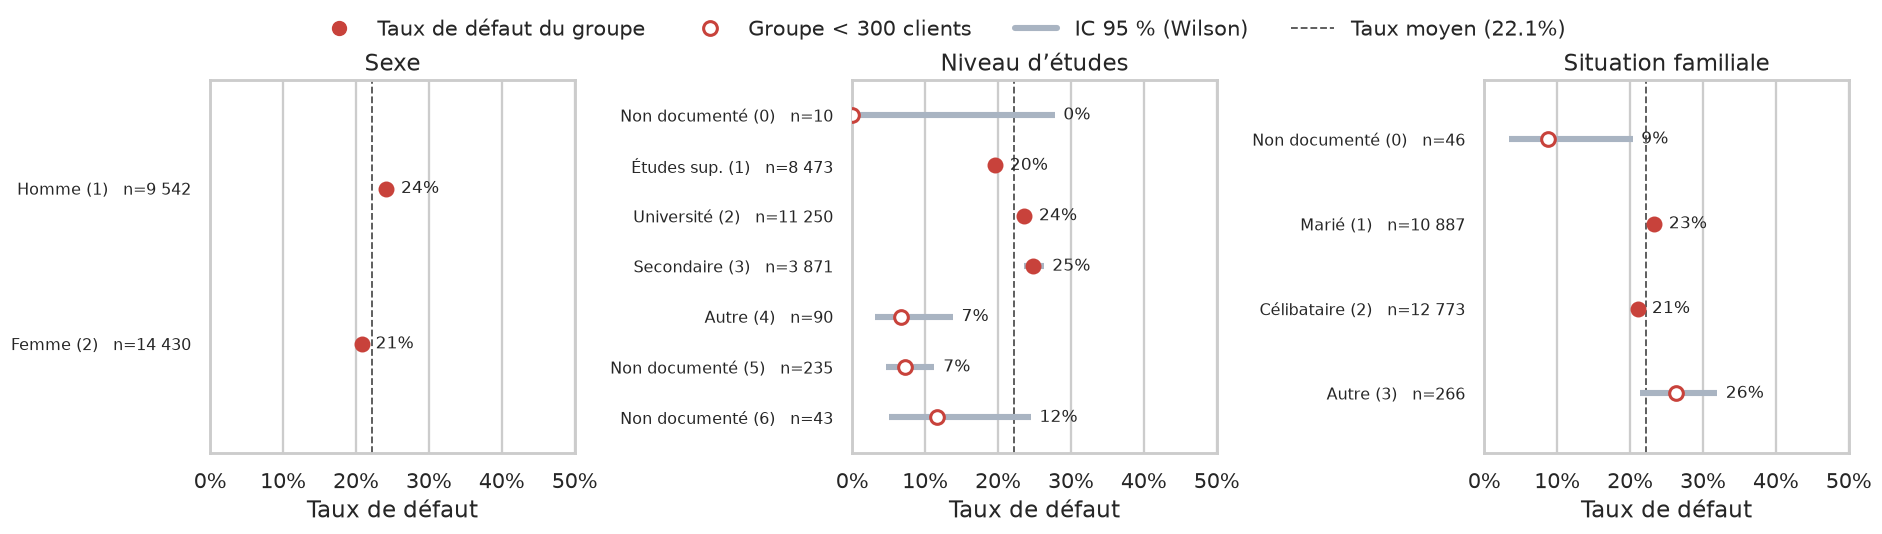

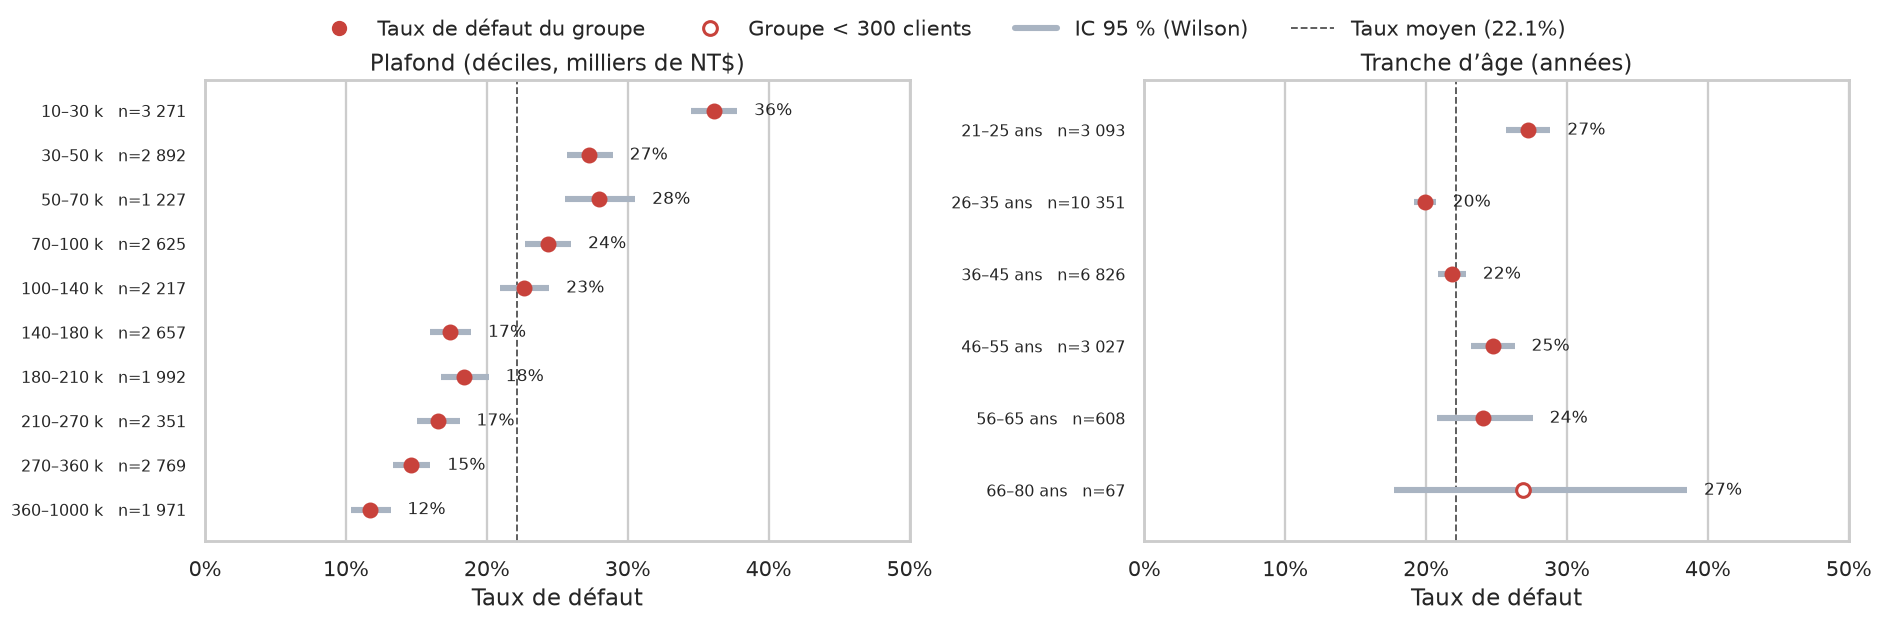

Explication : selon le code SEX, les taux sont de 24,1 % (hommes) et 20,8 % (femmes), soit 3,3 points d’écart ; pour les trois niveaux d’études documentés les plus fréquents, ils vont de 19,6 % à 24,9 %. Le plafond sépare beaucoup plus : de 36,1 % dans le décile le plus bas à 11,7 % dans le plus haut (24,4 points). Pour l’âge, le taux passe de 27,2 % chez les 21-25 ans à 19,9 % chez les 26-35 ans, puis remonte : il ne diminue pas régulièrement avec l’âge. Les codes rares ont des intervalles trop larges pour être interprétés.

In [7]:
from matplotlib.lines import Line2D

LIBELLES_CODES = {
    'SEX': {1: 'Homme (1)', 2: 'Femme (2)'},
    'EDUCATION': {0: 'Non documenté (0)', 1: 'Études sup. (1)', 2: 'Université (2)', 3: 'Secondaire (3)',
                  4: 'Autre (4)', 5: 'Non documenté (5)', 6: 'Non documenté (6)'},
    'MARRIAGE': {0: 'Non documenté (0)', 1: 'Marié (1)', 2: 'Célibataire (2)', 3: 'Autre (3)'},
}
graphiques_profil = [
    ('SEX', df_exploration.SEX, 'Sexe'),
    ('EDUCATION', df_exploration.EDUCATION, 'Niveau d’études'),
    ('MARRIAGE', df_exploration.MARRIAGE, 'Situation familiale'),
    ('LIMIT_BAL', pd.qcut(df_exploration.LIMIT_BAL, 10, duplicates='drop'), 'Plafond (déciles, milliers de NT$)'),
    ('AGE', pd.cut(df_exploration.AGE, [20, 25, 35, 45, 55, 65, 80]), 'Tranche d’âge (années)'),
]
comptages_profil = {nom: pd.crosstab(groupes, df_exploration.DEFAULT).reindex(columns=[0, 1], fill_value=0)
                    for nom, groupes, _ in graphiques_profil}

def intervalle_wilson(k, n, z=1.96):
    """Intervalle de confiance de Wilson pour une proportion k/n."""
    k, n = np.asarray(k, float), np.asarray(n, float)
    p = k / n
    centre = (p + z**2 / (2*n)) / (1 + z**2 / n)
    demi = z * np.sqrt(p*(1-p)/n + z**2/(4*n**2)) / (1 + z**2 / n)
    return centre - demi, centre + demi

def libelle_groupe(nom, groupe):
    if nom == 'LIMIT_BAL':
        return f'{max(groupe.left, 0)/1000:.0f}–{groupe.right/1000:.0f} k'
    if nom == 'AGE':
        return f'{int(groupe.left)+1}–{int(groupe.right)} ans'
    return LIBELLES_CODES[nom].get(groupe, str(groupe))

_bornes = [intervalle_wilson(t[1], t.sum(axis=1))[1].max() for t in comptages_profil.values()]
XMAX_TAUX = min(1, max(.5, max(_bornes) + .08))
PETIT_GROUPE = 300

def taux_par_groupe(ax, nom, titre):
    table = comptages_profil[nom]
    n = table.sum(axis=1).to_numpy()
    k = table[1].to_numpy()
    taux = k / n
    bas, haut = intervalle_wilson(k, n)
    y = np.arange(len(table))[::-1]            # premier groupe en haut
    ax.hlines(y, bas, haut, color='#A9B4C2', lw=4, zorder=1)
    petit = n < PETIT_GROUPE
    ax.scatter(taux[~petit], y[~petit], s=80, color=ROUGE, zorder=3)
    ax.scatter(taux[petit], y[petit], s=80, facecolor='white', edgecolor=ROUGE, linewidth=2, zorder=3)
    for yi, t, h in zip(y, taux, haut):
        ax.text(h + .012, yi, f'{t:.0%}', va='center', fontsize=11)
    ax.axvline(taux_reference, color='#555555', ls='--', lw=1.2, zorder=0)
    etiquettes = [f'{libelle_groupe(nom, g)}   n={c:,}'.replace(',', ' ') for g, c in zip(table.index, n)]
    ax.set_yticks(y, etiquettes, fontsize=10.5)
    ax.set_ylim(-.7, len(table) - .3)
    ax.set_xlim(0, XMAX_TAUX)
    ax.xaxis.set_major_formatter(PercentFormatter(1))
    ax.set(title=titre, xlabel='Taux de défaut')
    ax.grid(axis='y', visible=False)

_legende = [Line2D([], [], marker='o', ls='', color=ROUGE, markersize=9, label='Taux de défaut du groupe'),
            Line2D([], [], marker='o', ls='', markerfacecolor='white', markeredgecolor=ROUGE, markeredgewidth=2,
                   markersize=9, label=f'Groupe < {PETIT_GROUPE} clients'),
            Line2D([], [], color='#A9B4C2', lw=4, label='IC 95 % (Wilson)'),
            Line2D([], [], color='#555555', ls='--', lw=1.2, label=f'Taux moyen ({taux_reference:.1%})')]

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), layout='constrained',
                         gridspec_kw={'width_ratios': [1, 1, 1]})
for ax, (nom, _, titre) in zip(axes, graphiques_profil[:3]):
    taux_par_groupe(ax, nom, titre)
fig.legend(handles=_legende, loc='outside upper center', ncol=4, frameon=False)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(17, 5.6), layout='constrained')
for ax, (nom, _, titre) in zip(axes, graphiques_profil[3:]):
    taux_par_groupe(ax, nom, titre)
fig.legend(handles=_legende, loc='outside upper center', ncol=4, frameon=False)
plt.show()

_taux = {nom: t[1] / t.sum(axis=1) for nom, t in comptages_profil.items()}
taux_p, taux_a = _taux['LIMIT_BAL'], _taux['AGE']
_educ = _taux['EDUCATION'].loc[[1, 2, 3]]
display(Markdown(
    f'Explication : selon le code SEX, les taux sont de {_taux["SEX"].loc[1]:.1%} (hommes) et {_taux["SEX"].loc[2]:.1%} (femmes), '
    f'soit {abs(_taux["SEX"].loc[1]-_taux["SEX"].loc[2])*100:.1f} points d’écart ; pour les trois niveaux d’études documentés '
    f'les plus fréquents, ils vont de {_educ.min():.1%} à {_educ.max():.1%}. '
    f'Le plafond sépare beaucoup plus : de {taux_p.iloc[0]:.1%} dans le décile le plus bas à {taux_p.iloc[-1]:.1%} dans le plus haut '
    f'({abs(taux_p.iloc[0]-taux_p.iloc[-1])*100:.1f} points). Pour l’âge, le taux passe de {taux_a.iloc[0]:.1%} chez les 21-25 ans '
    f'à {taux_a.iloc[1]:.1%} chez les 26-35 ans, puis remonte : il ne diminue pas régulièrement avec l’âge. '
    'Les codes rares ont des intervalles trop larges pour être interprétés.'
))

Explication

Le taux et l’effectif sont deux informations distinctes : un groupe nombreux peut contenir davantage de défauts en valeur absolue sans présenter le taux le plus élevé. Pour `SEX` et les deux principaux codes de `MARRIAGE`, les intervalles sont étroits et proches du taux moyen ; pour le plafond, les points s’étalent beaucoup plus. Les codes non documentés ont des intervalles si larges qu’ils ne permettent aucune conclusion. Ces écarts motivent l’usage de plusieurs features, mais ne disent pas encore ce que chacune ajoutera à un modèle qui connaît les autres.

## 1.7 Historique des retards

On regarde maintenant les statuts de remboursement. Les codes `-2`, `-1` et `0` restent séparés ; les retards d’au moins trois mois sont regroupés pour l’affichage seulement. Le second graphique compte les dates avec un statut positif parmi les six mois disponibles : son axe va donc de 0 à 6.

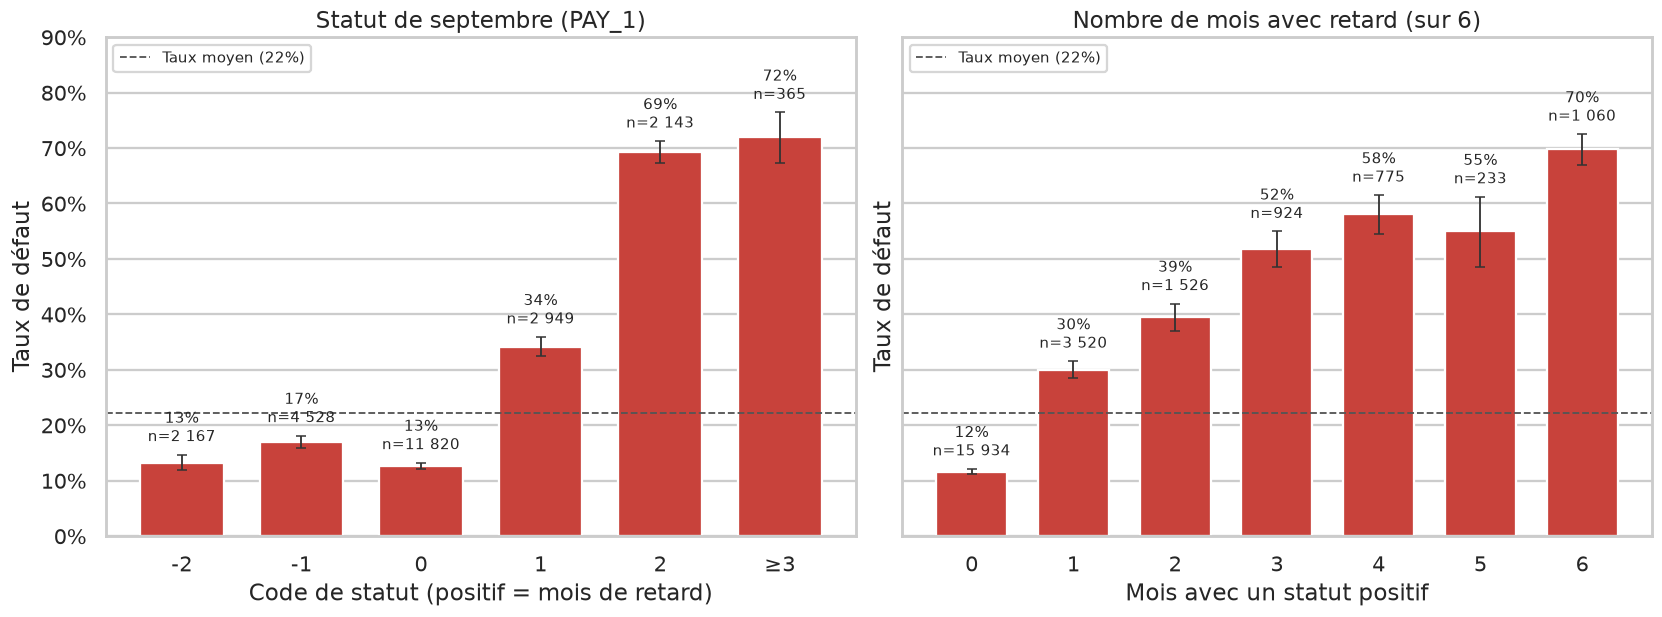

Explication : les codes -2, -1 et 0 ont des taux proches (13 % à 17 %), puis le taux saute dès un mois de retard : 69,7 % de défauts pour `PAY_1 ≥ 2` contre 13,8 % pour `PAY_1 ≤ 0`, soit 56 points d’écart. La répétition compte aussi : 11,6 % sans mois de retard, 51,7 % avec trois mois. Le comportement récent est donc plus discriminant que les caractéristiques de profil. Le nombre de mois avec retard décrit la répétition sur six relevés, pas la durée totale d’un incident.

In [8]:
statut_recent = df_exploration['PAY_1'].where(df_exploration['PAY_1'] < 3, 3)
nb_mois_retard_explo = (df_exploration[statuts] >= 1).sum(axis=1)
groupes_retards = [
    (statut_recent, ['-2', '-1', '0', '1', '2', '≥3'], 'Statut de septembre (PAY_1)', 'Code de statut (positif = mois de retard)'),
    (nb_mois_retard_explo, None, 'Nombre de mois avec retard (sur 6)', 'Mois avec un statut positif'),
]
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), layout='constrained', sharey=True)
for ax, (groupes_col, labels, titre, xlabel) in zip(axes, groupes_retards):
    groupes = df_exploration.groupby(groupes_col)['DEFAULT'].agg(Clients='size', Defauts='sum')
    groupes['Taux'] = groupes.Defauts / groupes.Clients
    bas, haut = intervalle_wilson(groupes.Defauts, groupes.Clients)
    x = np.arange(len(groupes))
    ax.bar(x, groupes.Taux, color=ROUGE, width=.7)
    ax.errorbar(x, groupes.Taux, yerr=[groupes.Taux - bas, haut - groupes.Taux], fmt='none',
                ecolor='#333333', capsize=3, lw=1.2)
    for xi, (t, n, h) in enumerate(zip(groupes.Taux, groupes.Clients, haut)):
        ax.text(xi, h + .015, f'{t:.0%}\nn={n:,}'.replace(',', ' '), ha='center', va='bottom', fontsize=10)
    ax.axhline(taux_reference, color='#555555', ls='--', lw=1.2, label=f'Taux moyen ({taux_reference:.0%})')
    ax.set_xticks(x, labels if labels is not None else groupes.index.astype(str))
    ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.set(title=titre, xlabel=xlabel, ylabel='Taux de défaut', ylim=(0, .9))
    ax.grid(axis='x', visible=False)
    ax.legend(loc='upper left', fontsize=10)
plt.show()
taux_statut = df_exploration.groupby('PAY_1')['DEFAULT'].agg(Clients='size', Taux='mean')
taux_repetition = df_exploration.groupby(nb_mois_retard_explo)['DEFAULT'].agg(Clients='size', Taux='mean')
_taux_recent = df_exploration.loc[df_exploration.PAY_1 >= 2, 'DEFAULT'].mean()
_taux_a_jour = df_exploration.loc[df_exploration.PAY_1 <= 0, 'DEFAULT'].mean()
display(Markdown(
    f'Explication : les codes -2, -1 et 0 ont des taux proches ({taux_statut.loc[[-2, -1, 0], "Taux"].min():.0%} à '
    f'{taux_statut.loc[[-2, -1, 0], "Taux"].max():.0%}), puis le taux saute dès un mois de retard : '
    f'{_taux_recent:.1%} de défauts pour `PAY_1 ≥ 2` contre {_taux_a_jour:.1%} pour `PAY_1 ≤ 0`, '
    f'soit {(_taux_recent-_taux_a_jour)*100:.0f} points d’écart. '
    f'La répétition compte aussi : {taux_repetition.loc[0, "Taux"]:.1%} sans mois de retard, {taux_repetition.loc[3, "Taux"]:.1%} avec trois mois. '
    'Le comportement récent est donc plus discriminant que les caractéristiques de profil. '
    'Le nombre de mois avec retard décrit la répétition sur six relevés, pas la durée totale d’un incident.'
))

Les écarts de taux sont plus marqués pour les retards que pour plusieurs catégories de profil. On retiendra deux résumés pour le feature engineering : combien de mois observés présentent un retard, et quelle est la durée maximale de retard indiquée. Le premier est limité à six observations ; le second peut dépasser six mois. Leur apport au modèle sera mesuré avec/sans ces features en cross-validation.

## 1.8 Corrélations entre features

La heatmap de Spearman compare les rangs des features numériques et de `DEFAULT`. Elle permet de repérer les informations proches et les associations avec la target. Les codes nominaux `SEX`, `EDUCATION` et `MARRIAGE`, ainsi que `ID`, sont exclus : leur numérotation ne définit pas une échelle quantitative.

Le second graphique garde uniquement Pearson pour les dix associations linéaires les plus fortes avec `DEFAULT`. Ces deux mesures ne répondent pas exactement à la même question : une faible corrélation de Pearson n’exclut pas une relation non linéaire. Aucune corrélation ne démontre une causalité.

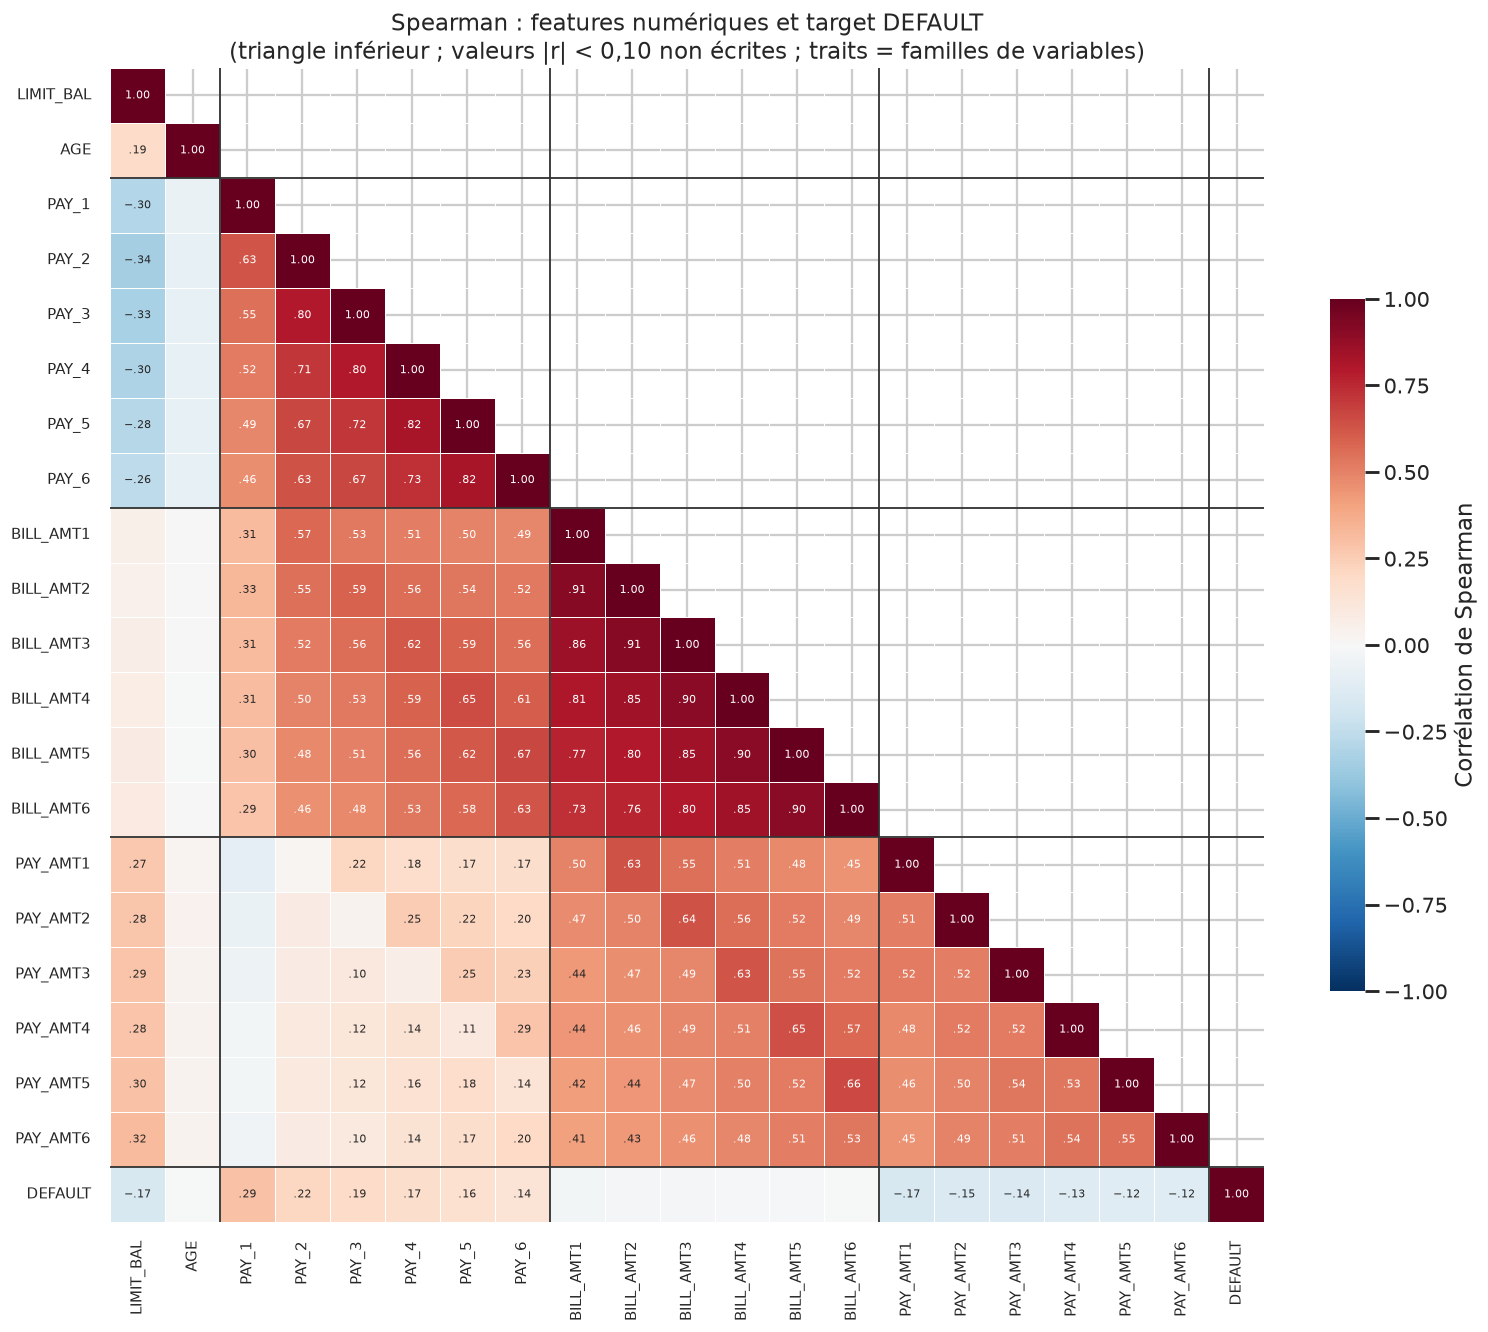

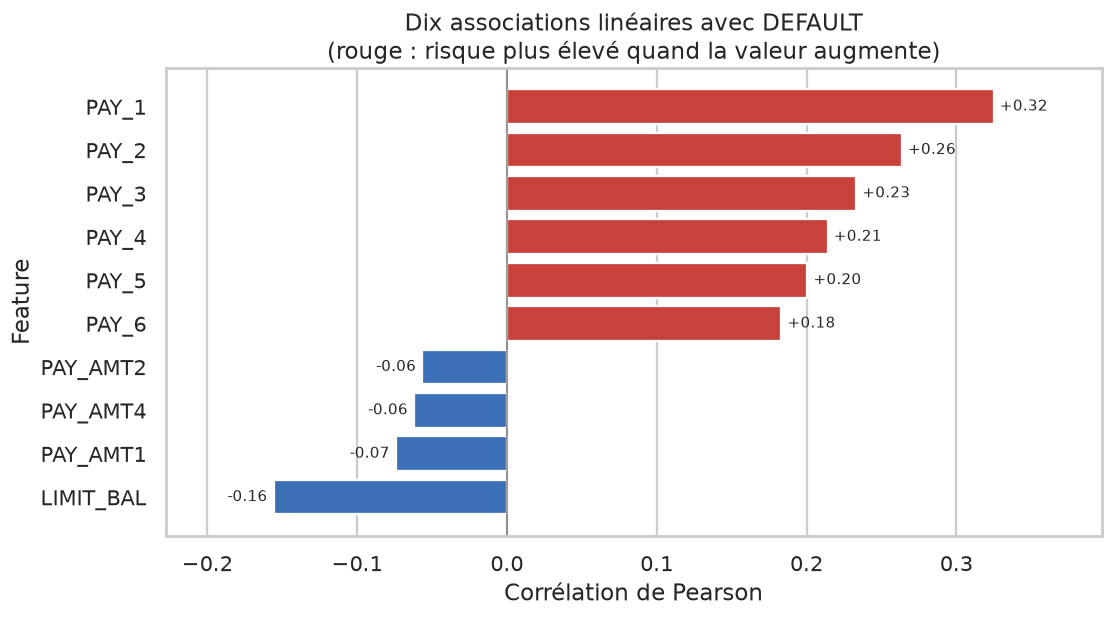

Explication : Spearman vaut 0,91 entre les relevés de septembre et août : ils apportent une information largement commune. Le statut récent `PAY_1` est associé à la target (Spearman 0,29, Pearson 0,32). Pour `LIMIT_BAL`, Pearson vaut -0,16, ce qui concorde avec les taux plus faibles dans les grands plafonds. On conserve ces observations pour construire des features et nuancer les importances, sans supprimer automatiquement les colonnes corrélées.

In [9]:
colonnes_numeriques = ['LIMIT_BAL', 'AGE'] + statuts + factures + paiements
corr_spearman = df_exploration[colonnes_numeriques+['DEFAULT']].corr(method='spearman')
# Triangle inférieur seulement (la matrice est symétrique) et valeurs écrites
_masque = np.triu(np.ones_like(corr_spearman, dtype=bool), k=1)
_annot = corr_spearman.map(lambda r: f'{r:.2f}'.replace('0.', '.').replace('-.', '−.') if abs(r) >= .1 else '')
fig, ax = plt.subplots(figsize=(14, 12), layout='constrained')
sns.heatmap(corr_spearman, mask=_masque, cmap='RdBu_r', vmin=-1, vmax=1, center=0, square=True,
            annot=_annot, fmt='', annot_kws={'fontsize': 7.5}, linewidths=.6, linecolor='white',
            cbar_kws={'label': 'Corrélation de Spearman', 'shrink': .6}, ax=ax)
# Séparer les familles : profil | statuts | relevés | paiements | cible
for limite in [2, 8, 14, 20]:
    ax.axhline(limite, color='#333333', lw=1.2)
    ax.axvline(limite, color='#333333', lw=1.2)
ax.set_title('Spearman : features numériques et target DEFAULT\n'
             '(triangle inférieur ; valeurs |r| < 0,10 non écrites ; traits = familles de variables)')
ax.tick_params(axis='both', labelsize=10)
plt.show()

corr_pearson = df_exploration[colonnes_numeriques].corrwith(df_exploration.DEFAULT, method='pearson')
top_corr = corr_pearson.loc[corr_pearson.abs().nlargest(10).index].sort_values()
fig, ax = plt.subplots(figsize=(10, 5.5), layout='constrained')
bars = ax.barh(top_corr.index, top_corr.values, color=[ROUGE if valeur > 0 else BLEU for valeur in top_corr])
ax.bar_label(bars, fmt='%+.2f', padding=4, fontsize=10)
ax.axvline(0, color='grey', lw=1)
ax.margins(x=.15)
ax.set(title='Dix associations linéaires avec DEFAULT\n(rouge : risque plus élevé quand la valeur augmente)',
       xlabel='Corrélation de Pearson', ylabel='Feature')
ax.grid(axis='y', visible=False)
plt.show()
display(Markdown(
    f'Explication : Spearman vaut {corr_spearman.loc["BILL_AMT1","BILL_AMT2"]:.2f} entre '
    f'les relevés de septembre et août : ils apportent une information largement commune. '
    f'Le statut récent `PAY_1` est associé à la target (Spearman {corr_spearman.loc["PAY_1","DEFAULT"]:.2f}, '
    f'Pearson {corr_pearson.loc["PAY_1"]:.2f}). '
    f'Pour `LIMIT_BAL`, Pearson vaut {corr_pearson.loc["LIMIT_BAL"]:.2f}, ce qui concorde avec '
    'les taux plus faibles dans les grands plafonds. On conserve ces observations pour construire des features '
    'et nuancer les importances, sans supprimer automatiquement les colonnes corrélées.'
))

## 1.9 Bilan de l’EDA

Environ 22 % des clients étudiés font défaut. Les retards récents et répétés présentent les écarts de taux les plus marqués, tandis que les relevés mensuels sont fortement corrélés entre eux. Les montants sont dispersés et certains codes de catégories restent peu documentés.

La préparation va donc traiter les catégories et les répétitions, prévoir le scaling des modèles qui en ont besoin, et construire quelques résumés de l’historique. L’EDA décrit ces associations ; la cross-validation vérifiera ensuite ce qu’elles apportent à la prédiction.

<a id="partie-2"></a>
# Partie 2 - Préparation des données

On passe du fichier brut aux inputs des modèles. Les règles de nettoyage sont explicites, puis on encode les catégories et on construit les features.

## 2.1 Audit des données

On compte les répétitions, les codes non documentés et les montants particuliers. Une valeur inhabituelle n’est pas supprimée automatiquement.


In [10]:
audit = pd.Series({
    'Cellules manquantes': int(df_exploration.isna().sum().sum()),
    'Répétitions exactes hors ID dans la source': int((~masque_representants).sum()),
    'EDUCATION hors codes documentés 1 à 4 (exploration)': int((~df_exploration.EDUCATION.isin([1, 2, 3, 4])).sum()),
    'MARRIAGE hors codes documentés 1 à 3 (exploration)': int((~df_exploration.MARRIAGE.isin([1, 2, 3])).sum()),
    'Clients avec au moins un relevé négatif (exploration)': int((df_exploration[factures] < 0).any(axis=1).sum()),
    'Plafonds <= 0 (exploration)': int((df_exploration.LIMIT_BAL <= 0).sum()),
    'Paiements négatifs (cellules, exploration)': int((df_exploration[paiements] < 0).sum().sum()),
}, name='Nombre')
display(audit.to_frame())
# Les données utilisées pour l'analyse restent disponibles dans df_source et df_exploration.
df = df_source.copy()

,Nombre
Cellules manquantes,0
Répétitions exactes hors ID dans la source,35
EDUCATION hors codes documentés 1 à 4 (exploration),288
MARRIAGE hors codes documentés 1 à 3 (exploration),46
Clients avec au moins un relevé négatif (exploration),1529
Plafonds <= 0 (exploration),0
"Paiements négatifs (cellules, exploration)",0


## 2.2 Retirer ID

On supprime la colonne `ID` des données utilisées pour la prédiction.

Ce numéro identifie un client dans le fichier ; ce n'est pas une mesure de son comportement de remboursement. Le laisser dans les entrées pourrait faire apprendre au modèle un lien lié à la numérotation du fichier.

On passe de 25 à 24 colonnes : 23 caractéristiques du client et la target `DEFAULT`.

In [11]:
df = df.drop(columns='ID')
print(f'Après retrait de ID : {df.shape[0]} lignes et {df.shape[1]} colonnes')

Après retrait de ID : 30000 lignes et 24 colonnes


## 2.3 Traiter les doublons

Après le retrait de `ID`, on compte les lignes entièrement identiques, puis on n'en conserve qu'une par groupe avec `drop_duplicates()`. Le comptage inclut la target `DEFAULT`. `reset_index(drop=True)` renumérote simplement les lignes restantes.

Pourquoi après le retrait de `ID` ? Deux lignes avec des identifiants différents ne peuvent pas être identiques tant que cette colonne est présente. Sur ce fichier, on retire 35 répétitions, ce qui laisse 29 965 lignes.

Choix repris de ce notebook. Deux lignes identiques peuvent aussi correspondre à des clients distincts : leur égalité ne prouve pas une erreur de saisie. Ici, on conserve le choix de dédoublonnage du support initial. Cela ne garantit pas que tous les profils explicatifs identiques seront séparés du test : pour cette garantie, il faudrait les conserver ensemble lors du découpage, comme dans le notebook de démarche d'ingénieur.

In [12]:
n_avant = len(df)
n_repetitions = int(df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)

print(f'Lignes avant : {n_avant}')
print(f'Répétitions retirées : {n_repetitions}')
print(f'Lignes restantes : {len(df)}')

Lignes avant : 30000
Répétitions retirées : 35
Lignes restantes : 29965


## 2.4 Regrouper les codes non documentés

Les codes non documentés de EDUCATION et MARRIAGE sont regroupés dans les catégories « autre » existantes :

| Variable | Codes non documentés regroupés | Catégorie de destination |
|---|---|---|
| `EDUCATION` | `0`, `5`, `6` | `4`, « autre » |
| `MARRIAGE` | `0` | `3`, « autre » |

Ce regroupement simplifie la représentation en réunissant ces codes dans une catégorie existante. C’est une convention de préparation, pas une signification confirmée de ces codes : on perd la distinction entre eux. Une autre démarche consiste à les conserver séparément.

On ne supprime pas les montants élevés, les zéros ou les relevés négatifs sans preuve d'erreur. Les statuts `PAY_k`, notamment les codes `-2` et `0` dont le sens n'est pas précisé dans la documentation utilisée, restent inchangés. Dans ce notebook, ils restent numériques ; c'est un choix simplificateur à garder en tête lors de l'interprétation des modèles linéaires et des distances.

In [13]:
colonnes_categories = ['EDUCATION', 'MARRIAGE']
codes_avant = df[colonnes_categories].copy()

df['EDUCATION'] = df['EDUCATION'].replace({0: 4, 5: 4, 6: 4})
df['MARRIAGE'] = df['MARRIAGE'].replace({0: 3})

for colonne in colonnes_categories:
    print(f'Effectifs des codes de {colonne}')
    display(pd.concat([
        codes_avant[colonne].value_counts().rename('Avant'),
        df[colonne].value_counts().rename('Après'),
    ], axis=1).fillna(0).astype(int).sort_index())

Effectifs des codes de EDUCATION


,Avant,Après
EDUCATION,,
0,14,0
1,10563,10563
2,14019,14019
3,4915,4915
4,123,468
5,280,0
6,51,0


Effectifs des codes de MARRIAGE


,Avant,Après
MARRIAGE,,
0,54,0
1,13643,13643
2,15945,15945
3,323,377


## 2.5 One-hot encoding

Le problème. Si on garde `EDUCATION` comme un nombre, un modèle peut interpréter le code `4` comme une valeur deux fois plus grande que `2`. Or ce sont des étiquettes.

`pd.get_dummies` transforme `SEX`, `EDUCATION` et `MARRIAGE` en indicateurs : c'est l'encodage one-hot. Chaque nouvelle colonne vaut `1` si le client appartient à la catégorie et `0` sinon.

Exemple. Après le regroupement, `EDUCATION` possède quatre catégories. Avec `drop_first=True`, on crée `EDUCATION_2`, `EDUCATION_3` et `EDUCATION_4`. Pour un client de catégorie `2`, ces indicateurs valent respectivement `1`, `0`, `0`. S'ils valent tous `0`, le client appartient à la catégorie de référence, `1`.

`drop_first=True` retire un indicateur redondant, pas des clients. `dtype=int` produit des entiers 0/1. La target n'est pas encodée : elle est déjà binaire.

In [14]:
colonnes_a_encoder = ['SEX', 'EDUCATION', 'MARRIAGE']
exemple_categories = df[colonnes_a_encoder].head().copy()
df = pd.get_dummies(df, columns=colonnes_a_encoder, drop_first=True, dtype=int)
colonnes_encodees = [
    colonne for colonne in df.columns
    if colonne.startswith(('SEX_', 'EDUCATION_', 'MARRIAGE_'))
]

print('Catégories avant encodage :')
display(exemple_categories)
print('Indicateurs correspondants :')
display(df[colonnes_encodees].head())
print(f'Après encodage : {df.shape[0]} lignes et {df.shape[1]} colonnes, cible comprise')

Catégories avant encodage :


,SEX,EDUCATION,MARRIAGE
0,2,2,1
1,2,2,2
2,2,2,2
3,2,2,1
4,1,2,1


Indicateurs correspondants :


,SEX_2,EDUCATION_2,EDUCATION_3,EDUCATION_4,MARRIAGE_2,MARRIAGE_3
0,1,1,0,0,0,0
1,1,1,0,0,1,0
2,1,1,0,0,1,0
3,1,1,0,0,0,0
4,0,1,0,0,0,0


Après encodage : 29965 lignes et 27 colonnes, cible comprise


## 2.6 Séparer X et y

On construit deux objets :

- `X` contient les variables explicatives, donc les informations connues sur le client avant le mois à prédire ;
- `y` contient uniquement `DEFAULT`, la réponse observée que le modèle doit apprendre à prédire.

Si `DEFAULT` restait dans `X`, on donnerait la réponse au modèle. Il semblerait excellent pendant l'évaluation mais cette réponse serait indisponible pour un nouveau client : c'est une fuite d'information.

On obtient 26 variables explicatives après encodage. La moyenne de `y` donne la proportion de défauts, puisqu'il ne contient que des 0 et des 1 : environ 22 %. Les classes sont donc déséquilibrées, ce qui motive le choix des métriques en § 3.1.

In [15]:
X = df.drop(columns='DEFAULT')   # les variables explicatives
y = df['DEFAULT']                # la cible

print(f'{X.shape[0]} clients, {X.shape[1]} variables, {y.mean():.1%} de défauts')
display(y.value_counts().sort_index().rename_axis('DEFAULT').to_frame('Clients'))

29965 clients, 26 variables, 22.1% de défauts


,Clients
DEFAULT,
0,23335
1,6630


## 2.7 Réserver le test set

Les 30 000 lignes initiales deviennent 29 965 après retrait de 35 répétitions exactes hors ID. Le split conserve 23 972 observations (80 %) pour l’exploration, le tuning et le choix du threshold, et réserve 5 993 observations (20 %) pour l’évaluation finale.

Les lignes sont mélangées avec shuffle et `random_state=42`. La répartition des deux classes est conservée approximativement dans les deux ensembles. Le test contient 1 326 défauts et 4 667 absences de défaut ; ses résultats ne servent pas à choisir les features, le modèle ou le threshold.

La nested CV est appliquée seulement aux 23 972 observations de développement. La figure suivante montre comment chaque niveau utilise une partie des données, sans inclure le test réservé dans le tuning.


In [16]:
# La déduplication a conservé le même ordre que l'index des représentants de la partie 1.
assert len(df) == len(indices_representants)
X_train, X_test = X.iloc[pos_train].copy(), X.iloc[pos_test].copy()
y_train, y_test = y.iloc[pos_train].copy(), y.iloc[pos_test].copy()
assert np.array_equal(X_train['PAY_1'].to_numpy(), df_exploration['PAY_1'].to_numpy())
assert np.array_equal(y_train.to_numpy(), df_exploration['DEFAULT'].to_numpy())
print(f'Entraînement : {len(X_train)} clients ({y_train.mean():.1%} de défauts)')
print(f'Test réservé : {len(X_test)} clients')

Entraînement : 23972 clients (22.1% de défauts)
Test réservé : 5993 clients


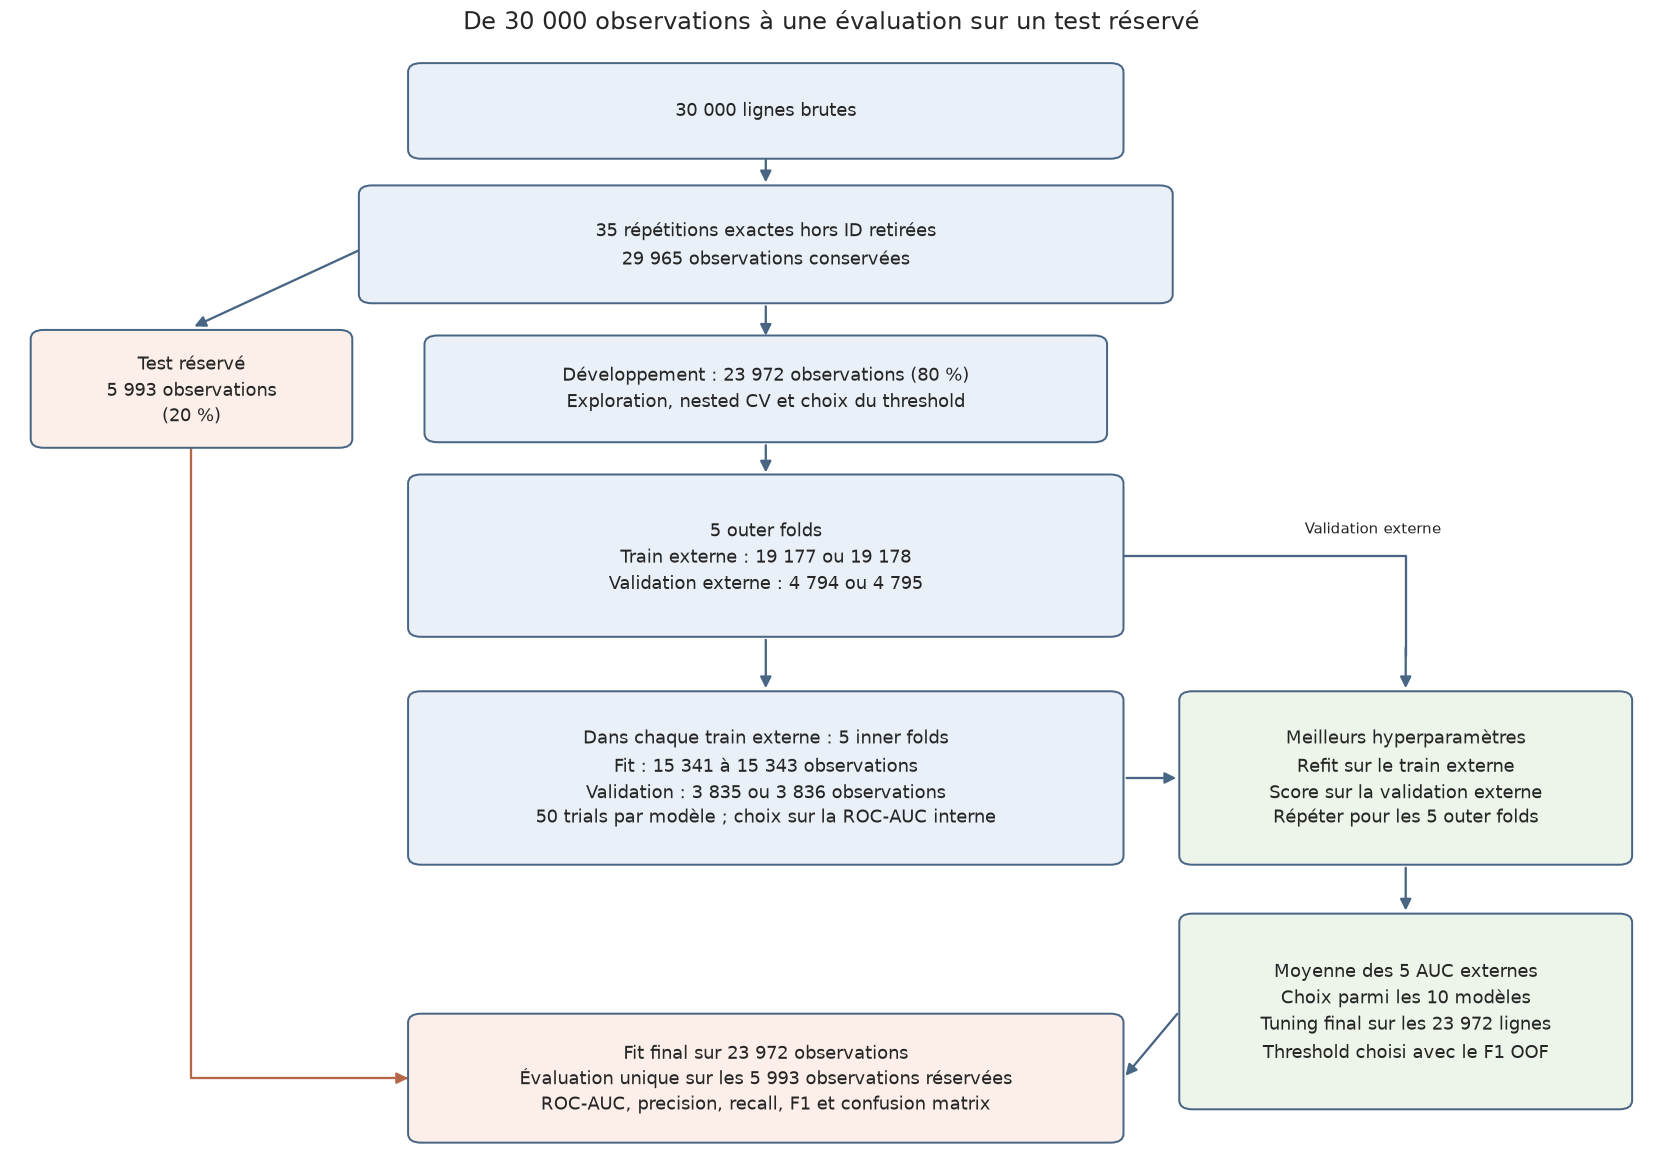

,Outer fold,Train externe,Validation externe,Fit interne (min-max),Validation interne (min-max)
0,1,19177,4795,15341-15342,3835-3836
1,2,19177,4795,15341-15342,3835-3836
2,3,19178,4794,15342-15343,3835-3836
3,4,19178,4794,15342-15343,3835-3836
4,5,19178,4794,15342-15343,3835-3836


Explication : les folds réutilisent des sous-ensembles du même train ; ils ne créent pas de nouvelles observations. Chaque observation de développement est évaluée une fois dans une validation externe, après un tuning qui ne l’utilise pas. Les 5 993 observations du test suivent une branche séparée et ne servent qu’à l’évaluation finale.

In [17]:
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

_outer = plis_cv(y_train, k=5, seed=SEED)
_lignes_protocole = []
for _tour, (_tr, _va) in enumerate(_outer, 1):
    _inner = plis_cv(y_train.iloc[_tr], k=5, seed=SEED)
    _lignes_protocole.append({
        'Outer fold': _tour,
        'Train externe': len(_tr),
        'Validation externe': len(_va),
        'Fit interne (min-max)': f'{min(len(a) for a,b in _inner)}-{max(len(a) for a,b in _inner)}',
        'Validation interne (min-max)': f'{min(len(b) for a,b in _inner)}-{max(len(b) for a,b in _inner)}',
    })
_effectifs_protocole = pd.DataFrame(_lignes_protocole)

fig, ax = plt.subplots(figsize=(15, 10.5), layout='constrained')
ax.set(xlim=(0, 1), ylim=(0, 1))
ax.set_axis_off()

def _n(x):
    return f'{x:,}'.replace(',', ' ')

def _boite(x, y, w, h, texte, couleur='#EAF0F8'):
    ax.add_patch(FancyBboxPatch((x-w/2, y-h/2), w, h, boxstyle='round,pad=0.008',
                               fc=couleur, ec='#486584', lw=1.3, zorder=2))
    ax.text(x, y, texte, ha='center', va='center', fontsize=11.5, zorder=3, linespacing=1.5)

def _fleche(debut, fin, couleur='#486584'):
    ax.add_patch(FancyArrowPatch(debut, fin, arrowstyle='-|>', mutation_scale=15,
                                color=couleur, lw=1.5, zorder=1))

_boite(.46,.94,.42,.07,f'{_n(len(df_brut))} lignes brutes')
_boite(.46,.82,.48,.09,
       f'{n_repetitions} répétitions exactes hors ID retirées\n{_n(len(df))} observations conservées')
_boite(.46,.69,.40,.08,
       f'Développement : {_n(len(y_train))} observations (80 %)\nExploration, nested CV et choix du threshold')
_boite(.11,.69,.18,.09,
       f'Test réservé\n{_n(len(y_test))} observations\n(20 %)', '#FCEFE9')
_boite(.46,.54,.42,.13,
       '5 outer folds\nTrain externe : 19 177 ou 19 178\nValidation externe : 4 794 ou 4 795')
_boite(.46,.34,.42,.14,
       'Dans chaque train externe : 5 inner folds\nFit : 15 341 à 15 343 observations\nValidation : 3 835 ou 3 836 observations\n50 trials par modèle ; choix sur la ROC-AUC interne')
_boite(.85,.34,.26,.14,
       'Meilleurs hyperparamètres\nRefit sur le train externe\nScore sur la validation externe\nRépéter pour les 5 outer folds', '#EDF5EA')
_boite(.85,.13,.26,.16,
       'Moyenne des 5 AUC externes\nChoix parmi les 10 modèles\nTuning final sur les 23 972 lignes\nThreshold choisi avec le F1 OOF', '#EDF5EA')
_boite(.46,.07,.42,.10,
       f'Fit final sur {_n(len(y_train))} observations\nÉvaluation unique sur les {_n(len(y_test))} observations réservées\nROC-AUC, precision, recall, F1 et confusion matrix', '#FCEFE9')
_fleche((.46,.905),(.46,.873));_fleche((.46,.767),(.46,.735))
_fleche((.22,.82),(.11,.745));_fleche((.46,.642),(.46,.612))
_fleche((.46,.467),(.46,.418));_fleche((.678,.34),(.712,.34))
ax.plot([.678,.85,.85],[.54,.54,.45],color='#486584',lw=1.5,zorder=1)
_fleche((.85,.46),(.85,.418))
ax.text(.83,.56,'Validation externe',ha='center',fontsize=10)
_fleche((.85,.262),(.85,.218));_fleche((.712,.13),(.678,.07))
ax.plot([.11,.11,.24],[.637,.07,.07],color='#B66747',lw=1.5,zorder=1)
_fleche((.24,.07),(.242,.07),'#B66747')
fig.suptitle('De 30 000 observations à une évaluation sur un test réservé',fontsize=16)
plt.show()
display(_effectifs_protocole)
display(Markdown(
    'Explication : les folds réutilisent des sous-ensembles du même train ; ils ne créent pas de nouvelles observations. '
    'Chaque observation de développement est évaluée une fois dans une validation externe, après un tuning qui ne l’utilise pas. '
    'Les 5 993 observations du test suivent une branche séparée et ne servent qu’à l’évaluation finale.'
))


## 2.8 Standardization

Le tableau est maintenant prêt pour les modèles, mais les colonnes n'ont pas les mêmes unités : l'âge se mesure en années et les montants peuvent atteindre des centaines de milliers de NT$. Pour les méthodes sensibles à l'échelle, comme les voisins les plus proches ou la régression logistique, ces écarts doivent être traités.

La standardization transforme une valeur selon la formule :

`valeur standardisée = (valeur - moyenne d'entraînement) / écart-type d'entraînement`

On ne l'applique pas à tout `X` maintenant. Plus loin, `make_pipeline(StandardScaler(), modele)` apprendra les moyennes et les écarts-types sur les seules données d'apprentissage de chaque pli de validation. Il appliquera ensuite ces mêmes paramètres aux clients évalués. Les arbres et leurs ensembles n'ont pas besoin de cette mise à l'échelle.

À retenir avant la suite : `X_train` et `y_train` servent à apprendre et à choisir ; `X_test` et `y_test` restent réservés à l'évaluation finale. Aucun modèle n'a encore été entraîné. On construit encore cinq features, puis on définira comment juger les prédictions.

## 2.9 Feature engineering

Un modèle ne voit que les colonnes qu'on lui donne. Parfois, une information utile est cachée dans une combinaison de colonnes. En s'appuyant sur ce que l'exploration a montré, on crée cinq nouvelles variables :

| Nouvelle variable | Calcul | Pourquoi |
|---|---|---|
| `NB_MOIS_RETARD` | Nombre de mois avec au moins un mois de retard, sur les 6 | Résumer l'association observée entre retards répétés et défaut |
| `RETARD_MAX` | Le plus grand retard sur les 6 mois | Résume la gravité de l'historique |
| `TAUX_UTILISATION` | Facture de septembre / plafond | Mesurer le montant du relevé relativement au crédit accordé |
| `PART_REMBOURSEE` | Total payé / total facturé sur 6 mois | Tester un résumé du paiement relativement aux relevés |
| `EVOLUTION_DETTE` | (Facture de septembre - facture d'avril) / plafond | La dette du client grossit-elle ? |

On écrit une fonction qu'on applique séparément à l'entraînement et au test. Elle ne fait que des calculs ligne par ligne, sans rien apprendre des données, donc elle ne crée aucune fuite d'information.

Conventions de calcul. `PART_REMBOURSEE` est un indicateur, pas une fraction contractuelle de dette remboursée : les relevés mensuels peuvent se recouvrir. On lui affecte 1 quand la somme des relevés est non positive et on la borne entre 0 et 2. `RETARD_MAX` ramène les statuts non positifs à 0 pour ne résumer que les retards positifs. Ces conventions doivent être discutées avec le métier et leur sensibilité testée. Le ratio de plafond suppose un `LIMIT_BAL` strictement positif, contrôlé dans les données. Ces calculs n'utilisent jamais `DEFAULT`.

In [18]:
def ajouter_variables(X):
    X = X.copy()
    statuts = [f'PAY_{k}' for k in range(1, 7)]
    factures = [f'BILL_AMT{k}' for k in range(1, 7)]
    paiements = [f'PAY_AMT{k}' for k in range(1, 7)]

    X['NB_MOIS_RETARD'] = (X[statuts] >= 1).sum(axis=1)
    X['RETARD_MAX'] = X[statuts].max(axis=1).clip(lower=0)
    X['TAUX_UTILISATION'] = X['BILL_AMT1'] / X['LIMIT_BAL']

    total_facture = X[factures].sum(axis=1)
    total_paye = X[paiements].sum(axis=1)
    # Si le client n'a rien eu à payer, on considère qu'il a tout remboursé (part = 1)
    part = np.where(total_facture > 0, total_paye / total_facture.where(total_facture > 0), 1.0)
    X['PART_REMBOURSEE'] = np.clip(part, 0, 2)   # on borne les valeurs extrêmes

    X['EVOLUTION_DETTE'] = (X['BILL_AMT1'] - X['BILL_AMT6']) / X['LIMIT_BAL']
    return X


X_train_plus = ajouter_variables(X_train)
X_test_plus = ajouter_variables(X_test)
nouvelles = ['NB_MOIS_RETARD', 'RETARD_MAX', 'TAUX_UTILISATION', 'PART_REMBOURSEE', 'EVOLUTION_DETTE']
X_train_plus[nouvelles].describe().round(2)

,NB_MOIS_RETARD,RETARD_MAX,TAUX_UTILISATION,PART_REMBOURSEE,EVOLUTION_DETTE
count,23972.00,23972.00,23972.00,23972.00,23972.00
mean,0.83,0.68,0.43,0.38,0.11
std,1.55,1.07,0.41,0.46,0.31
min,0.00,0.00,-0.62,0.00,-1.83
25%,0.00,0.00,0.02,0.04,-0.03
50%,0.00,0.00,0.32,0.11,0.01
75%,1.00,2.00,0.83,0.71,0.18
max,6.00,8.00,6.46,2.00,5.31


Est-ce que ces variables sont liées au défaut ? `NB_MOIS_RETARD` a déjà été tracé en 1.7 (c’est exactement le second graphique). On regarde ici le **taux de défaut observé par tranche** pour les quatre autres variables créées : un taux qui varie nettement d’une tranche à l’autre signale une information utile. Les barres d’erreur sont des intervalles de Wilson à 95 %.

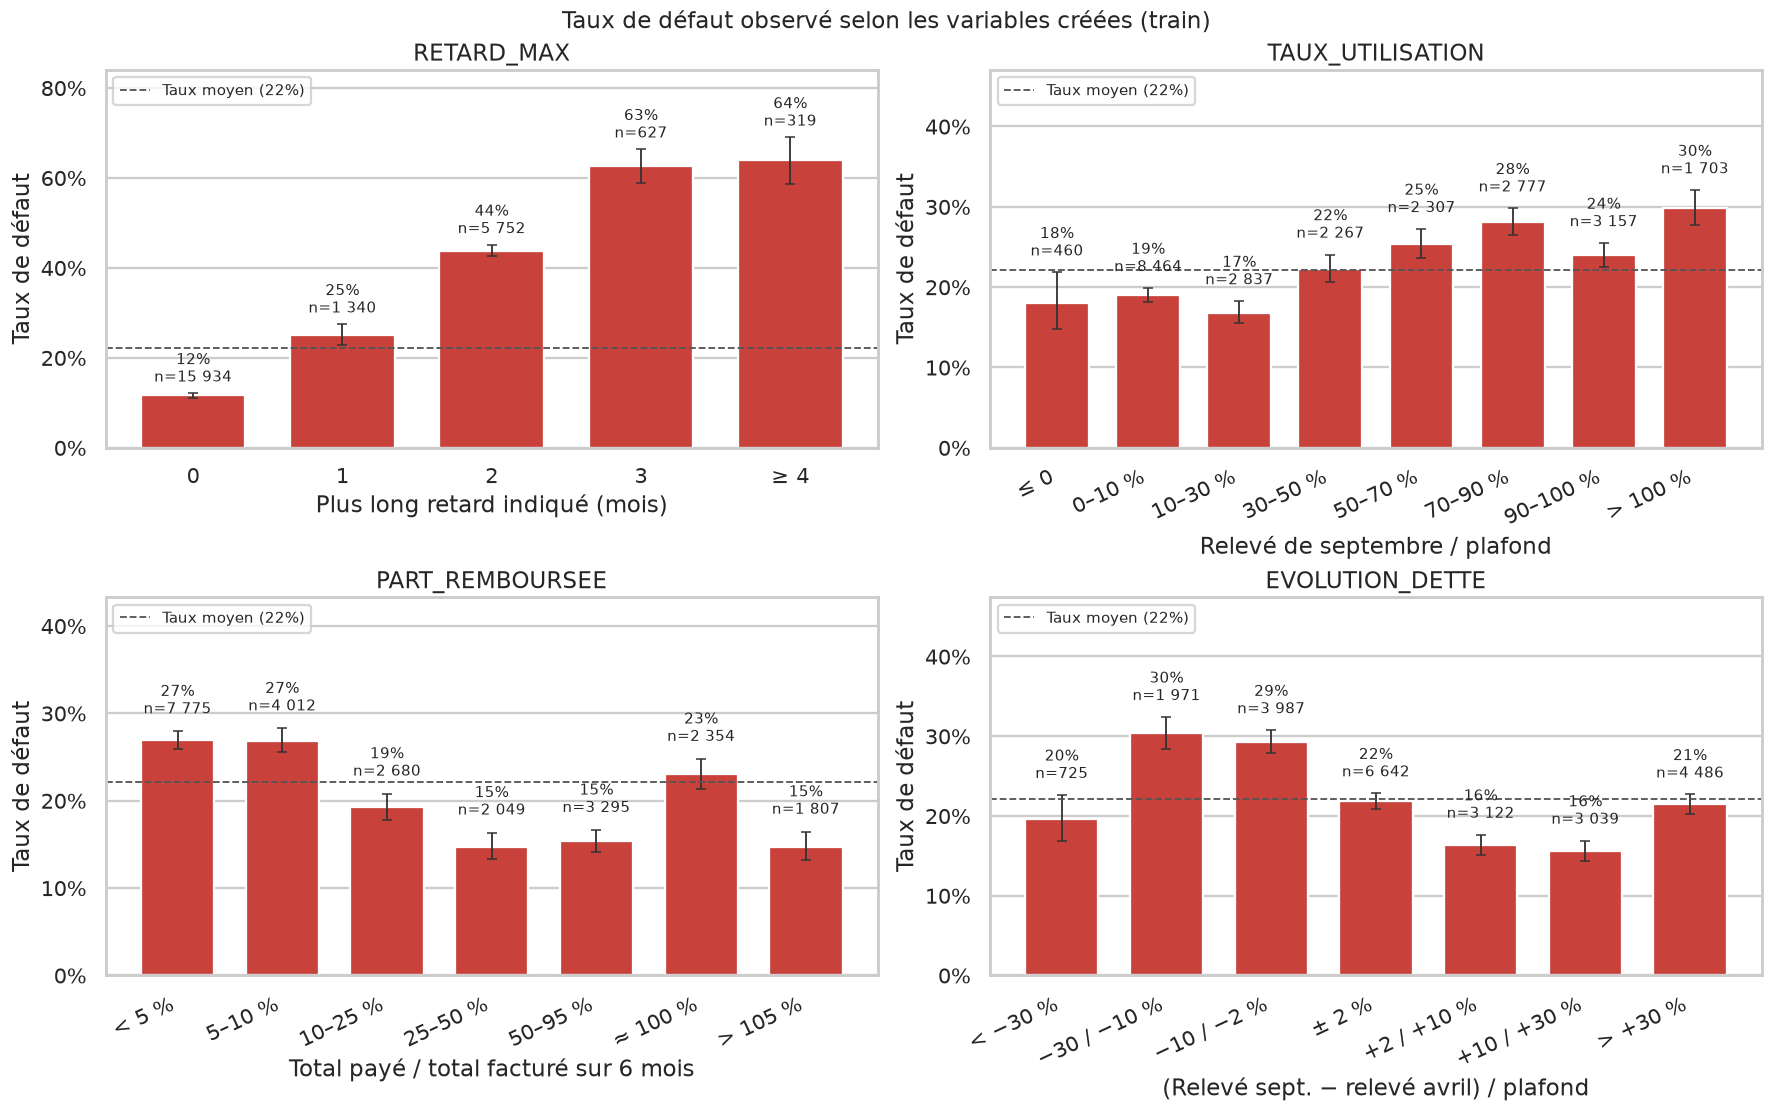

Explication : sans retard positif (`RETARD_MAX = 0`), le taux de défaut est de 11,6 % ; il atteint 43,8 % dès un retard maximal de 2 mois. Pour la part remboursée, il vaut 26,9 % sous 5 % contre 23,0 % autour de 100 %. Pour l’utilisation du plafond, il va de 16,8 % à 29,8 % selon la tranche. Ces taux bruts décrivent des associations ; la cross-validation dira ce que les variables ajoutent aux colonnes existantes.

In [19]:
_tranches_features = {
    'RETARD_MAX': (X_train_plus['RETARD_MAX'].clip(upper=4),
                   None, ['0', '1', '2', '3', '≥ 4'], 'Plus long retard indiqué (mois)'),
    'TAUX_UTILISATION': (X_train_plus['TAUX_UTILISATION'],
                         [-np.inf, 0, .1, .3, .5, .7, .9, 1.0, np.inf],
                         ['≤ 0', '0–10 %', '10–30 %', '30–50 %', '50–70 %', '70–90 %', '90–100 %', '> 100 %'],
                         'Relevé de septembre / plafond'),
    'PART_REMBOURSEE': (X_train_plus['PART_REMBOURSEE'],
                        [-np.inf, .05, .1, .25, .5, .95, 1.05, np.inf],
                        ['< 5 %', '5–10 %', '10–25 %', '25–50 %', '50–95 %', '≈ 100 %', '> 105 %'],
                        'Total payé / total facturé sur 6 mois'),
    'EVOLUTION_DETTE': (X_train_plus['EVOLUTION_DETTE'],
                        [-np.inf, -.3, -.1, -.02, .02, .1, .3, np.inf],
                        ['< −30 %', '−30 / −10 %', '−10 / −2 %', '± 2 %', '+2 / +10 %', '+10 / +30 %', '> +30 %'],
                        '(Relevé sept. − relevé avril) / plafond'),
}
taux_tranches = {}
fig, axes = plt.subplots(2, 2, figsize=(16, 10), layout='constrained')
for ax, (nom, (valeurs, bornes, etiquettes, xlabel)) in zip(axes.flat, _tranches_features.items()):
    groupes = valeurs if bornes is None else pd.cut(valeurs, bornes, labels=etiquettes, right=False)
    resume = y_train.groupby(groupes, observed=True).agg(Clients='size', Defauts='sum')
    resume['Taux'] = resume.Defauts / resume.Clients
    taux_tranches[nom] = resume
    bas, haut = intervalle_wilson(resume.Defauts, resume.Clients)
    x = np.arange(len(resume))
    ax.bar(x, resume.Taux, color=ROUGE, width=.7)
    ax.errorbar(x, resume.Taux, yerr=[resume.Taux - bas, haut - resume.Taux], fmt='none',
                ecolor='#333333', capsize=3, lw=1.2)
    for xi, (t, n, h) in enumerate(zip(resume.Taux, resume.Clients, haut)):
        ax.text(xi, h + .015, f'{t:.0%}\nn={n:,}'.replace(',', ' '), ha='center', va='bottom', fontsize=9.5)
    ax.axhline(taux_reference, color='#555555', ls='--', lw=1.2, label=f'Taux moyen ({taux_reference:.0%})')
    libelles = etiquettes if bornes is not None else [etiquettes[int(v)] for v in resume.index]
    ax.set_xticks(x, libelles, rotation=25 if len(x) > 5 else 0, ha='right' if len(x) > 5 else 'center')
    ax.set(title=nom_feature(nom) if 'nom_feature' in globals() else nom, xlabel=xlabel,
           ylabel='Taux de défaut', ylim=(0, min(1, float(haut.max()) + .15)))
    ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.grid(axis='x', visible=False)
    ax.legend(loc='upper left', fontsize=10)
fig.suptitle('Taux de défaut observé selon les variables créées (train)', fontsize=15)
plt.show()

_rm, _pr, _tu = taux_tranches['RETARD_MAX'], taux_tranches['PART_REMBOURSEE'], taux_tranches['TAUX_UTILISATION']
display(Markdown(
    f'Explication : sans retard positif (`RETARD_MAX = 0`), le taux de défaut est de {_rm.Taux.iloc[0]:.1%} ; '
    f'il atteint {_rm.Taux.iloc[2]:.1%} dès un retard maximal de 2 mois. '
    f'Pour la part remboursée, il vaut {_pr.Taux.iloc[0]:.1%} sous 5 % contre {_pr.loc["≈ 100 %", "Taux"]:.1%} '
    f'autour de 100 %. Pour l’utilisation du plafond, il va de {_tu.Taux.min():.1%} à {_tu.Taux.max():.1%} selon la tranche. '
    'Ces taux bruts décrivent des associations ; la cross-validation dira ce que les variables ajoutent aux colonnes existantes.'
))

- `RETARD_MAX` est la variable la plus nette : le taux de défaut passe de 12 % sans retard positif à 25 % pour un retard maximal d'un mois, 44 % pour deux mois et plus de 60 % au-delà. Elle résume la gravité de l'historique en une colonne.
- `TAUX_UTILISATION` monte plus doucement, d'environ 17-19 % pour un relevé faible devant le plafond à 30 % quand le relevé dépasse le plafond.
- `PART_REMBOURSEE` n'est pas monotone : le risque est élevé quand le client paie moins de 10 % de ses relevés (27 %), bas entre 25 % et 95 % (15 %), puis remonte autour de 100 %. Ce pic correspond en partie à la convention de calcul (part = 1 quand la somme des relevés est nulle ou négative) : il mélange des clients sans dette et des clients qui soldent tout. Un modèle à base d'arbres peut exploiter cette forme, pas une logistic regression.
- `EVOLUTION_DETTE` est contre-intuitive : une dette légèrement en baisse depuis avril (−30 % à −2 % du plafond) est associée à un taux plus élevé (≈ 30 %) qu'une dette en hausse (≈ 16 %). Une baisse des relevés peut refléter un compte qu'on cesse d'utiliser avant l'incident ; ce n'est qu'une association.

Toutes les idées de variables ne se valent pas, et certaines n'ont pas la forme attendue. C'est le modèle qui dira lesquelles servent vraiment.

## 2.10 Bilan de la préparation

Après retrait de 35 répétitions exactes, on garde 29 965 lignes. Le one-hot encoding donne 26 features, puis les cinq ajouts portent le total à 31. Les contrôles ci-dessous vérifient les dimensions, l’alignement entre `X` et `y`, et l’absence de valeurs manquantes ou infinies.

Ces contrôles ne prouvent pas que toutes les données sont correctes : les codes non documentés et les conventions des ratios restent à confirmer avec le métier.

In [20]:
assert len(df_source) == len(df_brut)
assert len(X_train) + len(X_test) == len(df)
assert X_train.index.equals(y_train.index) and X_test.index.equals(y_test.index)
assert set(X_train.index).isdisjoint(X_test.index)
assert 'DEFAULT' not in X_train_plus and 'ID' not in X_train_plus
assert not X_train_plus.isna().any().any() and not X_test_plus.isna().any().any()
assert np.isfinite(X_train_plus.to_numpy()).all() and np.isfinite(X_test_plus.to_numpy()).all()
display(pd.DataFrame({
    'Version': ['Variables encodées', 'Variables encodées + feature engineering'],
    'Clients entraînement': [len(X_train), len(X_train_plus)],
    'Clients test réservé': [len(X_test), len(X_test_plus)],
    'Nombre de features': [X_train.shape[1], X_train_plus.shape[1]],
}))

,Version,Clients entraînement,Clients test réservé,Nombre de features
0,Variables encodées,23972,5993,26
1,Variables encodées + feature engineering,23972,5993,31


<a id="partie-3"></a>
# Partie 3 - Modèles et évaluation

On commence par les baselines et des diagnostics de réglage pour comprendre les familles de modèles. La comparaison après tuning repose sur la nested CV avec cinq outer folds et cinq inner folds. On choisit ensuite le threshold sur le train, puis on évalue le modèle retenu sur le test réservé.


## 3.1 Scores, métriques et nested CV

### 3.1.1 Score, threshold et prédiction

La plupart des modèles ne répondent pas directement 0 ou 1. Ils donnent un score de risque, en général une probabilité de défaut entre 0 et 1. On transforme ensuite ce score en décision avec un threshold : par défaut, « défaut » si la probabilité dépasse 0,5.

Ce threshold est un choix, pas une propriété du modèle. On verra en § 3.4.5 qu'il est souvent utile de le changer.

### 3.1.2 Confusion matrix et métriques

En comparant les prédictions à la réalité, on obtient quatre cas :

| | Prédit : pas de défaut | Prédit : défaut |
|---|---|---|
| Réel : pas de défaut | Vrai négatif (VN) | Faux positif (FP), une fausse alerte |
| Réel : défaut | Faux négatif (FN), un défaut raté | Vrai positif (VP), un défaut détecté |

| Métrique | Calcul | Question posée |
|---|---|---|
| Accuracy | (VP + VN) / total | Quelle part des prédictions est juste ? |
| precision | VP / (VP + FP) | Quand le modèle crie « défaut », a-t-il raison ? |
| recall | VP / (VP + FN) | Quelle part des vrais défauts le modèle trouve-t-il ? |
| F1 | 2 × precision × recall / (precision + recall) | Un compromis entre precision et recall |
| AUC | voir ci-dessous | Le modèle classe-t-il bien les clients du plus risqué au moins risqué ? |

L'AUC (aire sous la courbe ROC) ne dépend pas du threshold. Elle répond à la question : si je prends au hasard un client en défaut et un client sans défaut, quelle est la probabilité que le modèle donne un score plus élevé au premier ? 0,5 = pas mieux que le hasard, 1 = parfait.

Avec seulement 22 % de défauts, l'accuracy est trompeuse : répondre toujours « pas de défaut » donne déjà 78 %. On utilisera donc l'AUC comme métrique principale pour comparer les méthodes, et le recall, la precision et le F1 pour juger les décisions.

### 3.1.3 Nested CV et prédictions OOF

Le protocole de comparaison est la nested CV : cinq outer folds mesurent la performance, tandis que cinq inner folds règlent les hyperparamètres à l’intérieur de chaque train externe. Les lignes sont mélangées avec la seed 42 et les proportions des classes sont conservées. Le détail des effectifs est donné en 2.7 et en 3.4.2.

Les courbes de pré-réglage de la section 3.3 sont des diagnostics sur le train ; elles ne constituent pas le classement final des modèles. Les prédictions OOF donnent un score à chaque observation à partir d’un modèle qui ne l’a pas utilisée pour son fit. Après le tuning final, elles servent à choisir le threshold. Ce choix utilise le train et sera évalué sur le test réservé.

### 3.1.4 Fonction d’évaluation

La fonction `evaluer` calcule ces diagnostics, les métriques et les matrices de confusion. Le tableau de nested CV de la section 3.4.2 reste la référence pour comparer les familles après tuning.


In [21]:
# Même présentation pour toutes les figures de prédiction.
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter, MaxNLocator
import textwrap
sns.set_theme(style='whitegrid', context='notebook', font_scale=1.1)
plt.rcParams.update({'figure.dpi': 120, 'axes.titlesize': 14, 'axes.labelsize': 12,
                     'xtick.labelsize': 11, 'ytick.labelsize': 11, 'legend.fontsize': 10})
ORANGE = '#D88A25'
NOMS_MODELES = {'Régression logistique': 'Logistic regression', 'Bayésien naïf': 'Naive Bayes',
                'Forêt aléatoire': 'Random forest', 'Réseau de neurones': 'MLP',
                'Vote (logistique + forêt + boosting du pli)': 'Soft voting'}
NOMS_FEATURES = {'LIMIT_BAL': 'Plafond de crédit', 'AGE': 'Âge',
    'NB_MOIS_RETARD': 'Nombre de mois avec retard', 'RETARD_MAX': 'Retard maximum',
    'TAUX_UTILISATION': 'Utilisation du plafond', 'PART_REMBOURSEE': 'Part remboursée',
    'EVOLUTION_DETTE': 'Évolution des relevés'}
for _k, _mois in enumerate(['septembre', 'août', 'juillet', 'juin', 'mai', 'avril'], 1):
    NOMS_FEATURES[f'PAY_{_k}'] = f'Statut de remboursement - {_mois}'
    NOMS_FEATURES[f'BILL_AMT{_k}'] = f'Relevé - {_mois}'
    NOMS_FEATURES[f'PAY_AMT{_k}'] = f'Paiement - {_mois}'

def nom_feature(nom):
    return f'{NOMS_FEATURES.get(nom, nom)} ({nom})' if nom in NOMS_FEATURES else nom

def matrice_lisible(y_vrai, prediction, ax, titre):
    cm = confusion_matrix(y_vrai, prediction, labels=[0, 1])
    pct = np.divide(cm, cm.sum(axis=1, keepdims=True), out=np.zeros_like(cm, dtype=float),
                    where=cm.sum(axis=1, keepdims=True) != 0)
    annotations = np.array([[format_fr(f'{cm[i,j]:,}\n{pct[i,j]:.1%} de la ligne')
                             for j in range(2)] for i in range(2)])
    # Couleur = part de la ligne : la case « défauts détectés » se lit comme le recall
    sns.heatmap(pct, annot=annotations, fmt='', cmap='Blues', vmin=0, vmax=1, cbar=False, square=True,
                linewidths=2, annot_kws={'fontsize': 12},
                xticklabels=['Sans défaut', 'Défaut'], yticklabels=['Sans défaut', 'Défaut'], ax=ax)
    ax.set(title=titre, xlabel='Classe prédite', ylabel='Classe réelle')
    ax.tick_params(axis='y', rotation=0)
    return cm

def barres_auc(ax, scores, titre, ecarts=None, origine=.5):
    """Lollipop des ROC-AUC : la tige part de 0,5 (hasard), le point porte la valeur."""
    scores = scores.sort_values()
    y = np.arange(len(scores))
    meilleur = scores.idxmax()
    references = [n for n in scores.index if n.startswith(('Naïf', 'Règle'))]
    couleurs = [ROUGE if n == meilleur else ('#8C8C8C' if n in references else BLEU) for n in scores.index]
    ax.hlines(y, origine, scores.values, color='#C9D1DB', lw=2.5, zorder=1)
    erreurs = np.zeros(len(scores)) if ecarts is None else ecarts.reindex(scores.index).fillna(0).values
    if ecarts is not None:
        ax.errorbar(scores.values, y, xerr=erreurs, fmt='none', ecolor='#444444', capsize=3, lw=1.2, zorder=2)
    ax.scatter(scores.values, y, s=120, color=couleurs, edgecolor='white', linewidth=1.5, zorder=3)
    for yi, valeur, erreur in zip(y, scores.values, erreurs):
        ax.text(valeur + erreur + .006, yi, f'{valeur:.3f}', va='center', fontsize=11)
    ax.set_yticks(y, [NOMS_MODELES.get(x, x) for x in scores.index])
    ax.set(xlim=(origine - .01, min(1.02, max(.84, float(max(scores.values + erreurs)) + .05))),
           xlabel='ROC-AUC (0,5 = hasard)', title=titre)
    ax.axvline(origine, color='grey', ls=':', lw=1)
    ax.grid(axis='y', visible=False)
    sns.despine(ax=ax)

def courbe_reglage(ax, valeurs, xlabel, titre, log=False):
    x = np.array(list(valeurs), dtype=float)
    y = np.array(list(valeurs.values()))
    ax.plot(x,y,color=BLEU,marker='o',lw=2)
    if log: ax.set_xscale('log')
    for a,b in zip(x,y): ax.annotate(f'{b:.3f}',(a,b),xytext=(0,9),textcoords='offset points',ha='center')
    ax.margins(x=.1,y=.3)
    ax.set(xlabel=xlabel,ylabel='ROC-AUC OOF (5 folds)',title=titre)
    sns.despine(ax=ax)

cv = plis_cv(y_train, k=5, seed=SEED)

resultats = {}   # scores de chaque méthode
scores_oof = {}  # scores de risque prédits en cross-validation (pour tracer les courbes ROC)


def calculer_metriques(y_vrai, score, seuil):
    prediction = (score >= seuil).astype(int)
    return {
        'AUC': roc_auc_score(y_vrai, score),
        'Accuracy': accuracy_score(y_vrai, prediction),
        'Precision': precision_score(y_vrai, prediction, zero_division=0),
        'Recall': recall_score(y_vrai, prediction),
        'F1': f1_score(y_vrai, prediction),
    }


def evaluer(nom, modele, X=None, y=None, afficher=True):
    X = X_train if X is None else X
    y = y_train if y is None else y
    debut = time.time()

    # Score de risque pour chaque client, prédit par cross-validation
    if hasattr(modele, 'predict_proba'):
        score = cross_val_predict(modele, X, y, cv=cv, method='predict_proba', n_jobs=-1)[:, 1]
        seuil = 0.5
    else:  # certains modèles (SVM) donnent un score sans probabilité ; leur seuil naturel est 0
        score = cross_val_predict(modele, X, y, cv=cv, method='decision_function', n_jobs=-1)
        seuil = 0.0

    metriques = calculer_metriques(y, score, seuil)
    metriques['Temps (s)'] = time.time() - debut
    resultats[nom] = metriques
    scores_oof[nom] = score

    if afficher:
        print(nom)
        for m, v in metriques.items():
            print(f'  {m:<10}: {v:.3f}')
        fig, ax = plt.subplots(figsize=(6.4, 5.2), layout='constrained')
        cm = matrice_lisible(y, (score >= seuil).astype(int), ax,
                             textwrap.fill(NOMS_MODELES.get(nom,nom), 32))
        plt.show()
        display(Markdown(
            f'Explication : La ROC-AUC vaut {metriques["AUC"]:.3f} sur les prédictions OOF. '
            f'Au threshold {seuil:g}, le modèle détecte {cm[1,1]:,} défauts '
            f'et en manque {cm[1,0]:,} (recall {metriques["Recall"]:.1%}). '
            f'Il émet {cm[0,1]:,} fausses alertes ; la precision vaut {metriques["Precision"]:.1%}. '
            'Les pourcentages de la matrice se lisent par ligne : ils comparent les décisions pour une même classe réelle.'
        ))


## 3.2 Baselines

Avant d'utiliser du machine learning, on mesure ce que donnent deux approches sans apprentissage. Une méthode n'a d'intérêt que si elle fait clairement mieux.

### 3.2.1 Le modèle naïf

Il répond toujours « pas de défaut », la classe la plus fréquente.

Naïf (toujours 0)
  AUC       : 0.500
  Accuracy  : 0.779
  Precision : 0.000
  Recall    : 0.000
  F1        : 0.000
  Temps (s) : 1.009


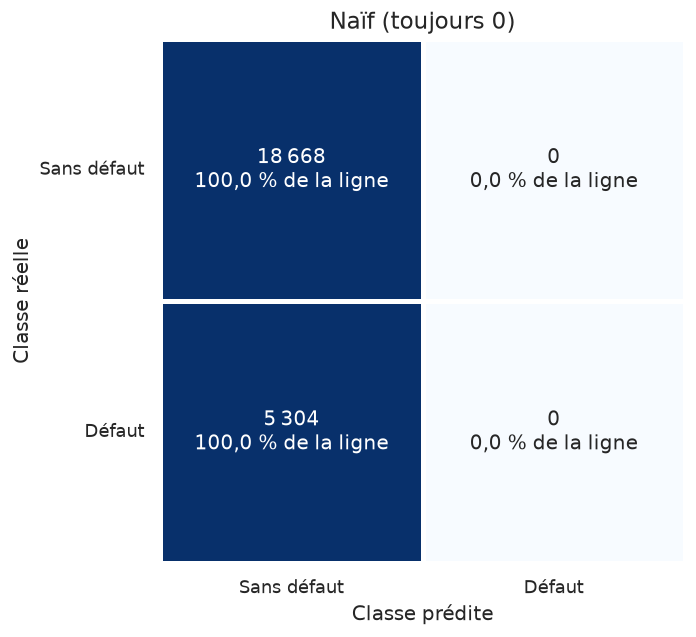

Explication : La ROC-AUC vaut 0,500 sur les prédictions OOF. Au threshold 0,5, le modèle détecte 0 défauts et en manque 5 304 (recall 0,0 %). Il émet 0 fausses alertes ; la precision vaut 0,0 %. Les pourcentages de la matrice se lisent par ligne : ils comparent les décisions pour une même classe réelle.

In [22]:
evaluer('Naïf (toujours 0)', DummyClassifier(strategy='most_frequent'))

77,9 % d'accuracy sans détecter un seul défaut (recall = 0). C'est la démonstration que l'accuracy seule ne suffit pas. Son AUC de 0,5 dit la vérité : il ne sait pas distinguer les clients.

### 3.2.2 Une règle écrite à la main

L'exploration a montré que le retard de paiement en septembre (`PAY_1`) est le meilleur indice d'un défaut. Une règle simple qu'un banquier pourrait écrire sans ordinateur : « défaut si le client a au moins un mois de retard en septembre ». Pour l'AUC, on utilise directement `PAY_1` comme score de risque.

In [23]:
score_regle = X_train['PAY_1'].values
metriques_regle = calculer_metriques(y_train, score_regle, seuil=1)
metriques_regle['Temps (s)'] = 0.0
resultats['Règle PAY_1 ≥ 1'] = metriques_regle
scores_oof['Règle PAY_1 ≥ 1'] = score_regle

for m, v in metriques_regle.items():
    print(f'  {m:<10}: {v:.3f}')

  AUC       : 0.690
  Accuracy  : 0.781
  Precision : 0.505
  Recall    : 0.520
  F1        : 0.512
  Temps (s) : 0.000


La règle fait déjà bien mieux que le modèle naïf : elle détecte 52 % des défauts, et une alerte sur deux est juste (precision de 50,5 %). Son accuracy (78,1 %) est pourtant presque la même que celle du modèle naïf, alors qu'elle est bien plus utile : encore une preuve que l'accuracy juge mal.

Son AUC de 0,690 est le niveau à battre. Une méthode de machine learning qui ferait moins bien qu'une règle d'une ligne n'aurait aucun intérêt.

## 3.3 Comparaison initiale des modèles

Ces cellules font comprendre les familles de modèles. Les grilles sur `C`, `k`, la profondeur ou le nombre d'arbres ne sont pas le choix final : ce choix est le tableau de la section 3.4. Le SVM montré ici n'est pas repris dans la recherche nested, parce que 1 250 ajustements d'un noyau RBF ne sont pas exécutables sur cet échantillon.

On teste les méthodes de la plus simple à la plus élaborée. Pour chacune : l'idée, une image, les réglages, puis les résultats.

### 3.3.1 Logistic regression

L'idée. Le modèle donne un poids à chaque variable. Il additionne « poids × valeur » pour toutes les variables, puis transforme ce total en probabilité entre 0 et 1 avec la fonction sigmoïde (une courbe en S). Pendant l'entraînement, il cherche les poids qui expliquent le mieux les défauts observés.

Une image. Une balance : chaque variable pèse plus ou moins lourd du côté « défaut » ou du côté « pas de défaut », et la position de l'aiguille donne la probabilité.

Ce qu'il faut savoir.

- C'est un modèle linéaire : il suppose que chaque variable augmente ou diminue le risque de façon régulière.
- Il a besoin de variables à la même échelle, d'où la standardization (`StandardScaler`) placée juste avant dans un pipeline. Le pipeline enchaîne les deux étapes et recalcule la standardization sur les seules données d'entraînement de chaque pli, ce qui évite toute fuite d'information.
- Réglage principal : `C`, l'inverse de la régularisation. La régularisation empêche les poids de devenir trop grands, ce qui limite le overfitting. Petit `C` = modèle très contraint, grand `C` = modèle libre.

Voyons la sigmoïde :

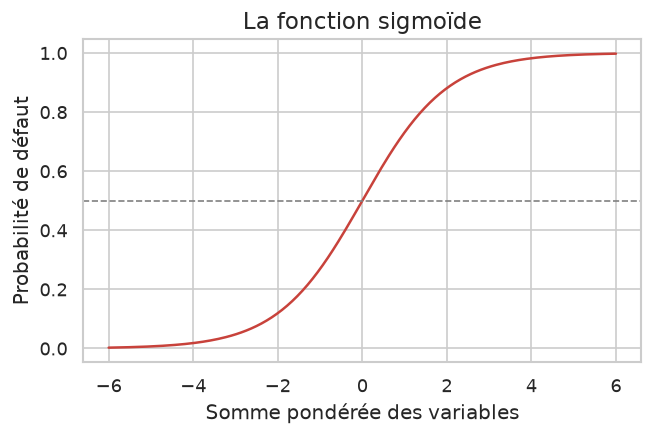

Explication : Un score linéaire de 0 donne une probabilité de 50 % ; un score de 2 donne environ 88 %, et -2 environ 12 %. Cette transformation produit un score entre 0 et 1 ; la calibration devra encore être vérifiée.

In [24]:
z = np.linspace(-6, 6, 200)
plt.figure(figsize=(6, 3.5))
plt.plot(z, 1 / (1 + np.exp(-z)), color=ROUGE)
plt.axhline(0.5, color='grey', ls='--', lw=1)
plt.xlabel('Somme pondérée des variables')
plt.ylabel('Probabilité de défaut')
plt.title('La fonction sigmoïde')
plt.show()
display(Markdown('Explication : Un score linéaire de 0 donne une probabilité de 50 % ; '
                 'un score de 2 donne environ 88 %, et -2 environ 12 %. '
                 'Cette transformation produit un score entre 0 et 1 ; la calibration devra encore être vérifiée.'))


Plus la somme pondérée est grande, plus la probabilité se rapproche de 1. Une somme de 0 donne exactement 0,5.

Choisir `C`. On teste plusieurs valeurs et on compare l'AUC en cross-validation.

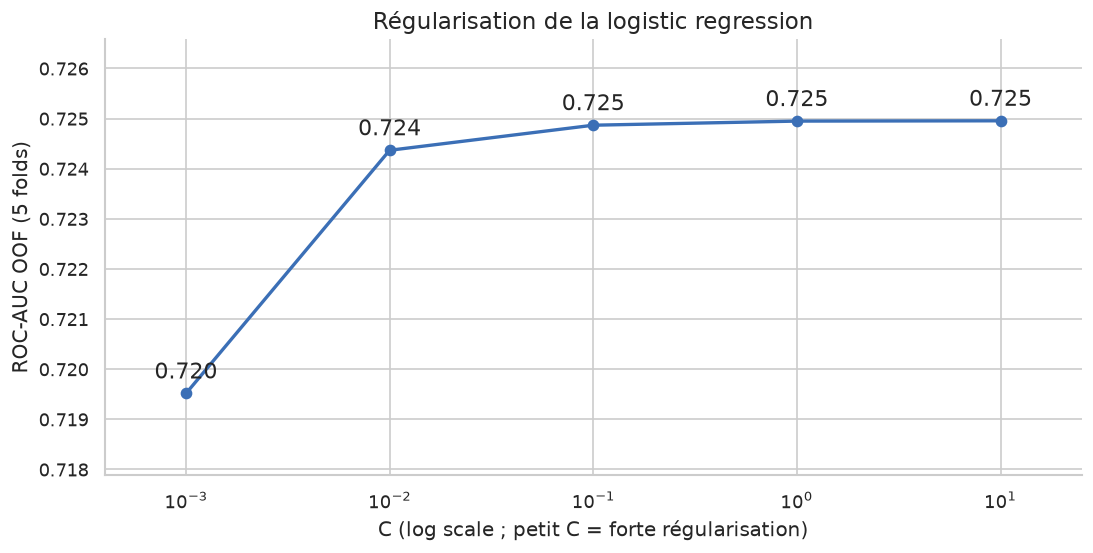

Explication : la ROC-AUC va de 0,720 (C = 0,001, régularisation la plus forte) à 0,725. Renforcer très fortement la régularisation pénalise le classement ; au-delà de C = 0,1 la courbe est presque plate. On garde C = 0,1 pour la comparaison initiale. Une courbe plate ne prouve pas l’absence d’overfitting : ce point est examiné plus loin avec les scores train et validation.

In [25]:
auc_par_C = {}
for C in [0.001, 0.01, 0.1, 1, 10]:
    modele = make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=2000))
    score = cross_val_predict(modele, X_train, y_train, cv=cv, method='predict_proba', n_jobs=-1)[:, 1]
    auc_par_C[C] = roc_auc_score(y_train, score)

fig, ax = plt.subplots(figsize=(9,4.5), layout='constrained')
courbe_reglage(ax, auc_par_C, 'C (log scale ; petit C = forte régularisation)', 'Régularisation de la logistic regression', log=True)
plt.show()
_C_min = min(auc_par_C, key=auc_par_C.get)
display(Markdown(f'Explication : la ROC-AUC va de {auc_par_C[_C_min]:.3f} (C = {_C_min:g}, régularisation la plus forte) '
    f'à {max(auc_par_C.values()):.3f}. Renforcer très fortement la régularisation pénalise le classement ; au-delà de C = 0,1 '
    'la courbe est presque plate. On garde C = 0,1 pour la comparaison initiale. Une courbe plate ne prouve pas l’absence '
    'd’overfitting : ce point est examiné plus loin avec les scores train et validation.'))

Régression logistique
  AUC       : 0.725
  Accuracy  : 0.810
  Precision : 0.706
  Recall    : 0.239
  F1        : 0.357
  Temps (s) : 0.174


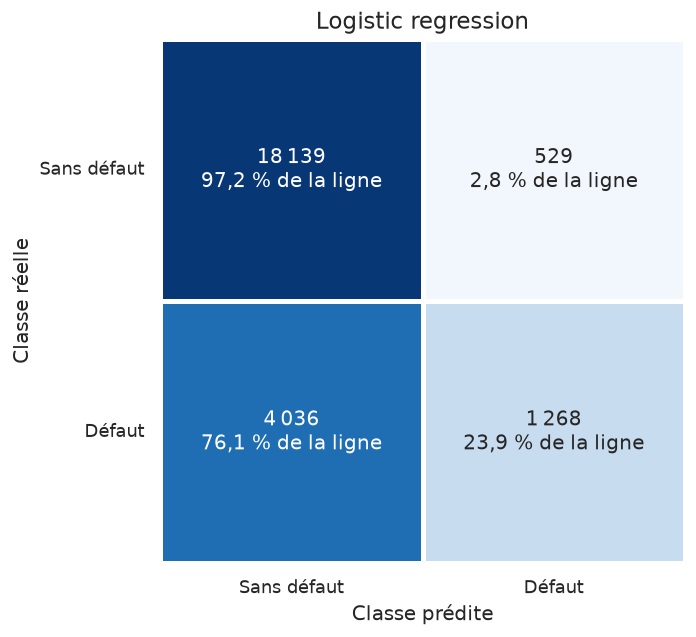

Explication : La ROC-AUC vaut 0,725 sur les prédictions OOF. Au threshold 0,5, le modèle détecte 1 268 défauts et en manque 4 036 (recall 23,9 %). Il émet 529 fausses alertes ; la precision vaut 70,6 %. Les pourcentages de la matrice se lisent par ligne : ils comparent les décisions pour une même classe réelle.

In [26]:
modele_lr = make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=2000))
evaluer('Régression logistique', modele_lr)

Lire les poids. L'avantage de la régression logistique est qu'on peut lire ce qu'elle a appris. Comme les variables sont standardisées, on peut comparer les poids entre eux : un poids positif augmente le risque, un poids négatif le diminue.

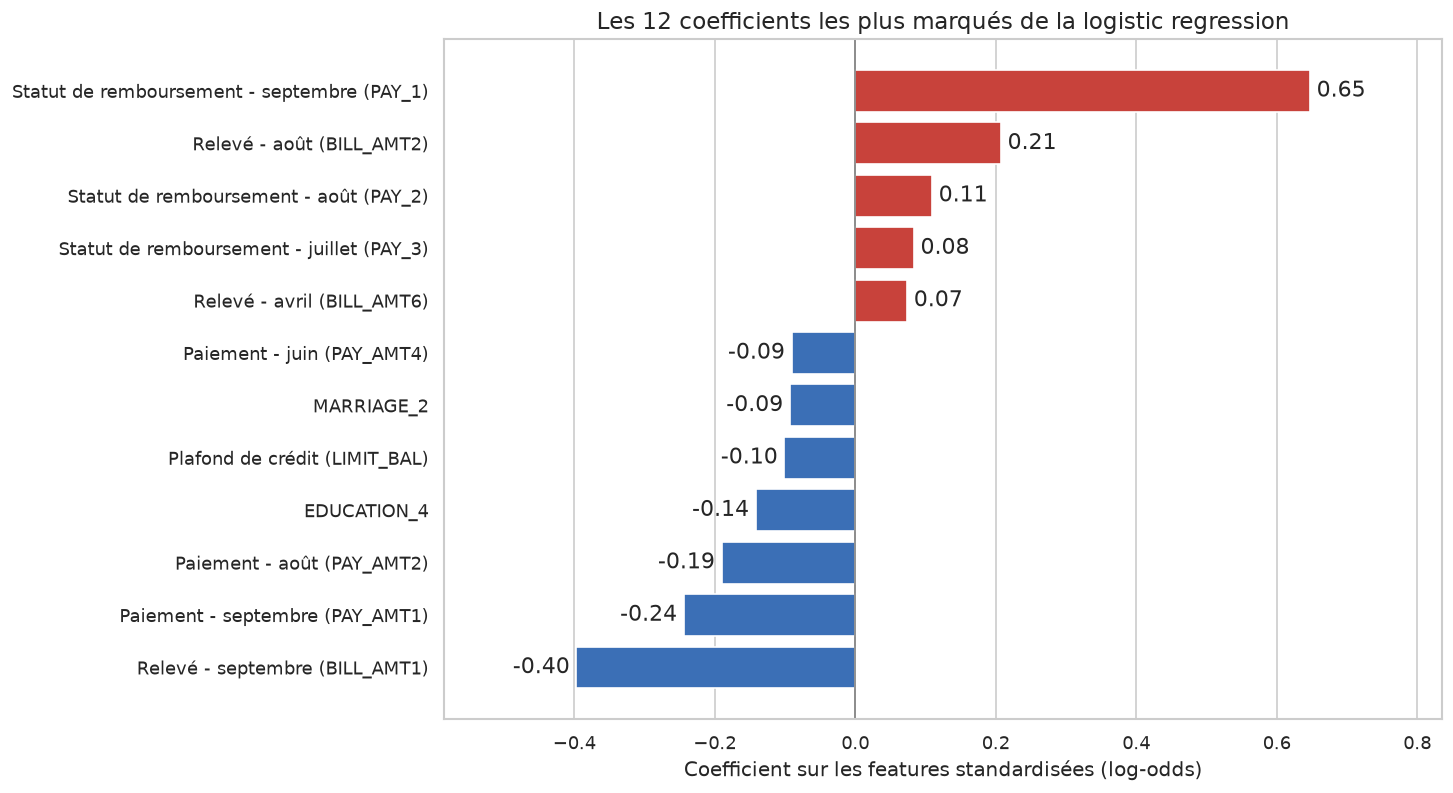

Explication : Le coefficient le plus positif est `PAY_1` (0,65), le plus négatif est `BILL_AMT1` (-0,40). Le signe indique le sens de variation du score, à autres features fixées. Ces nombres portent sur les log-odds après standardization, pas sur des points de probabilité ni sur un effet causal.

In [27]:
modele_lr.fit(X_train, y_train)
poids = pd.Series(modele_lr[-1].coef_[0], index=X_train.columns).sort_values()
poids_visibles = poids.loc[poids.abs().nlargest(12).index].sort_values()
fig, ax = plt.subplots(figsize=(12,6.5), layout='constrained')
bars=ax.barh([nom_feature(c) for c in poids_visibles.index],poids_visibles,
             color=[ROUGE if x>0 else BLEU for x in poids_visibles])
ax.bar_label(bars,fmt='%.2f',padding=4)
ax.axvline(0,color='grey',lw=1)
ax.margins(x=.18)
ax.set(xlabel='Coefficient sur les features standardisées (log-odds)',
       title='Les 12 coefficients les plus marqués de la logistic regression')
ax.grid(axis='y',visible=False)
plt.show()
display(Markdown(f'Explication : Le coefficient le plus positif est `{poids.idxmax()}` '
    f'({poids.max():.2f}), le plus négatif est `{poids.idxmin()}` ({poids.min():.2f}). '
    'Le signe indique le sens de variation du score, à autres features fixées. '
    'Ces nombres portent sur les log-odds après standardization, pas sur des points de probabilité ni sur un effet causal.'))


Les résultats. Avec une AUC de 0,725, la régression logistique bat nettement la règle (0,690). Mais au threshold de 0,5, elle ne détecte que 24 % des défauts. Elle est prudente : quand elle annonce un défaut, elle a raison dans 71 % des cas.

Ce que disent les poids.

- `PAY_1` a de loin le plus gros poids positif : un retard en septembre augmente fortement le risque. Les statuts des mois précédents vont dans le même sens, avec des poids de plus en plus faibles quand on remonte dans le temps.
- `LIMIT_BAL` et les montants payés (`PAY_AMT1`, `PAY_AMT2`) ont des poids négatifs : un plafond élevé et de gros remboursements protègent du défaut.
- Un piège à connaître : `BILL_AMT1` a un fort poids négatif et `BILL_AMT2` un poids positif. Cela ne veut pas dire que la facture de septembre protège et que celle d'août expose. Ces deux variables sont presque identiques (corrélation de 0,95), et le modèle utilise surtout l'écart entre les deux. Quand des variables sont très corrélées, il ne faut pas lire leurs poids un par un.

La limite. C'est un modèle linéaire : il suppose que chaque mois de retard ajoute la même quantité de risque. Or l'exploration montrait un risque plat pour `PAY_1` = -2, -1 et 0, puis un saut brutal dès un mois de retard. Les features construites en 2.9 servent à l'aider ; leur apport est mesuré en 3.4.1.

### 3.3.2 K-nearest neighbors (KNN)

L'idée. Pour un nouveau client, on cherche les *k* clients de l'entraînement qui lui ressemblent le plus, et on regarde combien d'entre eux ont fait défaut. Si 12 de ses 50 voisins sont en défaut, sa probabilité est de 12/50 = 0,24.

Une image. « Dis-moi qui te ressemble, je te dirai qui tu es. »

Ce qu'il faut savoir.

- Il n'y a pas vraiment d'apprentissage : le modèle mémorise tous les clients et fait tout le travail au moment de la prédiction, ce qui le rend lent sur de grosses bases.
- Il mesure des distances entre clients, donc la standardization est obligatoire. Sans elle, une différence de 10 000 NT$ de plafond écraserait une différence de 10 ans d'âge.
- Réglage principal : k, le nombre de voisins. Petit k : le modèle suit chaque cas particulier et surapprend. Grand k : il fait des moyennes sur beaucoup de clients et devient trop grossier.

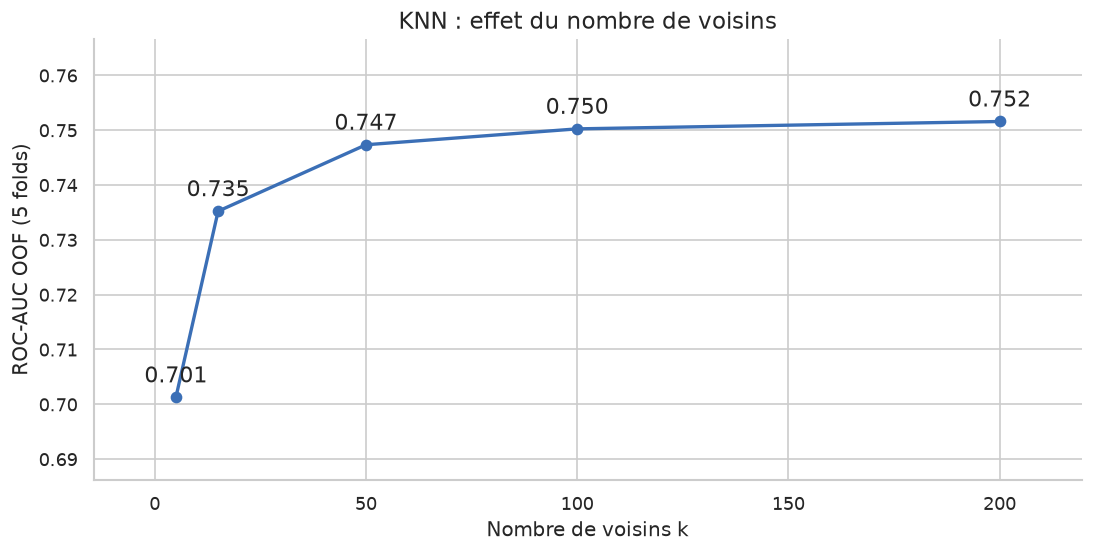

Explication : le meilleur k testé est 200, avec une ROC-AUC de 0,752, contre 0,701 à k = 5. Un petit k rend la prédiction sensible à quelques voisins ; élargir le voisinage améliore l’AUC, puis le gain ralentit après 100 voisins. Ce choix reste exploratoire : la nested cross-validation séparera ensuite le tuning de l’évaluation.

In [28]:
auc_par_k = {}
for k in [5, 15, 50, 100, 200]:
    modele = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    score = cross_val_predict(modele, X_train, y_train, cv=cv, method='predict_proba', n_jobs=-1)[:, 1]
    auc_par_k[k] = roc_auc_score(y_train, score)

K_CHOISI=max(auc_par_k,key=auc_par_k.get)
fig,ax=plt.subplots(figsize=(9,4.5),layout='constrained')
courbe_reglage(ax,auc_par_k,'Nombre de voisins k','KNN : effet du nombre de voisins')
plt.show()
display(Markdown(f'Explication : le meilleur k testé est {K_CHOISI}, avec une ROC-AUC de '
    f'{auc_par_k[K_CHOISI]:.3f}, contre {auc_par_k[min(auc_par_k)]:.3f} à k = {min(auc_par_k)}. Un petit k rend la prédiction '
    'sensible à quelques voisins ; élargir le voisinage améliore l’AUC, puis le gain ralentit après 100 voisins. '
    'Ce choix reste exploratoire : la nested cross-validation séparera ensuite le tuning de l’évaluation.'))

KNN (k=200)
  AUC       : 0.752
  Accuracy  : 0.804
  Precision : 0.663
  Recall    : 0.233
  F1        : 0.345
  Temps (s) : 0.679


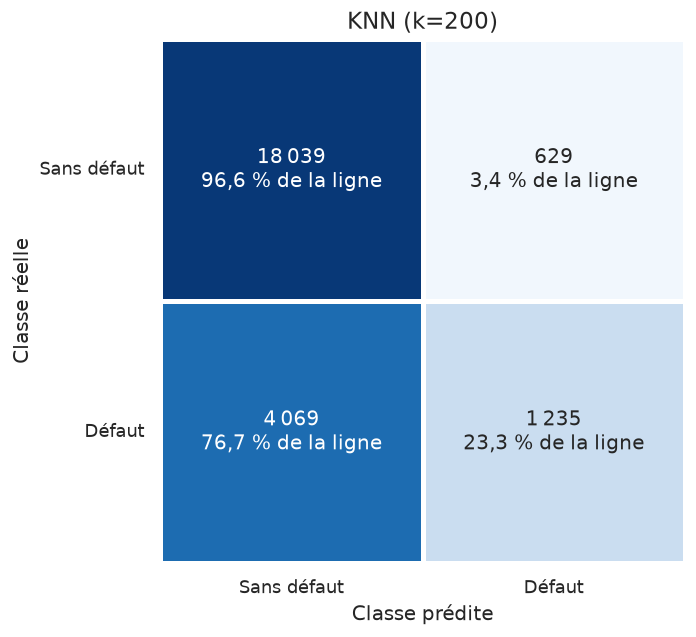

Explication : La ROC-AUC vaut 0,752 sur les prédictions OOF. Au threshold 0,5, le modèle détecte 1 235 défauts et en manque 4 069 (recall 23,3 %). Il émet 629 fausses alertes ; la precision vaut 66,3 %. Les pourcentages de la matrice se lisent par ligne : ils comparent les décisions pour une même classe réelle.

In [29]:
modele_knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=K_CHOISI))
evaluer(f'KNN (k={K_CHOISI})', modele_knn)

Le KNN fait mieux que la régression logistique en AUC (0,752 contre 0,725), car il n'impose pas de relation en ligne droite.

Mais son recall au threshold de 0,5 reste faible (23 %). En faisant la moyenne sur 200 voisins, ses probabilités dépassent rarement 0,5, même pour des clients risqués. C'est un bon exemple où l'AUC et les métriques à threshold racontent deux choses différentes : le classement des clients est correct, c'est le threshold de 0,5 qui est mal adapté. On reviendra sur le choix du threshold en 3.4.5.

### 3.3.3 Gaussian naive Bayes

L'idée. Le modèle applique la formule de Bayes : il calcule, pour chaque classe, à quel point les valeurs du client sont « typiques » de cette classe, puis combine ces indices pour obtenir une probabilité. La version gaussienne suppose que chaque variable suit une courbe en cloche dans chaque classe.

Pourquoi « naïf ». Il suppose que les variables sont indépendantes les unes des autres, ce qui est rarement vrai. Ici, c'est même très faux : les six `PAY_k` sont fortement liés entre eux. Le modèle compte alors plusieurs fois le même indice.

Une image. Un médecin qui additionne les symptômes un par un sans se demander s'ils ont la même cause.

Ce qu'il faut savoir. Il n'y a presque rien à régler et l'entraînement est quasi instantané. C'est un bon modèle de départ quand on a peu de temps ou beaucoup de données.

Bayésien naïf
  AUC       : 0.734
  Accuracy  : 0.565
  Precision : 0.307
  Recall    : 0.768
  F1        : 0.439
  Temps (s) : 0.161


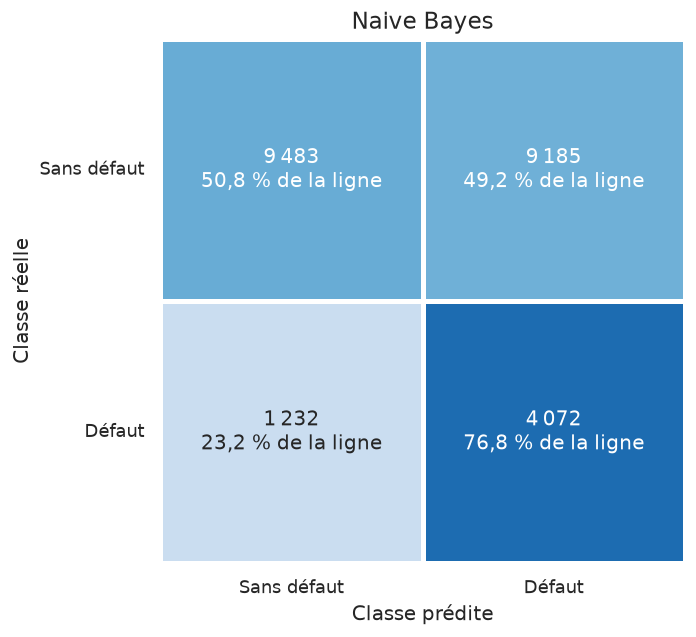

Explication : La ROC-AUC vaut 0,734 sur les prédictions OOF. Au threshold 0,5, le modèle détecte 4 072 défauts et en manque 1 232 (recall 76,8 %). Il émet 9 185 fausses alertes ; la precision vaut 30,7 %. Les pourcentages de la matrice se lisent par ligne : ils comparent les décisions pour une même classe réelle.

In [30]:
modele_nb = make_pipeline(StandardScaler(), GaussianNB())
evaluer('Bayésien naïf', modele_nb)

Gaussian naive Bayes détecte environ 77 % des défauts, mais avec une precision de 31 % : près de sept alertes sur dix sont fausses. Son accuracy tombe à 57 %, alors que sa ROC-AUC vaut 0,734, au-dessus de la logistic regression de base.

Le modèle traite les features comme indépendantes, alors que les statuts mensuels sont corrélés. Cela peut contribuer à des probabilités mal calibrées et à trop d’alertes au threshold de 0,5. Un autre threshold se testerait en validation ; la ROC-AUC seule ne suffit pas à choisir une décision.

### 3.3.4 Support vector machine (SVM)

L'idée. Le SVM cherche la frontière qui sépare le mieux les deux classes en laissant la plus grande marge possible entre la frontière et les clients les plus proches de chaque côté. Avec un noyau (ici le noyau RBF, le réglage par défaut), cette frontière peut être courbe.

Une image. Tracer la route la plus large possible entre deux villages, sans écraser de maison.

Ce qu'il faut savoir.

- Il demande des variables standardisées.
- Il est lent : le temps de calcul augmente très vite avec le nombre de clients. Sur nos 23 972 clients, c'est la méthode la plus longue.
- Il ne donne pas directement de probabilité, mais un score (la distance à la frontière). Le threshold naturel est 0. Ça suffit pour calculer l'AUC.
- Réglages principaux : `C` (tolérance aux erreurs) et `gamma` (souplesse de la frontière). On garde les valeurs par défaut.

SVM (noyau RBF)
  AUC       : 0.720
  Accuracy  : 0.819
  Precision : 0.694
  Recall    : 0.328
  F1        : 0.445
  Temps (s) : 7.940


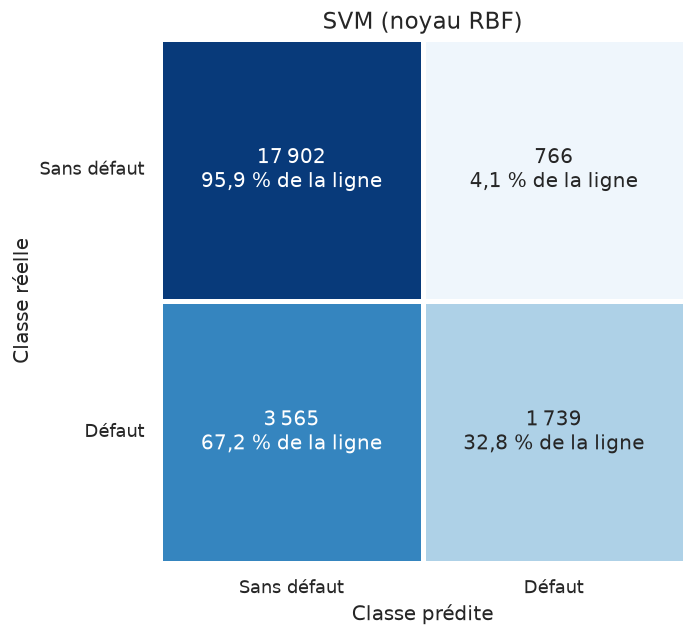

Explication : La ROC-AUC vaut 0,720 sur les prédictions OOF. Au threshold 0, le modèle détecte 1 739 défauts et en manque 3 565 (recall 32,8 %). Il émet 766 fausses alertes ; la precision vaut 69,4 %. Les pourcentages de la matrice se lisent par ligne : ils comparent les décisions pour une même classe réelle.

In [31]:
modele_svm = make_pipeline(StandardScaler(), SVC())
evaluer('SVM (noyau RBF)', modele_svm)

Avec une ROC-AUC de 0,720, le SVM reste derrière la logistic regression et le KNN dans cette comparaison, alors que son coût de calcul est plus élevé. Au threshold naturel de 0, il détecte environ 33 % des défauts : ce recall plus élevé ne signifie donc pas que son classement global est meilleur. Les méthodes à base d’arbres sont comparées ensuite sur les mêmes folds.


### 3.3.5 Decision tree

L'idée. Le modèle pose une suite de questions de type oui/non (« `PAY_1` > 1 ? », « `LIMIT_BAL` ≤ 50 000 ? »). À chaque étape, il choisit la question qui sépare le mieux les défauts des non-défauts. On descend l'arbre en suivant les réponses jusqu'à une feuille, qui donne la proportion de défauts parmi les clients d'entraînement arrivés là.

Une image. Le jeu « Qui est-ce ? ».

Ce qu'il faut savoir.

- Très lisible : on peut dessiner l'arbre et l'expliquer à quelqu'un.
- Pas besoin de standardiser : une question du type « plafond > 50 000 ? » ne dépend pas de l'échelle.
- Réglage principal : `max_depth`, la profondeur (le nombre maximum de questions à la suite). Trop profond, il surapprend.

Voici un arbre de profondeur 2 :

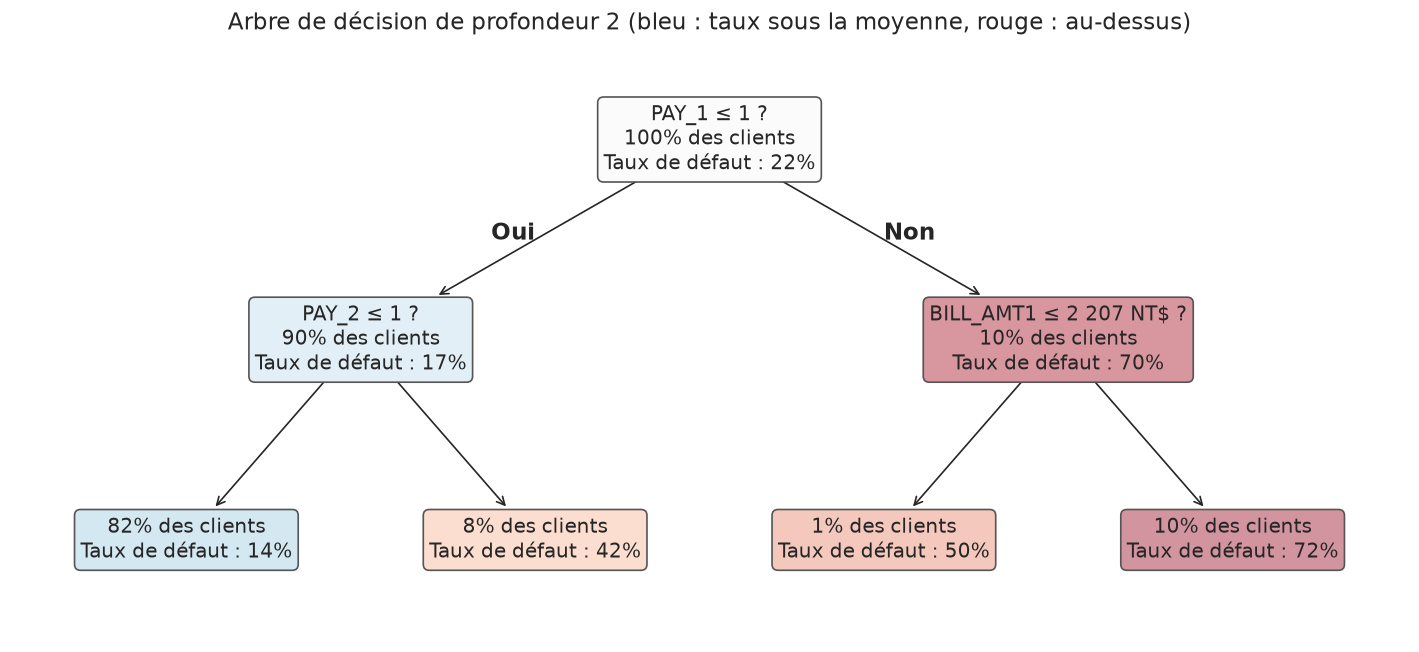

Explication : La première coupure porte sur `PAY_1` à 1,50. Elle sépare 21 464 clients à gauche et 2 508 à droite. Cet arbre court illustre les règles apprises ; sa simplicité limite aussi les relations qu’il peut représenter.

In [32]:
from matplotlib import colors as mcolors
petit_arbre = DecisionTreeClassifier(max_depth=2, random_state=SEED).fit(X_train, y_train)
fig, ax = plt.subplots(figsize=(15, 6.5))
_annotations = plot_tree(petit_arbre, feature_names=list(X_train.columns), filled=True, rounded=True,
                         impurity=False, fontsize=12, ax=ax)
_arbre = petit_arbre.tree_
_noeuds = [a for a in _annotations if 'samples' in a.get_text()]   # ordre préfixe = identifiants des nœuds
_norme = mcolors.TwoSlopeNorm(vmin=0, vcenter=taux_reference, vmax=.8)
_cmap = plt.get_cmap('RdBu_r')

def _question(noeud):
    nom = X_train.columns[_arbre.feature[noeud]]
    seuil = _arbre.threshold[noeud]
    valeur = np.floor(seuil) if seuil % 1 == .5 else seuil
    unite = ' NT$' if nom.startswith(('BILL', 'PAY_AMT', 'LIMIT')) else ''
    return f'{nom} ≤ {valeur:,.0f}{unite} ?'.replace(',', ' ')

for noeud, annotation in enumerate(_noeuds):
    effectifs = _arbre.value[noeud, 0]
    taux = effectifs[1] / effectifs.sum()
    part = _arbre.n_node_samples[noeud] / _arbre.n_node_samples[0]
    lignes = [] if _arbre.children_left[noeud] == -1 else [_question(noeud)]
    lignes += [f'{part:.0%} des clients', f'Taux de défaut : {taux:.0%}']
    annotation.set_text('\n'.join(lignes))
    couleur = np.array(_cmap(_norme(taux))[:3])
    annotation.get_bbox_patch().set_facecolor(.45 * couleur + .55)      # teinte éclaircie : texte lisible
    annotation.get_bbox_patch().set_edgecolor('#555555')
for texte in ax.texts:
    if texte.get_text().strip() in ('True', 'False'):
        texte.set_text({'True': 'Oui', 'False': 'Non'}[texte.get_text().strip()])
        texte.set_fontsize(14)
        texte.set_fontweight('bold')
ax.set_title('Arbre de décision de profondeur 2 (bleu : taux sous la moyenne, rouge : au-dessus)')
plt.show()
_racine=petit_arbre.tree_
_feature_racine=X_train.columns[_racine.feature[0]]
display(Markdown(f'Explication : La première coupure porte sur `{_feature_racine}` à '
    f'{_racine.threshold[0]:.2f}. Elle sépare {_racine.n_node_samples[1]:,} clients '
    f'à gauche et {_racine.n_node_samples[_racine.children_right[0]]:,} à droite. '
    'Cet arbre court illustre les règles apprises ; sa simplicité limite aussi les relations qu’il peut représenter.'))

Dans chaque case : la question posée (on descend à gauche si la réponse est « Oui »), la part des clients d’entraînement qui arrivent dans la case et leur taux de défaut observé. La couleur suit ce taux : bleu en dessous du taux moyen (22 %), rouge au-dessus ; plus la teinte est soutenue, plus l’écart est grand.

La première question porte sur `PAY_1` : l'arbre a retrouvé tout seul la variable la plus importante. À droite (au moins deux mois de retard en septembre), 70 % des clients sont en défaut.

Le overfitting en image. On fait varier la profondeur de 1 à 20 et on compare l'AUC sur les données d'entraînement (que le modèle a vues) et en cross-validation (qu'il n'a pas vues).

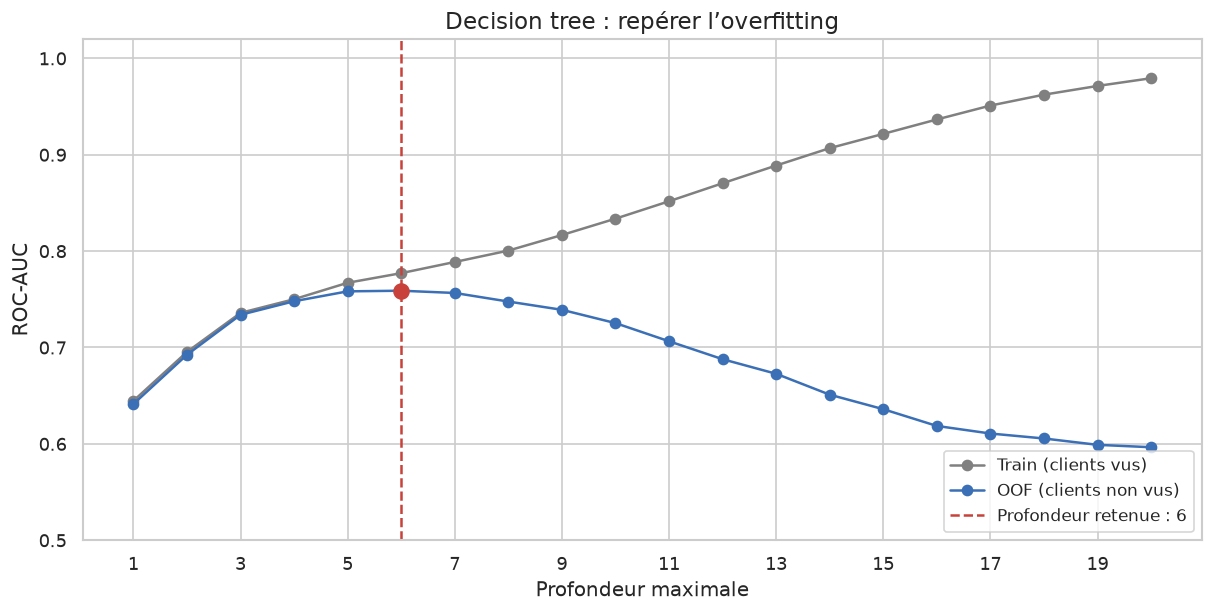

Explication : la meilleure ROC-AUC OOF (courbe bleue) est 0,759, à une profondeur de 6. Au-delà, le score train (gris) continue de monter alors que le score OOF baisse : à la profondeur maximale, 0,979 sur le train contre 0,596 en OOF. Cet écart de 0,383 est l’overfitting : l’arbre apprend des particularités du train qui ne se retrouvent pas chez de nouveaux clients. On retient la profondeur au meilleur score OOF pour cette comparaison initiale.

In [33]:
profondeurs = range(1, 21)
auc_train, auc_cv = [], []
for p in profondeurs:
    arbre = DecisionTreeClassifier(max_depth=p, random_state=SEED)
    arbre.fit(X_train, y_train)
    auc_train.append(roc_auc_score(y_train, arbre.predict_proba(X_train)[:, 1]))
    score = cross_val_predict(arbre, X_train, y_train, cv=cv, method='predict_proba', n_jobs=-1)[:, 1]
    auc_cv.append(roc_auc_score(y_train, score))

PROF_CHOISIE=profondeurs[int(np.argmax(auc_cv))]
fig,ax=plt.subplots(figsize=(10,5),layout='constrained')
ax.plot(profondeurs,auc_train,marker='o',color='grey',label='Train (clients vus)')
ax.plot(profondeurs,auc_cv,marker='o',color=BLEU,label='OOF (clients non vus)')
ax.axvline(PROF_CHOISIE,color=ROUGE,ls='--',label=f'Profondeur retenue : {PROF_CHOISIE}')
ax.scatter([PROF_CHOISIE],[max(auc_cv)],s=80,color=ROUGE,zorder=5)
ax.set(xlabel='Profondeur maximale',ylabel='ROC-AUC',title='Decision tree : repérer l’overfitting',ylim=(.5,1.02))
ax.set_xticks(list(profondeurs)[::2])
ax.legend(loc='lower right')
plt.show()
display(Markdown(f'Explication : la meilleure ROC-AUC OOF (courbe bleue) est {max(auc_cv):.3f}, à une profondeur de '
    f'{PROF_CHOISIE}. Au-delà, le score train (gris) continue de monter alors que le score OOF baisse : à la profondeur maximale, '
    f'{auc_train[-1]:.3f} sur le train contre {auc_cv[-1]:.3f} en OOF. Cet écart de {auc_train[-1]-auc_cv[-1]:.3f} est '
    'l’overfitting : l’arbre apprend des particularités du train qui ne se retrouvent pas chez de nouveaux clients. '
    'On retient la profondeur au meilleur score OOF pour cette comparaison initiale.'))

Arbre (profondeur 6)
  AUC       : 0.759
  Accuracy  : 0.819
  Precision : 0.664
  Recall    : 0.366
  F1        : 0.472
  Temps (s) : 0.232


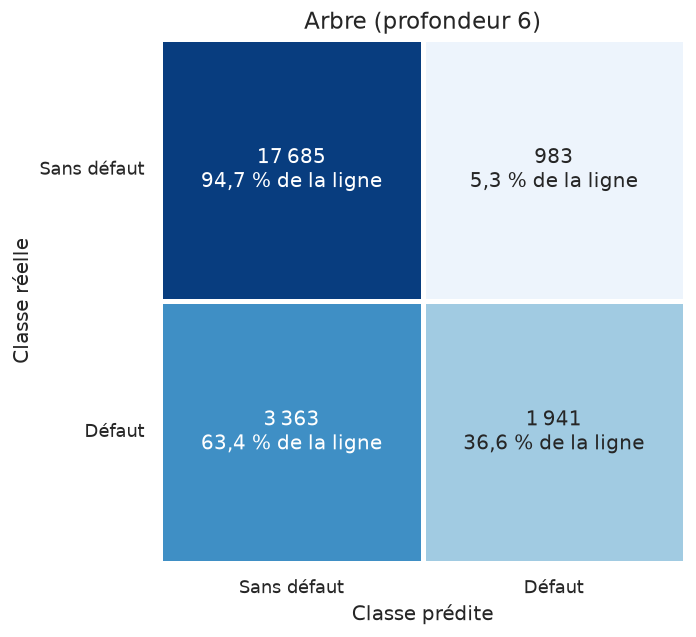

Explication : La ROC-AUC vaut 0,759 sur les prédictions OOF. Au threshold 0,5, le modèle détecte 1 941 défauts et en manque 3 363 (recall 36,6 %). Il émet 983 fausses alertes ; la precision vaut 66,4 %. Les pourcentages de la matrice se lisent par ligne : ils comparent les décisions pour une même classe réelle.

In [34]:
modele_arbre = DecisionTreeClassifier(max_depth=PROF_CHOISIE, random_state=SEED)
evaluer(f'Arbre (profondeur {PROF_CHOISIE})', modele_arbre)

Avec 6 niveaux de questions, l'arbre fait mieux que les quatre méthodes précédentes, en AUC (0,759) comme en F1 (0,472). Il capte naturellement le saut de risque à partir de deux mois de retard, que la régression logistique avait du mal à représenter.

### 3.3.6 Random forest

L'idée. Un seul arbre est instable : changez quelques clients et il peut devenir très différent. La forêt aléatoire entraîne des centaines d'arbres et fait la moyenne de leurs réponses. Pour qu'ils ne soient pas tous identiques, chaque arbre :

- apprend sur un tirage au hasard des clients (avec remise) ;
- ne regarde qu'une partie des variables, tirée au hasard, à chaque question.

Les erreurs des arbres se compensent. C'est le principe du bagging.

Une image. Demander l'avis de 200 experts un peu différents et faire la moyenne, plutôt que de se fier à un seul.

Ce qu'il faut savoir.

- Pas de standardization nécessaire.
- Réglages principaux : `n_estimators` (nombre d'arbres) et `min_samples_leaf` (nombre minimum de clients par feuille, qui limite le overfitting de chaque arbre).
- Plus d'arbres ne fait jamais de mal à la qualité, seulement au temps de calcul. Vérifions-le :

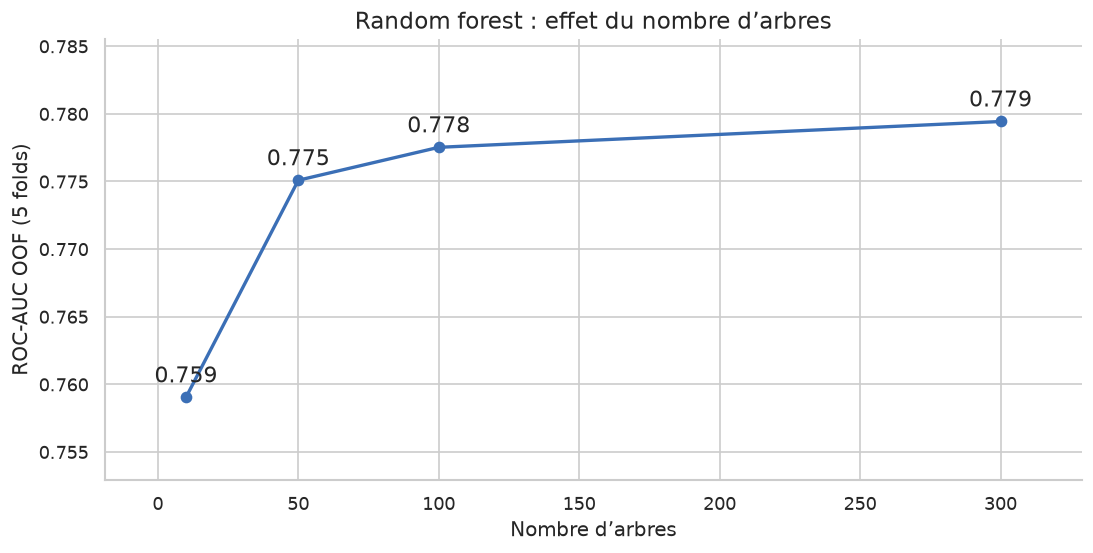

Explication : passer de 10 à 300 arbres fait passer la ROC-AUC de 0,759 à 0,779. Les premiers arbres apportent l’essentiel du gain, puis la courbe se stabilise. On garde 300 arbres : au-delà, on paie surtout du temps de calcul.

In [35]:
auc_par_n = {}
for n in [10, 50, 100, 300]:
    foret = RandomForestClassifier(n_estimators=n, min_samples_leaf=5, n_jobs=-1, random_state=SEED)
    score = cross_val_predict(foret, X_train, y_train, cv=cv, method='predict_proba')[:, 1]
    auc_par_n[n] = roc_auc_score(y_train, score)

fig,ax=plt.subplots(figsize=(9,4.5),layout='constrained')
courbe_reglage(ax,auc_par_n,'Nombre d’arbres','Random forest : effet du nombre d’arbres')
plt.show()
display(Markdown(f'Explication : passer de {min(auc_par_n)} à {max(auc_par_n)} arbres '
    f'fait passer la ROC-AUC de {auc_par_n[min(auc_par_n)]:.3f} à {auc_par_n[max(auc_par_n)]:.3f}. Les premiers arbres '
    'apportent l’essentiel du gain, puis la courbe se stabilise. On garde 300 arbres : au-delà, on paie surtout du temps de calcul.'))

Forêt aléatoire
  AUC       : 0.779
  Accuracy  : 0.818
  Precision : 0.659
  Recall    : 0.367
  F1        : 0.471
  Temps (s) : 3.859


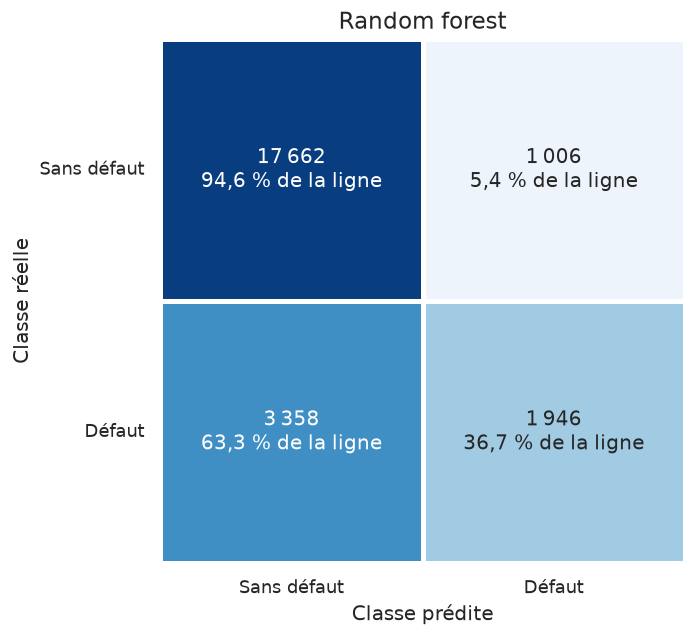

Explication : La ROC-AUC vaut 0,779 sur les prédictions OOF. Au threshold 0,5, le modèle détecte 1 946 défauts et en manque 3 358 (recall 36,7 %). Il émet 1 006 fausses alertes ; la precision vaut 65,9 %. Les pourcentages de la matrice se lisent par ligne : ils comparent les décisions pour une même classe réelle.

In [36]:
modele_rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=SEED)
evaluer('Forêt aléatoire', modele_rf)

La forêt aléatoire fait nettement mieux qu'un arbre seul en AUC (0,779 contre 0,759). Au threshold de 0,5, les autres métriques sont presque identiques (recall de 37 %, F1 de 0,47) : la forêt classe mieux les clients, mais prend à peu près les mêmes décisions au threshold de 0,5.

### 3.3.7 Gradient boosting

L'idée. Comme la forêt, le gradient boosting combine des arbres, mais il les construit l'un après l'autre. Chaque nouvel arbre, volontairement petit, se concentre sur les erreurs que les arbres précédents font encore. La prédiction finale additionne les corrections de tous les arbres.

Une image. Un élève qui refait ses exercices en ne travaillant que ce qu'il a raté la fois précédente.

Ce qu'il faut savoir.

- Pas de standardization nécessaire : comme pour les autres arbres, seules les comparaisons « valeur ≤ seuil » comptent.
- Sur des données tabulaires comme les nôtres, c'est souvent la famille la plus performante, parce qu'elle capte facilement les interactions non linéaires entre variables.
- Réglages principaux : `learning_rate` (l'ampleur de chaque correction), `max_iter` (le nombre d'arbres) et la taille des arbres (`max_leaf_nodes`, `max_depth`). Un petit `learning_rate` demande plus d'arbres mais surapprend moins vite.
- On utilise ici `HistGradientBoostingClassifier` de scikit-learn avec ses réglages par défaut. XGBoost, LightGBM et CatBoost, trois implémentations plus poussées du même principe, sont comparés en § 3.4.2.

Gradient boosting
  AUC       : 0.784
  Accuracy  : 0.820
  Precision : 0.676
  Recall    : 0.360
  F1        : 0.470
  Temps (s) : 0.344


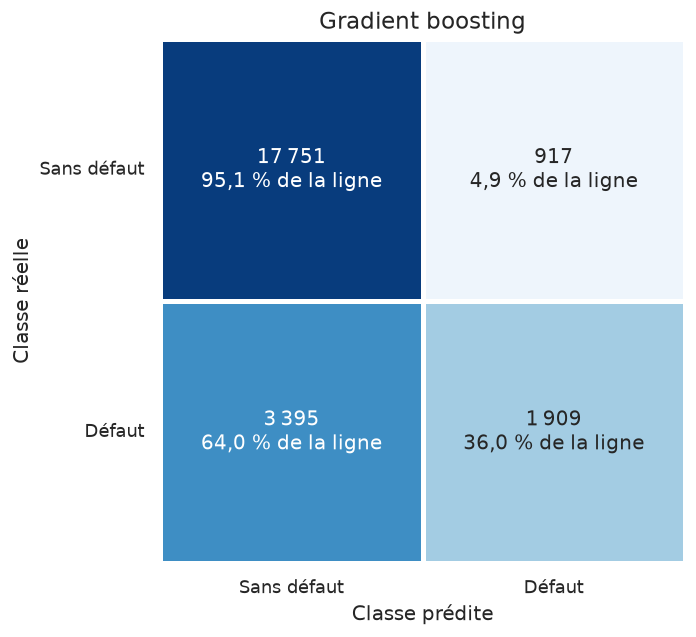

Explication : La ROC-AUC vaut 0,784 sur les prédictions OOF. Au threshold 0,5, le modèle détecte 1 909 défauts et en manque 3 395 (recall 36,0 %). Il émet 917 fausses alertes ; la precision vaut 67,6 %. Les pourcentages de la matrice se lisent par ligne : ils comparent les décisions pour une même classe réelle.

In [37]:
modele_gb = HistGradientBoostingClassifier(random_state=SEED)
evaluer('Gradient boosting', modele_gb)

HistGradientBoosting obtient la meilleure AUC de cette comparaison initiale, autour de 0,784. C’est un premier résultat avec des réglages simples. La suite compare aussi XGBoost, LightGBM et CatBoost, avec un budget de tuning commun et une évaluation sur les outer folds.


### 3.3.8 MLP

L'idée. Un réseau de neurones est composé de couches de petites unités de calcul (les neurones). Chaque neurone fait une somme pondérée de ce qu'il reçoit, puis applique une fonction simple. La première couche reçoit les variables du client, la dernière donne la probabilité de défaut. Entre les deux, les couches cachées construisent des combinaisons de variables de plus en plus élaborées. L'entraînement ajuste tous les poids petit à petit pour réduire les erreurs.

Une régression logistique, c'est en fait un réseau avec un seul neurone. Ajouter des couches permet de capter des relations plus complexes.

Ce qu'il faut savoir.

- standardization obligatoire.
- Réglages : `hidden_layer_sizes` (le nombre de neurones par couche cachée). Ici, (32, 16) signifie deux couches cachées de 32 puis 16 neurones. `alpha` règle la régularisation.
- `early_stopping=True` arrête l'entraînement quand le modèle cesse de progresser sur une petite partie des données mise de côté, pour éviter le overfitting.
- Les réseaux de neurones brillent sur les images, le son ou le texte. Sur un petit tableau comme le nôtre, ils font rarement mieux que le gradient boosting.

Réseau de neurones
  AUC       : 0.766
  Accuracy  : 0.819
  Precision : 0.665
  Recall    : 0.364
  F1        : 0.471
  Temps (s) : 0.748


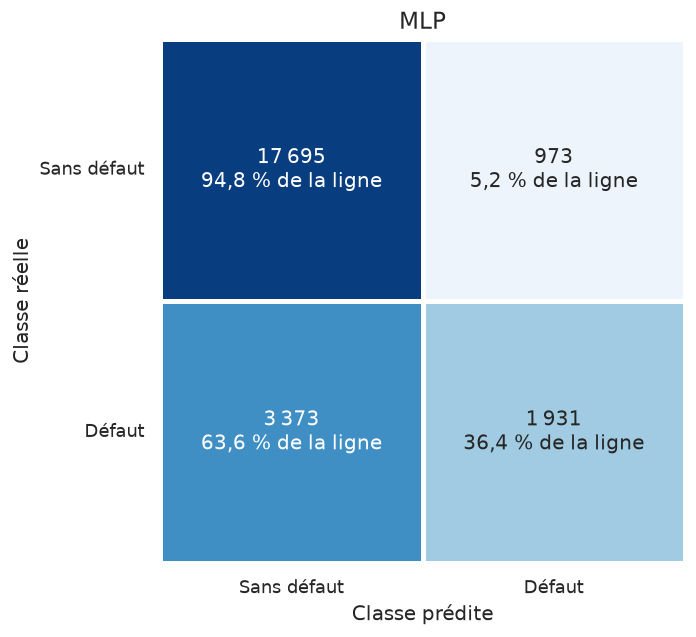

Explication : La ROC-AUC vaut 0,766 sur les prédictions OOF. Au threshold 0,5, le modèle détecte 1 931 défauts et en manque 3 373 (recall 36,4 %). Il émet 973 fausses alertes ; la precision vaut 66,5 %. Les pourcentages de la matrice se lisent par ligne : ils comparent les décisions pour une même classe réelle.

In [38]:
modele_mlp = make_pipeline(StandardScaler(),
                           MLPClassifier(hidden_layer_sizes=(32, 16), alpha=1e-3, early_stopping=True,
                                         max_iter=300, random_state=SEED))
evaluer('Réseau de neurones', modele_mlp)

Le réseau de neurones se place entre l'arbre et la forêt (AUC 0,766). Il fait mieux que la régression logistique, qui n'est qu'un réseau à un seul neurone : les couches cachées lui permettent de capter des relations non linéaires. Mais il ne rattrape pas les meilleures méthodes à base d'arbres. Ses résultats dépendent aussi beaucoup de ses réglages (nombre de couches, de neurones, régularisation), qu'on n'a pas cherché à optimiser.

### 3.3.9 Résultats de la comparaison initiale

On rassemble les résultats dans un tableau trié par AUC.

,AUC,Accuracy,Precision,Recall,F1,Temps (s)
Gradient boosting,0.784,0.820,0.676,0.360,0.470,0.344
Forêt aléatoire,0.779,0.818,0.659,0.367,0.471,3.859
Réseau de neurones,0.766,0.819,0.665,0.364,0.471,0.748
Arbre (profondeur 6),0.759,0.819,0.664,0.366,0.472,0.232
KNN (k=200),0.752,0.804,0.663,0.233,0.345,0.679
Bayésien naïf,0.734,0.565,0.307,0.768,0.439,0.161
Régression logistique,0.725,0.810,0.706,0.239,0.357,0.174
SVM (noyau RBF),0.720,0.819,0.694,0.328,0.445,7.940
Règle PAY_1 ≥ 1,0.690,0.781,0.505,0.520,0.512,0.000
Naïf (toujours 0),0.500,0.779,0.000,0.000,0.000,1.009


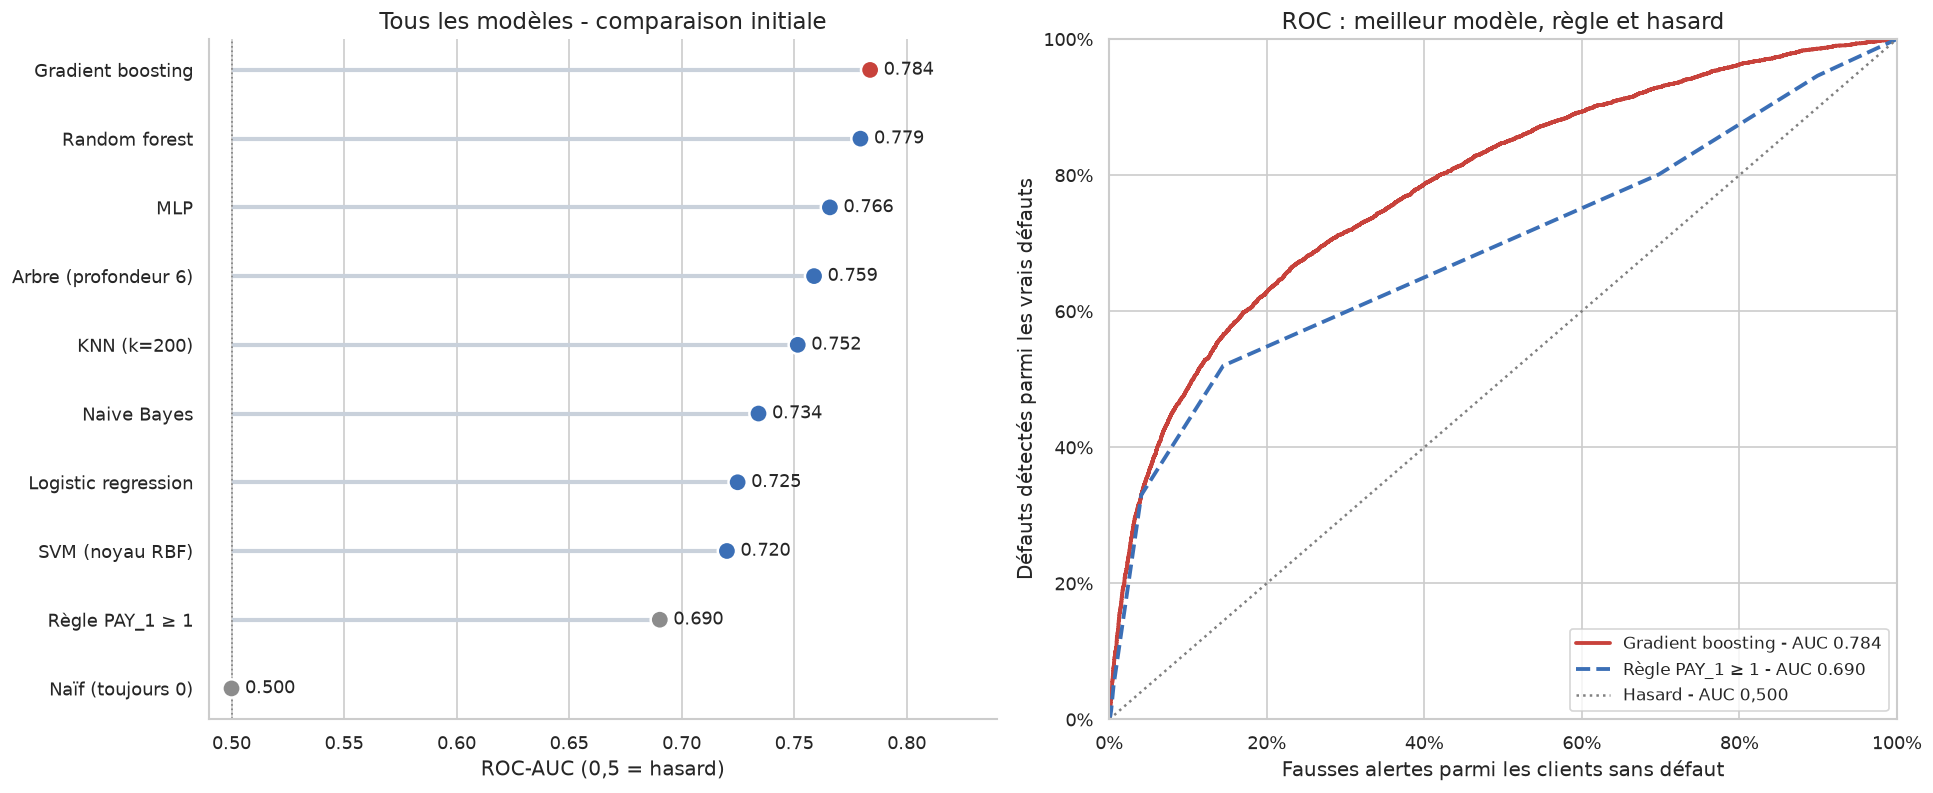

Explication : Gradient boosting arrive en tête avec une ROC-AUC de 0,784, contre 0,690 pour la règle PAY_1. Une ROC plus proche du coin supérieur gauche détecte davantage de défauts pour une même proportion de fausses alertes ; seuls le meilleur modèle, PAY_1 et le hasard sont tracés pour rester lisible. La courbe PAY_1 fait varier le seuil sur le code de retard, alors que la règle fixe `PAY_1 ≥ 1` n’en est qu’un point, dont les métriques sont dans le tableau. Un meilleur classement ne fixe pas, à lui seul, le threshold métier.

In [39]:
comparaison=pd.DataFrame(resultats).T.sort_values('AUC',ascending=False)
display(comparaison.round(3))
_individuels=[nom for nom in comparaison.index if not nom.startswith(('Naïf','Règle'))]
meilleur_initial=max(_individuels,key=lambda nom:resultats[nom]['AUC'])
fig,axes=plt.subplots(1,2,figsize=(16,6.5),layout='constrained')
barres_auc(axes[0],comparaison.AUC,'Tous les modèles - comparaison initiale')
for nom,couleur,style in [(meilleur_initial,ROUGE,'-'),('Règle PAY_1 ≥ 1',BLEU,'--')]:
    fpr,tpr,_=roc_curve(y_train,scores_oof[nom])
    axes[1].plot(fpr,tpr,style,color=couleur,lw=2.3,
                 label=f'{NOMS_MODELES.get(nom,nom)} - AUC {resultats[nom]["AUC"]:.3f}')
axes[1].plot([0,1],[0,1],':',color='grey',label='Hasard - AUC 0,500')
axes[1].set(xlabel='Fausses alertes parmi les clients sans défaut',ylabel='Défauts détectés parmi les vrais défauts',
            title='ROC : meilleur modèle, règle et hasard',xlim=(0,1),ylim=(0,1))
axes[1].xaxis.set_major_formatter(PercentFormatter(1))
axes[1].yaxis.set_major_formatter(PercentFormatter(1))
axes[1].legend(loc='lower right',fontsize=10)
plt.show()
display(Markdown(f'Explication : {NOMS_MODELES.get(meilleur_initial,meilleur_initial)} arrive en tête '
    f'avec une ROC-AUC de {resultats[meilleur_initial]["AUC"]:.3f}, contre '
    f'{resultats["Règle PAY_1 ≥ 1"]["AUC"]:.3f} pour la règle PAY_1. Une ROC plus proche du coin supérieur gauche détecte '
    'davantage de défauts pour une même proportion de fausses alertes ; seuls le meilleur modèle, PAY_1 et le hasard sont '
    'tracés pour rester lisible. La courbe PAY_1 fait varier le seuil sur le code de retard, alors que la règle fixe '
    '`PAY_1 ≥ 1` n’en est qu’un point, dont les métriques sont dans le tableau. Un meilleur classement ne fixe pas, '
    'à lui seul, le threshold métier.'))

## 3.4 Apport des features et tuning

### 3.4.1 Apport des features ajoutées

Les cinq variables ont été construites et visualisées en § 2.9. On compare maintenant les mêmes modèles avec et sans ces variables, sur les mêmes plis d'entraînement. Le test reste réservé.

On réévalue maintenant la régression logistique et le gradient boosting avec ces variables en plus.

,AUC,Recall,F1
Régression logistique,0.725,0.239,0.357
Régression logistique + variables,0.761,0.300,0.410
Gradient boosting,0.784,0.360,0.470
Gradient boosting + variables,0.786,0.361,0.471


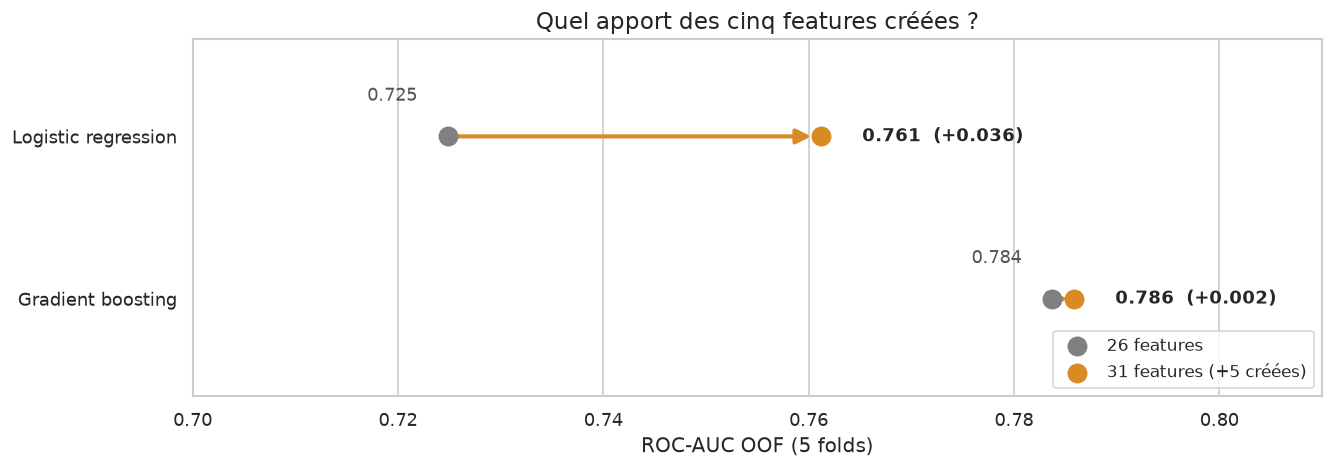

Explication : la logistic regression gagne +0,036 d’AUC (0,725 → 0,761) et son recall passe de 24 % à 30 %. Les nouvelles variables lui apportent ce qu’elle ne sait pas construire seule : `NB_MOIS_RETARD` et `RETARD_MAX` croissent régulièrement avec le risque, exactement le type de relation qu’un modèle linéaire sait utiliser. Le gradient boosting ne gagne presque rien (+0,002) : ses arbres retrouvaient déjà ces combinaisons. Créer des variables aide surtout les modèles simples ; pour les modèles puissants, cela rend surtout le modèle plus facile à expliquer (§ 3.6).

In [40]:
evaluer('Régression logistique + variables',modele_lr,X=X_train_plus,afficher=False)
evaluer('Gradient boosting + variables',modele_gb,X=X_train_plus,afficher=False)
_comparaison_features=pd.DataFrame(resultats).T.loc[
    ['Régression logistique','Régression logistique + variables','Gradient boosting','Gradient boosting + variables'],
    ['AUC','Recall','F1']]
display(_comparaison_features.round(3))
fig, ax = plt.subplots(figsize=(11, 3.8), layout='constrained')
for i, nom in enumerate(['Gradient boosting', 'Régression logistique']):
    avant, apres = resultats[nom]['AUC'], resultats[nom + ' + variables']['AUC']
    ax.annotate('', xy=(apres, i), xytext=(avant, i),
                arrowprops={'arrowstyle': '-|>', 'color': ORANGE, 'lw': 2.5, 'mutation_scale': 18, 'shrinkA': 6, 'shrinkB': 6})
    ax.scatter(avant, i, s=120, color='grey', zorder=3, label='26 features' if i == 0 else None)
    ax.scatter(apres, i, s=120, color=ORANGE, zorder=3, label='31 features (+5 créées)' if i == 0 else None)
    ax.text(avant - .003, i + .22, f'{avant:.3f}', ha='right', fontsize=11, color='#555555')
    ax.text(apres + .004, i, f'{apres:.3f}  ({apres-avant:+.3f})', va='center', fontsize=11, weight='bold')
ax.set_yticks([0, 1], ['Gradient boosting', 'Logistic regression'])
ax.set(xlim=(.70, .81), ylim=(-.6, 1.6), xlabel='ROC-AUC OOF (5 folds)', title='Quel apport des cinq features créées ?')
ax.legend(loc='lower right')
ax.grid(axis='y', visible=False)
plt.show()
_cf = _comparaison_features
display(Markdown(
    f'Explication : la logistic regression gagne {_cf.loc["Régression logistique + variables","AUC"]-_cf.loc["Régression logistique","AUC"]:+.3f} '
    f'd’AUC ({_cf.loc["Régression logistique","AUC"]:.3f} → {_cf.loc["Régression logistique + variables","AUC"]:.3f}) et son recall '
    f'passe de {_cf.loc["Régression logistique","Recall"]:.0%} à {_cf.loc["Régression logistique + variables","Recall"]:.0%}. '
    'Les nouvelles variables lui apportent ce qu’elle ne sait pas construire seule : `NB_MOIS_RETARD` et `RETARD_MAX` croissent '
    'régulièrement avec le risque, exactement le type de relation qu’un modèle linéaire sait utiliser. '
    f'Le gradient boosting ne gagne presque rien ({_cf.loc["Gradient boosting + variables","AUC"]-_cf.loc["Gradient boosting","AUC"]:+.3f}) : '
    'ses arbres retrouvaient déjà ces combinaisons. Créer des variables aide surtout les modèles simples ; pour les modèles '
    'puissants, cela rend surtout le modèle plus facile à expliquer (§ 3.6).'
))

### 3.4.2 Hyperparameter tuning avec nested CV

La nested CV sépare le choix des hyperparamètres de la mesure de performance. Le test final de 5 993 observations reste réservé pendant toute cette étape.

Les 23 972 observations sont réparties en cinq outer folds. À chaque tour, 19 177 ou 19 178 observations forment le train externe ; les 4 794 ou 4 795 autres forment la validation externe. Ces dernières ne servent pas à choisir les hyperparamètres de ce tour.

Dans le train externe, cinq inner folds sont utilisés pour comparer 50 trials Optuna TPE par modèle. Chaque fit interne apprend sur 15 341 à 15 343 observations et prédit 3 835 ou 3 836 observations de validation interne. On choisit les hyperparamètres donnant la meilleure ROC-AUC moyenne interne, puis on refit le modèle sur tout le train externe et on mesure sa ROC-AUC sur la validation externe.

On répète ce processus pour les cinq outer folds. Le score d’un modèle est la moyenne de ses cinq ROC-AUC externes ; leur écart-type décrit la variabilité entre folds. Pour dix modèles, le budget est de 10 × 5 × 50 × 5 = 12 500 fits internes, plus 50 refits externes. L’outer fold qui mesure une configuration n’a pas servi à choisir ses hyperparamètres.

Les cinq features ajoutées sont calculées ligne par ligne sans la target. La standardization est apprise dans les pipelines concernés, uniquement sur les données de fit. Les couples (modèle, outer fold) sont parallélisés sur CPU, avec au plus six processus et deux threads par fit.

Le SVM RBF reste un diagnostic initial : il est exclu du tuning pour limiter le coût de calcul. La comparaison après tuning inclut logistic regression, KNN, Gaussian naive Bayes, decision tree, random forest, HistGradientBoosting, XGBoost, LightGBM, CatBoost et MLP.


In [41]:
from pathlib import Path
import hashlib
import sqlite3
import json
import os
import pickle
import numpy as np
import pandas as pd
import optuna
from joblib import Parallel, delayed, parallel_config
from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import roc_auc_score
from threadpoolctl import threadpool_limits
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

N_TRIALS = 50
N_SPLITS = 5
MODELES = ['Logistic regression', 'KNN', 'Gaussian naive Bayes', 'Decision tree',
           'Random forest', 'HistGradientBoosting', 'XGBoost', 'LightGBM', 'CatBoost', 'MLP']
EXCLUS = {'SVM RBF': 'Coût élevé du tuning ; déjà évalué dans la comparaison initiale.'}
VOTE = 'Vote (logistique + forêt + boosting du pli)'
CACHE = PROJECT_ROOT / '.actualise2_cache'
CACHE.mkdir(exist_ok=True)
# Parallélisation CPU, avec au plus deux threads par fit.
CPU_WORKERS = max(1, min(6, (os.cpu_count() or 2) // 2))
FIT_THREADS = 2
optuna.logging.set_verbosity(optuna.logging.WARNING)


def decrire_espaces():
    descriptions = {
        'Logistic regression': 'C (log), class_weight',
        'KNN': 'n_neighbors, weights, p',
        'Gaussian naive Bayes': 'var_smoothing (log)',
        'Decision tree': 'max_depth, min_samples_leaf, class_weight',
        'Random forest': 'n_estimators, max_depth, min_samples_leaf, max_features, class_weight',
        'HistGradientBoosting': 'learning_rate (log), max_iter, max_leaf_nodes, l2_regularization (log)',
        'XGBoost': 'n_estimators, max_depth, learning_rate (log), subsample, colsample_bytree, reg_lambda (log)',
        'LightGBM': 'n_estimators, num_leaves, learning_rate (log), min_child_samples, reg_lambda (log)',
        'CatBoost': 'iterations, depth, learning_rate (log), l2_leaf_reg (log), auto_class_weights',
        'MLP': 'hidden_layer_sizes, alpha (log), learning_rate_init (log)',
    }
    return pd.DataFrame({'Hyperparameters': descriptions,
                         'Device': {n: 'CPU' for n in descriptions}})


def suggerer(nom, t):
    if nom == 'Logistic regression':
        return dict(C=t.suggest_float('C', 1e-3, 10, log=True), class_weight=t.suggest_categorical('class_weight', [None, 'balanced']))
    if nom == 'KNN':
        return dict(n_neighbors=t.suggest_int('n_neighbors', 20, 200, step=20), weights=t.suggest_categorical('weights', ['uniform','distance']), p=t.suggest_int('p',1,2))
    if nom == 'Gaussian naive Bayes':
        return dict(var_smoothing=t.suggest_float('var_smoothing', 1e-11, 1e-3, log=True))
    if nom == 'Decision tree':
        return dict(max_depth=t.suggest_int('max_depth',2,12), min_samples_leaf=t.suggest_int('min_samples_leaf',10,100), class_weight=t.suggest_categorical('class_weight',[None,'balanced']))
    if nom == 'Random forest':
        return dict(n_estimators=t.suggest_int('n_estimators',100,300,step=100), max_depth=t.suggest_int('max_depth',4,14), min_samples_leaf=t.suggest_int('min_samples_leaf',5,50), max_features=t.suggest_categorical('max_features',['sqrt',0.7]), class_weight=t.suggest_categorical('class_weight',[None,'balanced']))
    if nom == 'HistGradientBoosting':
        return dict(learning_rate=t.suggest_float('learning_rate',.02,.2,log=True), max_iter=t.suggest_int('max_iter',100,300,step=100), max_leaf_nodes=t.suggest_int('max_leaf_nodes',7,31), l2_regularization=t.suggest_float('l2_regularization',.01,20,log=True))
    if nom == 'XGBoost':
        return dict(n_estimators=t.suggest_int('n_estimators',100,400,step=100), max_depth=t.suggest_int('max_depth',2,6), learning_rate=t.suggest_float('learning_rate',.02,.2,log=True), subsample=t.suggest_float('subsample',.7,1), colsample_bytree=t.suggest_float('colsample_bytree',.7,1), reg_lambda=t.suggest_float('reg_lambda',.1,20,log=True))
    if nom == 'LightGBM':
        return dict(n_estimators=t.suggest_int('n_estimators',100,400,step=100), num_leaves=t.suggest_int('num_leaves',7,31), learning_rate=t.suggest_float('learning_rate',.02,.2,log=True), min_child_samples=t.suggest_int('min_child_samples',20,100), reg_lambda=t.suggest_float('reg_lambda',.1,20,log=True))
    if nom == 'CatBoost':
        return dict(iterations=t.suggest_int('iterations',100,400,step=100), depth=t.suggest_int('depth',3,7), learning_rate=t.suggest_float('learning_rate',.02,.2,log=True), l2_leaf_reg=t.suggest_float('l2_leaf_reg',1,20,log=True), auto_class_weights=t.suggest_categorical('auto_class_weights',[None,'Balanced']))
    if nom == 'MLP':
        return dict(hidden_layer_sizes=t.suggest_categorical('hidden_layer_sizes',['32','64','32,16']), alpha=t.suggest_float('alpha',1e-5,.1,log=True), learning_rate_init=t.suggest_float('learning_rate_init',1e-4,.01,log=True))
    raise ValueError(nom)


def construire(nom, params, seed=42):
    p=dict(params)
    if nom=='Logistic regression':return make_pipeline(StandardScaler(),LogisticRegression(max_iter=2000,random_state=seed,**p))
    if nom=='KNN':return make_pipeline(StandardScaler(),KNeighborsClassifier(n_jobs=FIT_THREADS,**p))
    if nom=='Gaussian naive Bayes':return make_pipeline(StandardScaler(),GaussianNB(**p))
    if nom=='Decision tree':return DecisionTreeClassifier(random_state=seed,**p)
    if nom=='Random forest':return RandomForestClassifier(n_jobs=FIT_THREADS,random_state=seed,**p)
    if nom=='HistGradientBoosting':return HistGradientBoostingClassifier(random_state=seed,**p)
    if nom=='XGBoost':return XGBClassifier(tree_method='hist',device='cpu',eval_metric='logloss',n_jobs=FIT_THREADS,random_state=seed,**p)
    if nom=='LightGBM':return LGBMClassifier(verbosity=-1,n_jobs=FIT_THREADS,random_state=seed,**p)
    if nom=='CatBoost':return CatBoostClassifier(task_type='CPU',thread_count=FIT_THREADS,random_seed=seed,verbose=False,allow_writing_files=False,**p)
    if nom=='MLP':
        if isinstance(p.get('hidden_layer_sizes'),str):p['hidden_layer_sizes']=tuple(map(int,p['hidden_layer_sizes'].split(',')))
        return make_pipeline(StandardScaler(),MLPClassifier(early_stopping=True,max_iter=300,random_state=seed,**p))
    raise ValueError(f'Modèle inconnu : {nom}')


def empreinte(X,y,seed,n_splits):
    h=hashlib.sha256()
    h.update(pd.util.hash_pandas_object(X,index=True).values.tobytes())
    h.update(pd.util.hash_pandas_object(y,index=True).values.tobytes())
    h.update(str((list(X.columns),seed,n_splits,[],'spaces-v1')).encode())
    return h.hexdigest()[:16]


def rechercher(nom,X,y,seed,n_trials,n_splits,cle):
    optuna.logging.set_verbosity(optuna.logging.WARNING)
    safe=nom.replace(' ','_')
    folder=CACHE/cle;folder.mkdir(exist_ok=True)
    study=optuna.create_study(direction='maximize',sampler=optuna.samplers.TPESampler(seed=seed),
        storage=f'sqlite:///{folder / (safe+".sqlite3")}',study_name=safe,load_if_exists=True)
    inner=plis_cv(y, k=n_splits, seed=seed)
    memo = {json.dumps(t.params, sort_keys=True): t.value for t in study.trials if t.state == optuna.trial.TrialState.COMPLETE}
    def objective(trial):
        params=suggerer(nom,trial)
        signature=json.dumps(params,sort_keys=True)
        if signature in memo:return memo[signature]
        model=construire(nom,params,seed)
        def score_fold(split):
            tr,va=split
            estimator=clone(model)
            estimator.fit(X.iloc[tr],y.iloc[tr])
            return roc_auc_score(y.iloc[va],estimator.predict_proba(X.iloc[va])[:,1])
        # Inner folds run sequentially inside each isolated model process.
        scores=[score_fold(split) for split in inner]
        memo[signature]=float(np.mean(scores))
        return memo[signature]
    def progress(study,trial):
        completed=sum(t.state==optuna.trial.TrialState.COMPLETE for t in study.trials)
        if completed%10==0:print(f'{nom}: {completed}/{n_trials} trials terminés, meilleure AUC={study.best_value:.4f}',flush=True)
    done=sum(t.state==optuna.trial.TrialState.COMPLETE for t in study.trials)
    if done<n_trials:study.optimize(objective,n_trials=n_trials-done,callbacks=[progress])
    return study


def _evaluer_un_pli(nom,fold,tr,va,X,y,key,seed,n_trials,n_splits,cache_dir):
    global CACHE
    CACHE=Path(cache_dir)
    _thread_limit=threadpool_limits(limits=1)
    cle=f'{key}-outer{fold}'
    resultfile=CACHE/cle/(nom.replace(' ','_')+f'-result-{n_trials}.pkl')
    study=rechercher(nom,X.iloc[tr],y.iloc[tr],seed,n_trials,n_splits,cle)
    if resultfile.exists():
        row,proba=pickle.loads(resultfile.read_bytes())
    else:
        model=construire(nom,study.best_params,seed)
        model.fit(X.iloc[tr],y.iloc[tr])
        proba=model.predict_proba(X.iloc[va])[:,1]
        row={'Modèle':nom,'Fold':fold,'AUC':roc_auc_score(y.iloc[va],proba),'Params':study.best_params}
        resultfile.write_bytes(pickle.dumps((row,proba)))
    print(f'{nom}: outer fold {fold+1}/{n_splits}, AUC={row["AUC"]:.4f}',flush=True)
    return row,proba


def validation_imbriquee(X,y,seed=42,n_trials=N_TRIALS,n_splits=N_SPLITS):
    key=empreinte(X,y,seed,n_splits)
    outer=plis_cv(y, k=n_splits, seed=seed)
    # Schedule independent (model, outer fold) jobs. Heavy unfinished searches
    # start first, avoiding a long tail with a single model using only two cores.
    weights={'Random forest':10,'CatBoost':4,'MLP':4}
    jobs=[]
    for nom in MODELES:
        for fold,(tr,va) in enumerate(outer):
            dbfile=CACHE/f'{key}-outer{fold}'/(nom.replace(' ','_')+'.sqlite3')
            complete=0
            if dbfile.exists():
                with sqlite3.connect(dbfile) as db:
                    complete=db.execute("select count(*) from trials where state='COMPLETE'").fetchone()[0]
            cost=max(0,n_trials-complete)*weights.get(nom,1)
            jobs.append((nom,fold,tr,va,cost))
    jobs.sort(key=lambda j:j[-1],reverse=True)
    with parallel_config(backend='loky',inner_max_num_threads=1):
        outcomes=Parallel(n_jobs=CPU_WORKERS,batch_size=1)(
            delayed(_evaluer_un_pli)(nom,fold,tr,va,X,y,key,seed,n_trials,n_splits,str(CACHE))
            for nom,fold,tr,va,_ in jobs)
    result={n:([],np.zeros(len(y))) for n in MODELES}
    for row,proba in outcomes:
        nom,fold=row['Modèle'],row['Fold']
        result[nom][0].append(row)
        result[nom][1][outer[fold][1]]=proba
    rows=[r for data in result.values() for r in data[0]]
    boost=['HistGradientBoosting','XGBoost','LightGBM','CatBoost']
    for fold,(tr,va) in enumerate(outer):
        def inner_score(nom):
            safe=nom.replace(' ','_');folder=CACHE/f'{key}-outer{fold}'
            st=optuna.load_study(study_name=safe,storage=f'sqlite:///{folder/(safe+".sqlite3")}')
            return st.best_value
        winner=max(boost,key=inner_score)
        prediction=np.mean([result[n][1][va] for n in ['Logistic regression','Random forest',winner]],axis=0)
        rows.append({'Modèle':VOTE,'Fold':fold,'AUC':roc_auc_score(y.iloc[va],prediction),'Params':{'boosting':winner}})
    return {'scores':pd.DataFrame(rows),'etudes_pli0':{
        n:optuna.load_study(study_name=n.replace(' ','_'),storage=f"sqlite:///{CACHE/(key+'-outer0')/(n.replace(' ','_')+'.sqlite3')}") for n in MODELES},
        'oof':{n:r[1] for n,r in result.items()}}


def tableau_scores(resultat):
    return resultat['scores'].groupby('Modèle')['AUC'].agg(**{
        'AUC externe moyenne':'mean','Écart-type externe':'std','AUC externe min':'min','AUC externe max':'max'}).sort_values('AUC externe moyenne',ascending=False)


def tableau_params_pli(resultat,nom):
    rows=resultat['scores'].query('`Modèle` == @nom')
    return pd.DataFrame([dict(Fold=r.Fold,AUC=r.AUC,**r.Params) for r in rows.itertuples()]).set_index('Fold').sort_index()


def choisir_modele(bilan):return bilan.loc[[n for n in MODELES if n in bilan.index],'AUC externe moyenne'].idxmax()


def etude_finale(nom,X,y,seed=42,n_trials=N_TRIALS,n_splits=N_SPLITS):
    with threadpool_limits(limits=FIT_THREADS):
        return rechercher(nom,X,y,seed,n_trials,n_splits,empreinte(X,y,seed,n_splits)+'-final')



display(decrire_espaces())
display(pd.Series(EXCLUS, name='Motif').to_frame())
print(f'Nested CV : {N_SPLITS} outer folds, {N_SPLITS} inner folds, {N_TRIALS} trials par recherche.')
print(f'Parallélisation CPU : jusqu’à {CPU_WORKERS} processus, {FIT_THREADS} threads par fit.')


,Hyperparameters,Device
Logistic regression,"C (log), class_weight",CPU
KNN,"n_neighbors, weights, p",CPU
Gaussian naive Bayes,var_smoothing (log),CPU
Decision tree,"max_depth, min_samples_leaf, class_weight",CPU
Random forest,"n_estimators, max_depth, min_samples_leaf, max...",CPU
HistGradientBoosting,"learning_rate (log), max_iter, max_leaf_nodes,...",CPU
XGBoost,"n_estimators, max_depth, learning_rate (log), ...",CPU
LightGBM,"n_estimators, num_leaves, learning_rate (log),...",CPU
CatBoost,"iterations, depth, learning_rate (log), l2_lea...",CPU
MLP,"hidden_layer_sizes, alpha (log), learning_rate...",CPU


,Motif
SVM RBF,Coût élevé du tuning ; déjà évalué dans la com...


Nested CV : 5 outer folds, 5 inner folds, 50 trials par recherche.
Parallélisation CPU : jusqu’à 6 processus, 2 threads par fit.


In [42]:
resultat_hpo = validation_imbriquee(
    X_train_plus,
    y_train,
    seed=SEED,
    n_trials=N_TRIALS,
    n_splits=N_SPLITS,
)


Logistic regression: outer fold 3/5, AUC=0.7511
Logistic regression: outer fold 2/5, AUC=0.7729
Logistic regression: outer fold 5/5, AUC=0.7761
Logistic regression: outer fold 4/5, AUC=0.7509
Logistic regression: outer fold 1/5, AUC=0.7653
KNN: outer fold 1/5, AUC=0.7764
KNN: outer fold 2/5, AUC=0.7726
KNN: outer fold 3/5, AUC=0.7663
KNN: outer fold 4/5, AUC=0.7547
KNN: outer fold 5/5, AUC=0.7840
Gaussian naive Bayes: outer fold 1/5, AUC=0.7422
Gaussian naive Bayes: outer fold 3/5, AUC=0.7222
Gaussian naive Bayes: outer fold 2/5, AUC=0.7417
Gaussian naive Bayes: outer fold 4/5, AUC=0.7295
Gaussian naive Bayes: outer fold 5/5, AUC=0.7437
Decision tree: outer fold 1/5, AUC=0.7765
Decision tree: outer fold 2/5, AUC=0.7776
Decision tree: outer fold 3/5, AUC=0.7695
Decision tree: outer fold 4/5, AUC=0.7605
Decision tree: outer fold 5/5, AUC=0.7776
Random forest: outer fold 1/5, AUC=0.7895
Random forest: outer fold 3/5, AUC=0.7823
Random forest: outer fold 2/5, AUC=0.7918
Random forest: oute

HistGradientBoosting: outer fold 4/5, AUC=0.7757
HistGradientBoosting: outer fold 5/5, AUC=0.8005
HistGradientBoosting: outer fold 3/5, AUC=0.7817
XGBoost: outer fold 1/5, AUC=0.7913
XGBoost: outer fold 2/5, AUC=0.7924
LightGBM: outer fold 1/5, AUC=0.7908
XGBoost: outer fold 3/5, AUC=0.7807
LightGBM: outer fold 2/5, AUC=0.7915
XGBoost: outer fold 4/5, AUC=0.7775
XGBoost: outer fold 5/5, AUC=0.8032
LightGBM: outer fold 3/5, AUC=0.7846
LightGBM: outer fold 4/5, AUC=0.7758
CatBoost: outer fold 1/5, AUC=0.7917
LightGBM: outer fold 5/5, AUC=0.8012
CatBoost: outer fold 2/5, AUC=0.7939
CatBoost: outer fold 3/5, AUC=0.7806
CatBoost: outer fold 4/5, AUC=0.7787
CatBoost: outer fold 5/5, AUC=0.8033


MLP: outer fold 1/5, AUC=0.7794
MLP: outer fold 2/5, AUC=0.7787
MLP: outer fold 3/5, AUC=0.7696
MLP: outer fold 4/5, AUC=0.7616
MLP: outer fold 5/5, AUC=0.7869


,AUC externe moyenne,Écart-type externe,AUC externe min,AUC externe max
Modèle,,,,
CatBoost,0.7897,0.0101,0.7787,0.8033
XGBoost,0.7890,0.0102,0.7775,0.8032
LightGBM,0.7888,0.0094,0.7758,0.8012
HistGradientBoosting,0.7883,0.0097,0.7757,0.8005
Random forest,0.7877,0.0097,0.7746,0.8002
Vote (logistique + forêt + boosting du pli),0.7862,0.0106,0.7739,0.7982
MLP,0.7752,0.0098,0.7616,0.7869
Decision tree,0.7723,0.0074,0.7605,0.7776
KNN,0.7708,0.0110,0.7547,0.7840


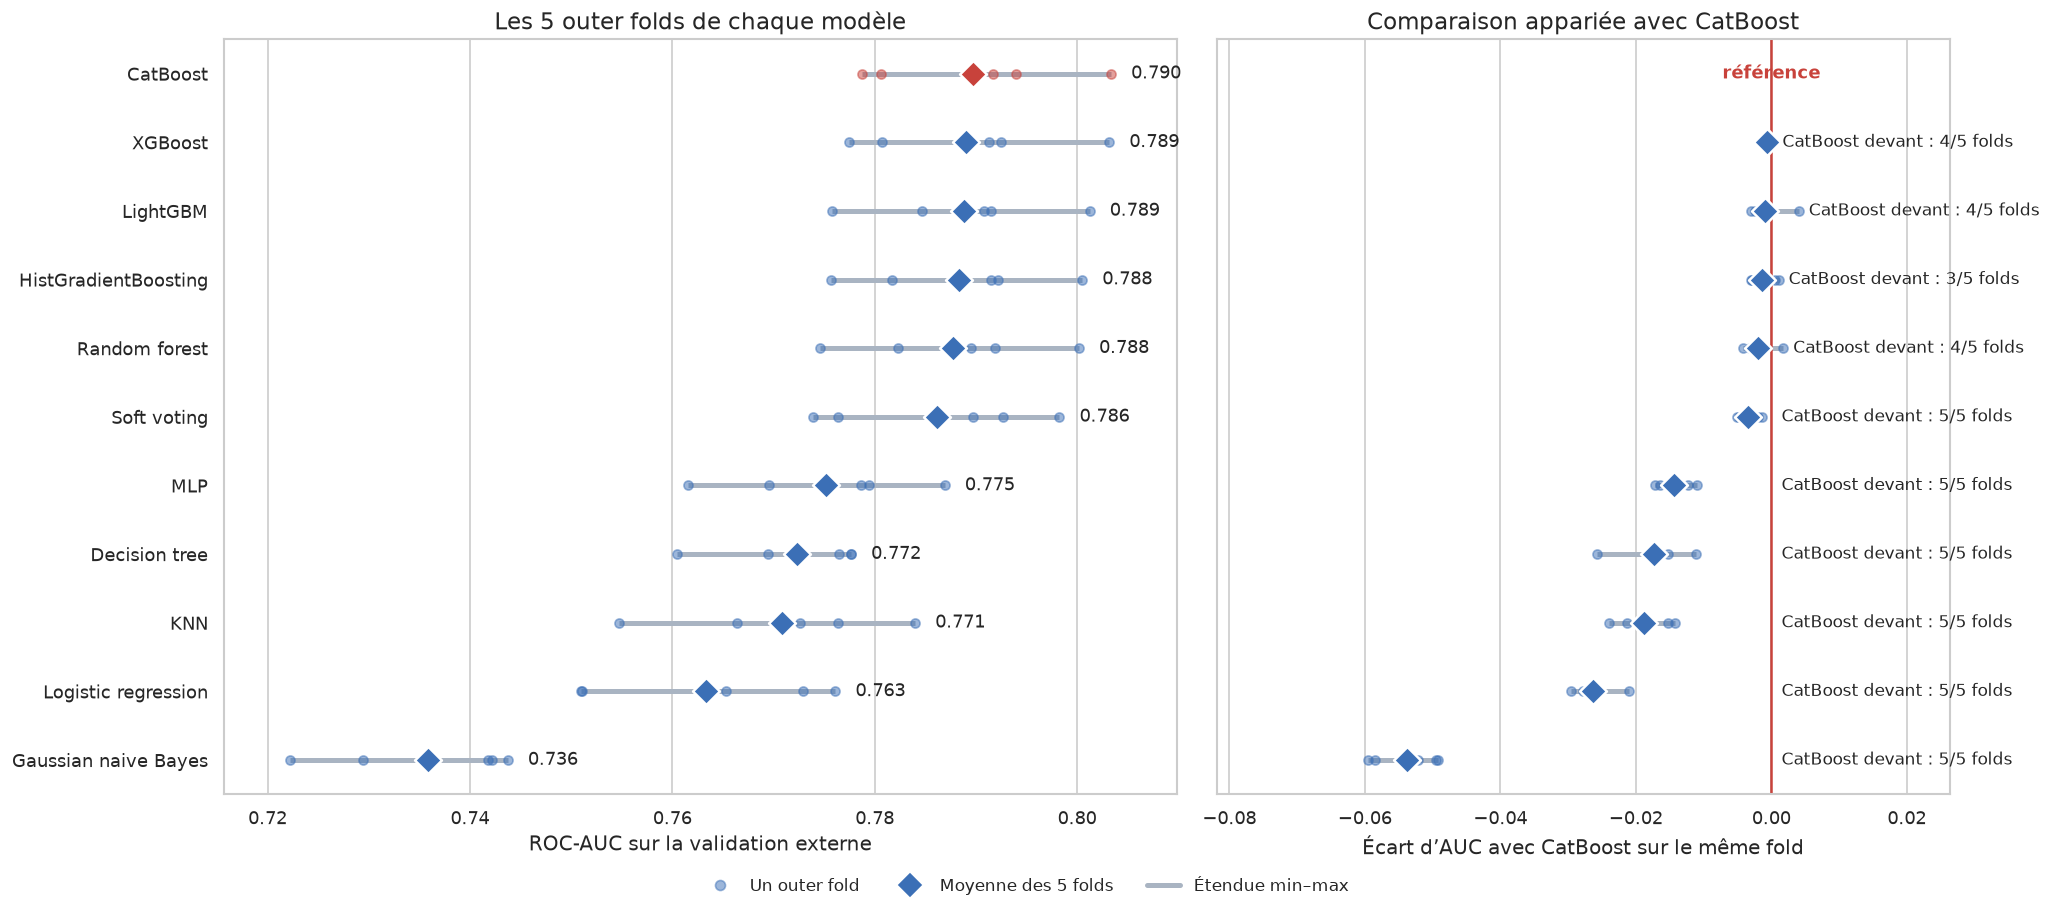

Explication : CatBoost obtient la meilleure moyenne individuelle (0,7897), devant XGBoost (0,7890). Le panneau de droite compare chaque modèle au meilleur **sur le même fold**, ce qui retire la variabilité commune aux folds. Pour Random forest, HistGradientBoosting, XGBoost, LightGBM, l’écart change de signe selon le fold : le classement entre eux n’est pas stable. Ce graphique décrit 5 folds ; il ne constitue pas un test statistique de différence entre modèles.

In [43]:
bilan_externe=tableau_scores(resultat_hpo)
display(bilan_externe.round(4))
_scores_plis = resultat_hpo['scores'].pivot(index='Fold', columns='Modèle', values='AUC')
_meilleur_cv = choisir_modele(bilan_externe)
_ordre = list(bilan_externe.index[::-1])                  # meilleur en haut
_ecarts_plis = _scores_plis.sub(_scores_plis[_meilleur_cv], axis=0)

fig, axes = plt.subplots(1, 2, figsize=(17, 7.5), layout='constrained', sharey=True,
                         gridspec_kw={'width_ratios': [1.3, 1]})
ax = axes[0]
for i, nom in enumerate(_ordre):
    valeurs = _scores_plis[nom]
    couleur = ROUGE if nom == _meilleur_cv else BLEU
    ax.hlines(i, valeurs.min(), valeurs.max(), color='#A9B4C2', lw=3, zorder=1)
    ax.scatter(valeurs, np.full(len(valeurs), i), s=30, color=couleur, alpha=.5, zorder=2)
    ax.scatter(valeurs.mean(), i, s=130, marker='D', color=couleur, edgecolor='white', linewidth=1.5, zorder=3)
    ax.text(valeurs.max() + .002, i, f'{valeurs.mean():.3f}', va='center', fontsize=11)
ax.set_yticks(range(len(_ordre)), [NOMS_MODELES.get(n, n) for n in _ordre])
ax.set(xlabel='ROC-AUC sur la validation externe', title='Les 5 outer folds de chaque modèle')
ax.margins(x=.08)
ax.grid(axis='y', visible=False)

ax = axes[1]
for i, nom in enumerate(_ordre):
    if nom == _meilleur_cv:
        ax.text(0, i, 'référence', ha='center', va='center', fontsize=11, color=ROUGE, weight='bold')
        continue
    ecarts = _ecarts_plis[nom]
    ax.hlines(i, ecarts.min(), ecarts.max(), color='#A9B4C2', lw=3, zorder=1)
    ax.scatter(ecarts, np.full(len(ecarts), i), s=30, color=BLEU, alpha=.5, zorder=2)
    ax.scatter(ecarts.mean(), i, s=130, marker='D', color=BLEU, edgecolor='white', linewidth=1.5, zorder=3)
    ax.text(max(ecarts.max(), 0) + .0015, i, f'{_meilleur_cv} devant : {int((ecarts < 0).sum())}/5 folds', va='center', fontsize=10)
ax.axvline(0, color=ROUGE, lw=1.5)
ax.set(xlabel=f'Écart d’AUC avec {_meilleur_cv} sur le même fold',
       title=f'Comparaison appariée avec {_meilleur_cv}')
ax.margins(x=.35)
ax.grid(axis='y', visible=False)
fig.legend(handles=[Line2D([], [], marker='o', ls='', color=BLEU, alpha=.5, label='Un outer fold'),
                    Line2D([], [], marker='D', ls='', color=BLEU, markersize=9, label='Moyenne des 5 folds'),
                    Line2D([], [], color='#A9B4C2', lw=3, label='Étendue min–max')],
           loc='outside lower center', ncol=3, frameon=False)
plt.show()

_individuels=bilan_externe.loc[MODELES].sort_values('AUC externe moyenne',ascending=False)
_indecis = [NOMS_MODELES.get(n, n) for n in MODELES
            if n != _meilleur_cv and (_ecarts_plis[n] > 0).any() and (_ecarts_plis[n] < 0).any()]
display(Markdown(f'Explication : {_individuels.index[0]} obtient la meilleure moyenne individuelle '
    f'({_individuels.iloc[0]["AUC externe moyenne"]:.4f}), devant {_individuels.index[1]} '
    f'({_individuels.iloc[1]["AUC externe moyenne"]:.4f}). '
    'Le panneau de droite compare chaque modèle au meilleur **sur le même fold**, ce qui retire la variabilité commune aux folds. '
    + (f'Pour {", ".join(_indecis)}, l’écart change de signe selon le fold : le classement entre eux n’est pas stable. '
       if _indecis else '')
    + 'Ce graphique décrit 5 folds ; il ne constitue pas un test statistique de différence entre modèles.'))

In [44]:
print("Hyperparamètres retenus sur chaque pli externe")
for nom in MODELES:
    display(Markdown(f"{nom}"))
    display(tableau_params_pli(resultat_hpo, nom).round(4))


Hyperparamètres retenus sur chaque pli externe


Logistic regression

,AUC,C,class_weight
Fold,,,
0,0.7653,0.0102,balanced
1,0.7729,0.0112,balanced
2,0.7511,0.0118,balanced
3,0.7509,0.1423,balanced
4,0.7761,0.1481,balanced


KNN

,AUC,n_neighbors,weights,p
Fold,,,,
0,0.7764,160,distance,1
1,0.7726,120,distance,1
2,0.7663,120,uniform,1
3,0.7547,200,distance,1
4,0.7840,120,uniform,1


Gaussian naive Bayes

... (11 outputs left out)

CatBoost

,AUC,iterations,depth,learning_rate,l2_leaf_reg,auto_class_weights
Fold,,,,,,
0,0.7917,200,7,0.0411,15.3733,Balanced
1,0.7939,400,7,0.0242,6.4672,NaN
2,0.7806,400,5,0.0268,1.3183,Balanced
3,0.7787,400,7,0.0279,13.9760,NaN
4,0.8033,200,6,0.0474,13.0498,NaN


MLP

,AUC,hidden_layer_sizes,alpha,learning_rate_init
Fold,,,,
0,0.7794,64,0.0106,0.0033
1,0.7787,64,0.0921,0.0015
2,0.7696,64,0.0096,0.0037
3,0.7616,"32,16",0.0013,0.0049
4,0.7869,32,0.0764,0.0081


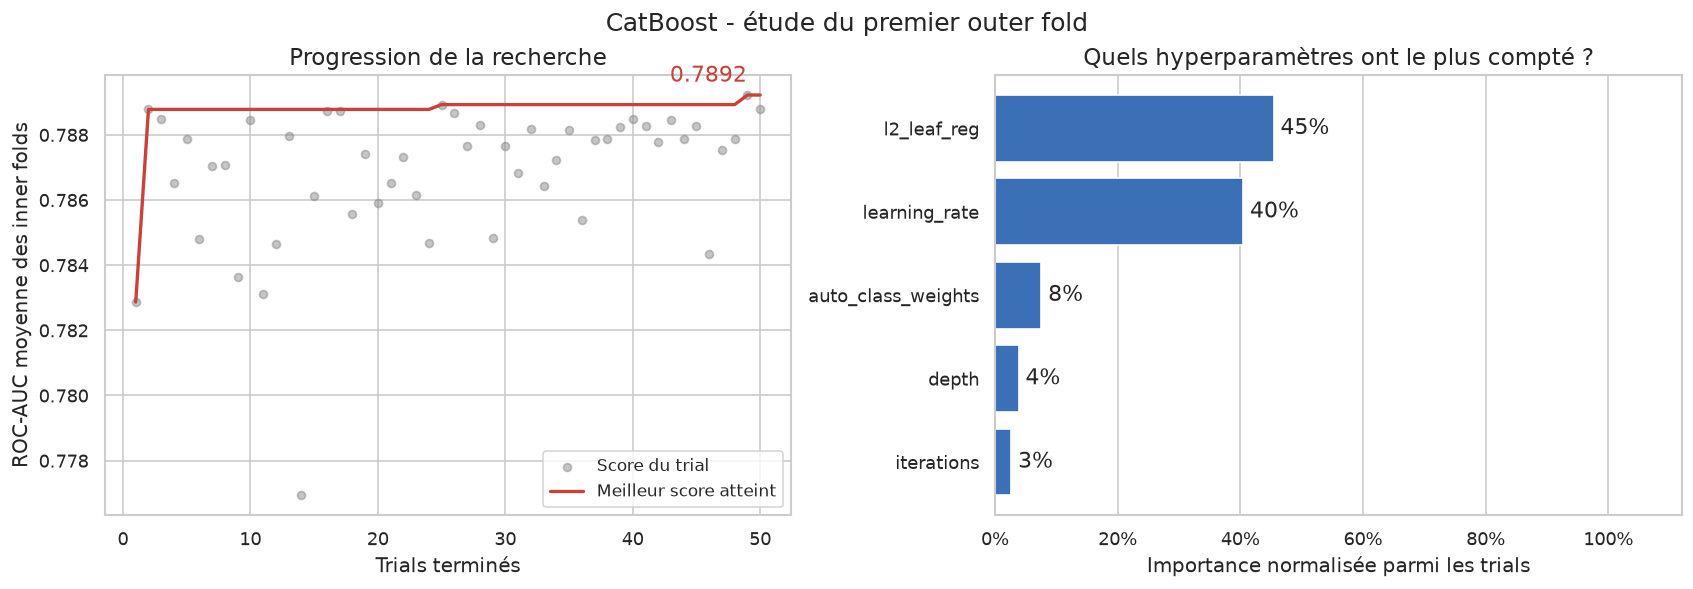

Explication : Le meilleur score interne passe de 0,7829 au premier trial terminé à 0,7892, soit +0,0064. `l2_leaf_reg` explique la plus grande part de variation entre ces trials (45 % de l’importance normalisée). Ces importances concernent les hyperparamètres explorés, pas les features ni un effet causal. Le score interne sert au tuning.

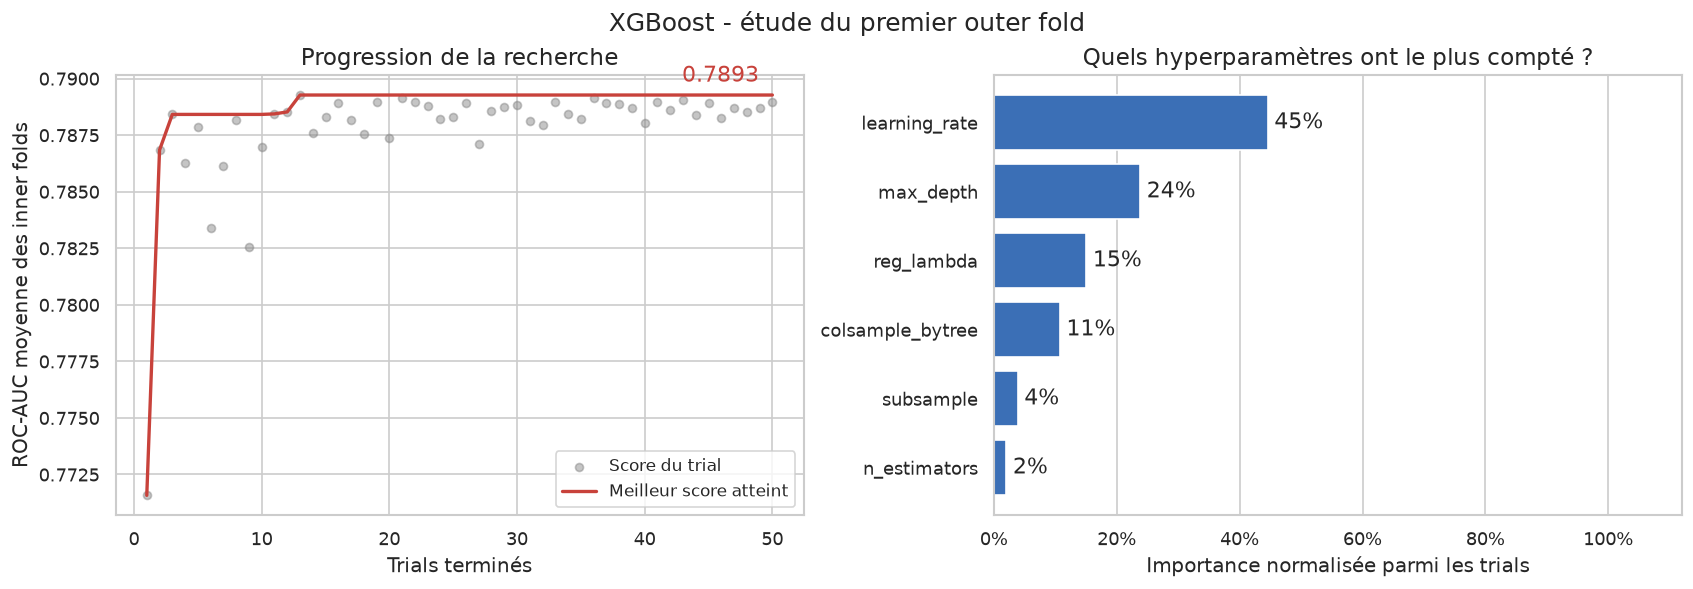

Explication : Le meilleur score interne passe de 0,7716 au premier trial terminé à 0,7893, soit +0,0177. `learning_rate` explique la plus grande part de variation entre ces trials (45 % de l’importance normalisée). Ces importances concernent les hyperparamètres explorés, pas les features ni un effet causal. Le score interne sert au tuning.

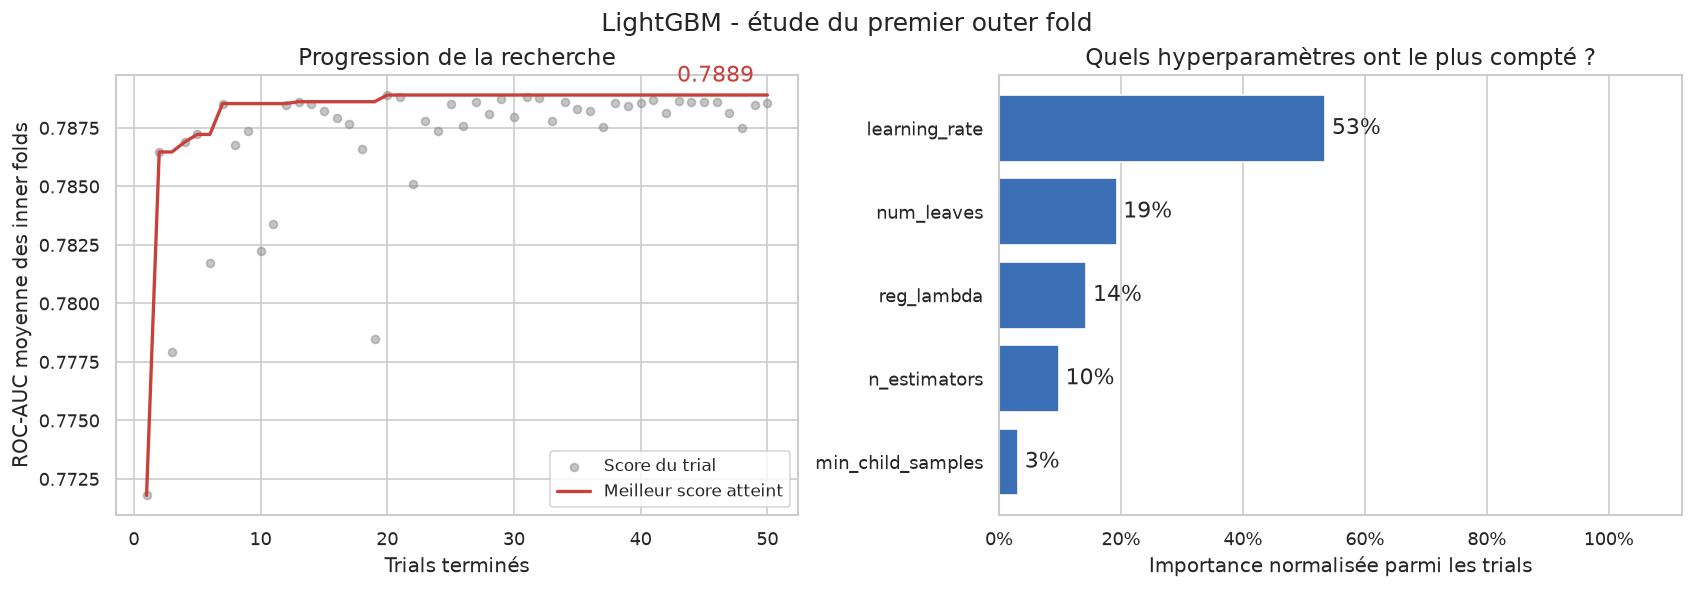

Explication : Le meilleur score interne passe de 0,7718 au premier trial terminé à 0,7889, soit +0,0171. `learning_rate` explique la plus grande part de variation entre ces trials (53 % de l’importance normalisée). Ces importances concernent les hyperparamètres explorés, pas les features ni un effet causal. Le score interne sert au tuning.

In [45]:
def montrer_etude(etude,titre):
    trials=[t for t in etude.trials if t.state==optuna.trial.TrialState.COMPLETE]
    x=np.arange(1,len(trials)+1);y=np.array([t.value for t in trials])
    meilleur=np.maximum.accumulate(y)
    fig,axes=plt.subplots(1,2,figsize=(14,4.8),layout='constrained')
    axes[0].scatter(x,y,color='grey',alpha=.45,s=23,label='Score du trial')
    axes[0].plot(x,meilleur,color=ROUGE,lw=2,label='Meilleur score atteint')
    axes[0].set(xlabel='Trials terminés',ylabel='ROC-AUC moyenne des inner folds',title='Progression de la recherche')
    axes[0].legend(loc='lower right')
    axes[0].annotate(f'{etude.best_value:.4f}',(x[-1],meilleur[-1]),xytext=(-8,8),
                     textcoords='offset points',ha='right',color=ROUGE)
    from optuna.importance import get_param_importances, FanovaImportanceEvaluator
    imp=get_param_importances(etude,evaluator=FanovaImportanceEvaluator(seed=SEED))
    valeurs=pd.Series(imp,dtype=float).sort_values()
    bars=axes[1].barh(valeurs.index,valeurs.values,color=BLEU)
    axes[1].bar_label(bars,labels=[f'{v:.0%}' for v in valeurs.values],padding=4)
    axes[1].set(xlim=(0,1.12),xlabel='Importance normalisée parmi les trials',title='Quels hyperparamètres ont le plus compté ?')
    axes[1].xaxis.set_major_formatter(PercentFormatter(1))
    axes[1].grid(axis='y',visible=False)
    fig.suptitle(titre,fontsize=15)
    plt.show()
    texte=(f'Explication : Le meilleur score interne passe de {y[0]:.4f} au premier trial terminé '
           f'à {etude.best_value:.4f}, soit {etude.best_value-y[0]:+.4f}. ')
    if len(valeurs):
        texte+=f'`{valeurs.idxmax()}` explique la plus grande part de variation entre ces trials ({valeurs.max():.0%} de l’importance normalisée). '
    texte+='Ces importances concernent les hyperparamètres explorés, pas les features ni un effet causal. Le score interne sert au tuning.'
    display(Markdown(texte))

# Trois études lisibles ; les scores et paramètres des dix modèles restent dans les tableaux.
_top_etudes=bilan_externe.loc[MODELES].nlargest(3,'AUC externe moyenne').index
for nom in _top_etudes:
    montrer_etude(resultat_hpo['etudes_pli0'][nom],f'{nom} - étude du premier outer fold')


Explication

Les scores affichés ici sont internes : ils servent au tuning. Un plateau signifie que les derniers trials améliorent peu le meilleur score ; le classement des familles repose sur les outer folds.

Dans les boostings, `learning_rate` règle l’ampleur des corrections, `depth` limite la complexité des arbres et `l2_leaf_reg` / `reg_lambda` régularisent leurs poids. Les importances montrent lesquels de ces réglages ont compté dans les plages testées, sans donner un classement universel. Elles ne mesurent pas l’importance des features.

Les courbes suivent les 50 trials terminés de chaque étude.


### 3.4.3 Choix du modèle et tuning final

On retient la famille individuelle avec la meilleure ROC-AUC externe moyenne. Une nouvelle recherche de 50 trials utilise ensuite les 23 972 observations de train, avec cinq inner folds : chaque fit utilise 19 177 ou 19 178 observations et prédit les 4 794 ou 4 795 autres.

Les hyperparamètres étant fixés, les prédictions OOF du train servent à choisir le threshold qui maximise le F1. On refit enfin le modèle sur les 23 972 observations et on l’évalue une seule fois sur les 5 993 observations du test. Le score interne du tuning final et le score OOF ne remplacent pas cette évaluation réservée.


Modèle retenu : CatBoost


,Valeur
iterations,400
depth,6
learning_rate,0.02329
l2_leaf_reg,2.945636
auto_class_weights,Balanced


Meilleure AUC interne de la recherche finale : 0.7902


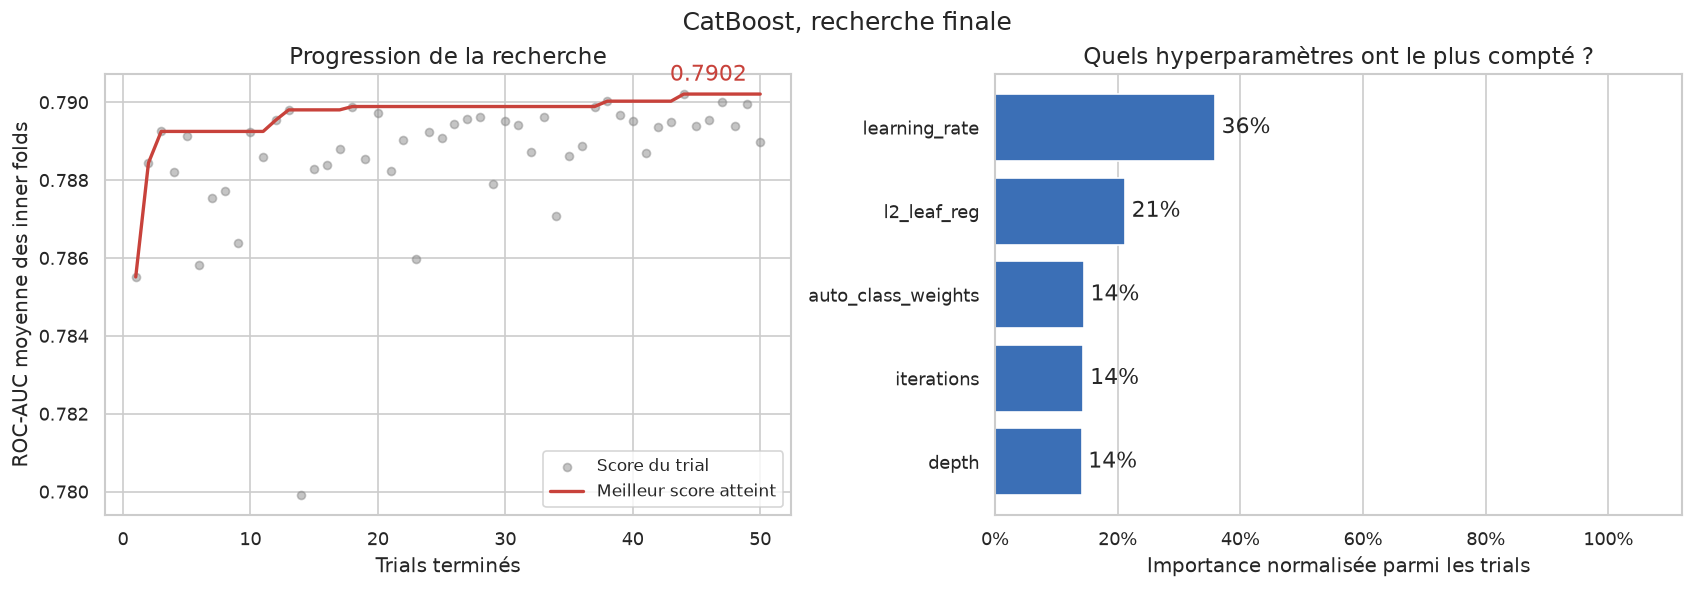

Explication : Le meilleur score interne passe de 0,7855 au premier trial terminé à 0,7902, soit +0,0047. `learning_rate` explique la plus grande part de variation entre ces trials (36 % de l’importance normalisée). Ces importances concernent les hyperparamètres explorés, pas les features ni un effet causal. Le score interne sert au tuning.

In [46]:
nom_retenu = choisir_modele(bilan_externe)
print("Modèle retenu :", nom_retenu)

etude_finale = etude_finale(
    nom_retenu,
    X_train_plus,
    y_train,
    seed=SEED,
    n_trials=N_TRIALS,
    n_splits=N_SPLITS,
)
params_finaux = etude_finale.best_params
display(pd.Series(params_finaux, name="Valeur").to_frame())
print(f"Meilleure AUC interne de la recherche finale : {etude_finale.best_value:.4f}")
montrer_etude(etude_finale, f"{nom_retenu}, recherche finale")

proba_oof_final = cross_val_predict(
    construire(nom_retenu, params_finaux),
    X_train_plus,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=1,
)[:, 1]


### 3.4.4 Soft voting

Le soft voting moyenne les scores de logistic regression, random forest et du boosting choisi dans les inner folds. Pour chaque outer fold, le choix du boosting utilise les scores internes seulement. La moyenne des probabilités est ensuite évaluée sur la validation externe du même tour.

On compare le vote au meilleur modèle individuel dans le tableau suivant. Un gain très faible ne justifie pas automatiquement de maintenir trois modèles plutôt qu’un.


In [47]:
ligne_vote = "Vote (logistique + forêt + boosting du pli)"
display(bilan_externe.loc[[ligne_vote, choisir_modele(bilan_externe)]].round(4))

_gain_vote=bilan_externe.loc[ligne_vote,'AUC externe moyenne']-bilan_externe.loc[nom_retenu,'AUC externe moyenne']
display(Markdown(f'Explication : la ROC-AUC externe moyenne du vote est de {bilan_externe.loc[ligne_vote,"AUC externe moyenne"]:.4f}, '
    f'contre {bilan_externe.loc[nom_retenu,"AUC externe moyenne"]:.4f} pour {nom_retenu}, soit un écart de {_gain_vote:+.4f}. '
    'La moyenne des scores ne garantit donc pas un meilleur classement ; des erreurs proches entre modèles limitent son intérêt.'))


,AUC externe moyenne,Écart-type externe,AUC externe min,AUC externe max
Modèle,,,,
Vote (logistique + forêt + boosting du pli),0.7862,0.0106,0.7739,0.7982
CatBoost,0.7897,0.0101,0.7787,0.8033


Explication : la ROC-AUC externe moyenne du vote est de 0,7862, contre 0,7897 pour CatBoost, soit un écart de -0,0035. La moyenne des scores ne garantit donc pas un meilleur classement ; des erreurs proches entre modèles limitent son intérêt.

### 3.4.5 Choix du threshold

On compare les métriques au threshold de 0,50, puis on choisit celui qui maximise le F1 sur les prédictions OOF du train. Abaisser le threshold augmente généralement le recall et les fausses alertes. Le F1 donne ici le même poids à la precision et au recall ; un coût métier explicite pourrait conduire à un autre choix. La ROC-AUC utilise les scores continus et ne dépend pas de ce threshold.


,AUC,Accuracy,Precision,Recall,F1
"Threshold 0,50",0.79,0.756,0.463,0.650,0.541
Threshold 0.54,0.79,0.777,0.497,0.616,0.550


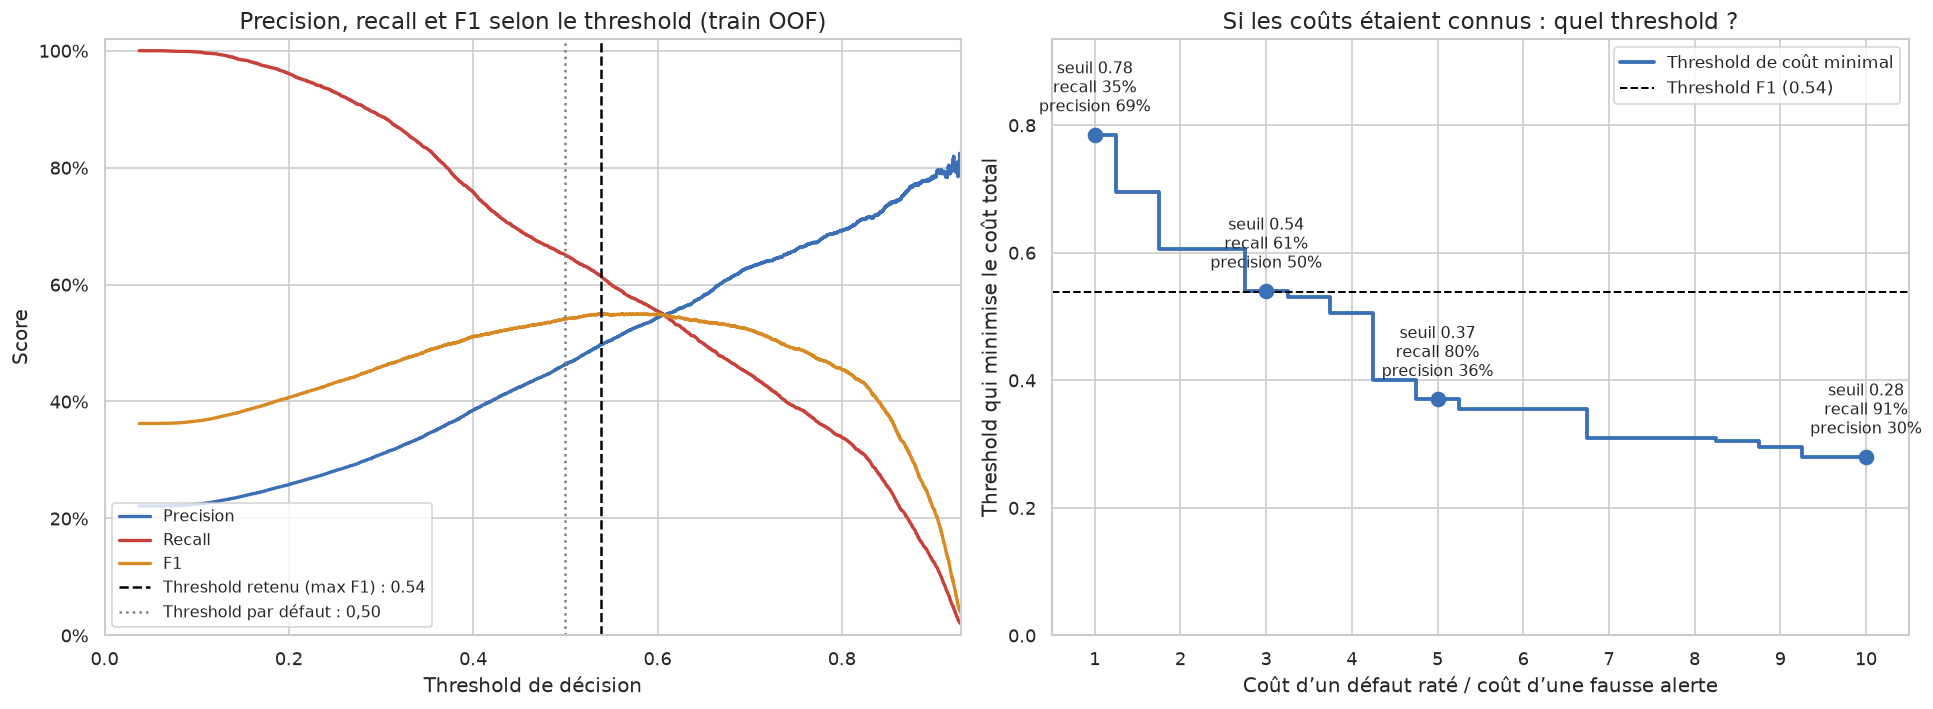

Explication : en passant de 0,50 à 0,54, le recall passe de 65,0 % à 61,6 %, la precision de 46,3 % à 49,7 %, et le F1 de 0,541 à 0,550. Le threshold F1 correspond à peu près à un défaut raté qui coûterait 3 fois une fausse alerte. Si un défaut raté coûte nettement plus cher, le threshold de coût minimal baisse et le modèle émet davantage d’alertes. Les rapports de coût sont ici des hypothèses ; on garde le threshold F1 pour la suite, et il reste à vérifier sur le test réservé.

In [48]:
proba_oof=proba_oof_final
precision,rappel,seuils=precision_recall_curve(y_train,proba_oof)
f1=2*precision[:-1]*rappel[:-1]/(precision[:-1]+rappel[:-1]+1e-12)
SEUIL=float(seuils[np.argmax(f1)])
comparaison_seuil=pd.DataFrame({
    'Threshold 0,50':calculer_metriques(y_train,proba_oof,.5),
    f'Threshold {SEUIL:.2f}':calculer_metriques(y_train,proba_oof,SEUIL)}).T
display(comparaison_seuil.round(3))

# Seuil qui minimise le coût total pour un rapport coût(défaut raté) / coût(fausse alerte) donné
vrais_train = y_train.to_numpy()
grille_seuils = np.linspace(.05, .95, 181)
alertes = proba_oof[None, :] >= grille_seuils[:, None]
nb_fn = ((~alertes) & (vrais_train == 1)).sum(axis=1)
nb_fp = (alertes & (vrais_train == 0)).sum(axis=1)
ratios_cout = np.arange(1, 10.5, .5)
seuils_cout = np.array([grille_seuils[np.argmin(r * nb_fn + nb_fp)] for r in ratios_cout])

fig,axes=plt.subplots(1,2,figsize=(16,5.8),layout='constrained')
ax = axes[0]
x_max = float(np.quantile(proba_oof, .995))       # au-delà, trop peu de clients : precision instable
garde = seuils <= x_max
for y,couleur,nom in [(precision[:-1],BLEU,'Precision'),(rappel[:-1],ROUGE,'Recall'),(f1,ORANGE,'F1')]:
    ax.plot(seuils[garde],y[garde],color=couleur,lw=2,label=nom)
ax.axvline(SEUIL,color='black',ls='--',label=f'Threshold retenu (max F1) : {SEUIL:.2f}')
ax.axvline(.5,color='grey',ls=':',label='Threshold par défaut : 0,50')
ax.set(xlabel='Threshold de décision',ylabel='Score',title='Precision, recall et F1 selon le threshold (train OOF)',
       xlim=(0,x_max),ylim=(0,1.02))
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.legend(fontsize=9.5,loc='lower left')

ax = axes[1]
ax.step(ratios_cout, seuils_cout, where='mid', color=BLEU, lw=2.3, label='Threshold de coût minimal')
ax.axhline(SEUIL, color='black', ls='--', lw=1.2, label=f'Threshold F1 ({SEUIL:.2f})')
for r in [1, 3, 5, 10]:
    s = float(seuils_cout[ratios_cout == r][0])
    m = calculer_metriques(y_train, proba_oof, s)
    ax.scatter(r, s, s=70, color=BLEU, zorder=3)
    ax.annotate(f'seuil {s:.2f}\nrecall {m["Recall"]:.0%}\nprecision {m["Precision"]:.0%}', (r, s),
                xytext=(0, 14), textcoords='offset points', ha='center', fontsize=9.5)
ax.set(xlabel='Coût d’un défaut raté / coût d’une fausse alerte', ylabel='Threshold qui minimise le coût total',
       title='Si les coûts étaient connus : quel threshold ?', xlim=(.5, 10.5),
       ylim=(0, max(.9, float(seuils_cout.max()) + .15)))
ax.set_xticks([1, 2, 3, 4, 5, 6, 7, 8, 9, 10])
ax.legend(loc='upper right', fontsize=10)
plt.show()

_a,_b=comparaison_seuil.iloc[0],comparaison_seuil.iloc[1]
_r_egal = ratios_cout[np.argmin(np.abs(seuils_cout - SEUIL))]
display(Markdown(f'Explication : en passant de 0,50 à {SEUIL:.2f}, le recall passe de '
    f'{_a.Recall:.1%} à {_b.Recall:.1%}, la precision de {_a.Precision:.1%} à '
    f'{_b.Precision:.1%}, et le F1 de {_a.F1:.3f} à {_b.F1:.3f}. '
    f'Le threshold F1 correspond à peu près à un défaut raté qui coûterait {_r_egal:g} fois une fausse alerte. '
    'Si un défaut raté coûte nettement plus cher, le threshold de coût minimal baisse et le modèle émet davantage d’alertes. '
    'Les rapports de coût sont ici des hypothèses ; on garde le threshold F1 pour la suite, et il reste à vérifier sur le test réservé.'))

Le tableau compare le threshold 0,5 et celui qui maximise le F1 sur les prédictions out-of-fold. L'AUC ne change pas : le classement des clients est le même, seule la décision change. Le threshold est choisi à partir de ces prédictions, jamais à partir du test.

Le panneau de droite illustre ce qu'on ferait dans un vrai projet bancaire : fixer le threshold à partir des coûts. Pour chaque rapport « coût d'un défaut raté / coût d'une fausse alerte », on cherche le threshold qui minimise le coût total sur les prédictions OOF. Avec des probabilités bien calibrées, ce threshold vaudrait 1/(1 + rapport) : 0,50 pour un rapport de 1, 0,09 pour un rapport de 10. Les seuils obtenus sont nettement plus hauts (0,78 et 0,28) parce que les scores sont gonflés par la pondération des classes (§ 3.4.6 et § 3.5.1) : le threshold doit donc être choisi sur ces scores, pas déduit de la formule. Les vrais coûts doivent venir du métier.

### 3.4.6 Pondération des classes

La pondération agit pendant l’apprentissage ; le threshold agit ensuite sur les scores. On rappelle ici le réglage de pondération retenu par le tuning. Il fait partie du modèle final et n’est pas présenté comme une expérience indépendante lorsque la même configuration a déjà été évaluée.


In [49]:
_pond={cle:valeur for cle,valeur in params_finaux.items()
       if cle in ('class_weight','auto_class_weights','scale_pos_weight')}
if _pond:
    display(pd.Series(_pond,name='Réglage retenu').to_frame())
else:
    print('Aucun réglage de pondération n’a été retenu dans cet espace de recherche.')
display(Markdown(
    f'Explication : le train contient {y_train.mean():.1%} de défauts. '
    'Une pondération donne davantage de poids aux erreurs sur la classe minoritaire pendant le fit. '
    'Cela déplace les scores vers le haut sans changer la fréquence réelle des défauts ; la calibration est mesurée en § 3.5.1. '
    'Le threshold est choisi après le tuning sur les prédictions OOF ; il ne suffit donc pas à interpréter le score comme un risque absolu.'
))


,Réglage retenu
auto_class_weights,Balanced


Explication : le train contient 22,1 % de défauts. Une pondération donne davantage de poids aux erreurs sur la classe minoritaire pendant le fit. Cela déplace les scores vers le haut sans changer la fréquence réelle des défauts ; la calibration est mesurée en § 3.5.1. Le threshold est choisi après le tuning sur les prédictions OOF ; il ne suffit donc pas à interpréter le score comme un risque absolu.

La pondération et le threshold jouent deux rôles différents. La première change le modèle appris ; le second change les décisions obtenues à partir de ses scores. Pour le test, on conserve la configuration et le threshold fixés avec le train.


### 3.4.7 Learning curve

On regarde comment la ROC-AUC évolue avec la taille du train set. L’écart entre score train et score de validation aide à repérer l’overfitting ; la tendance du score de validation donne une indication sur l’intérêt de nouvelles données.

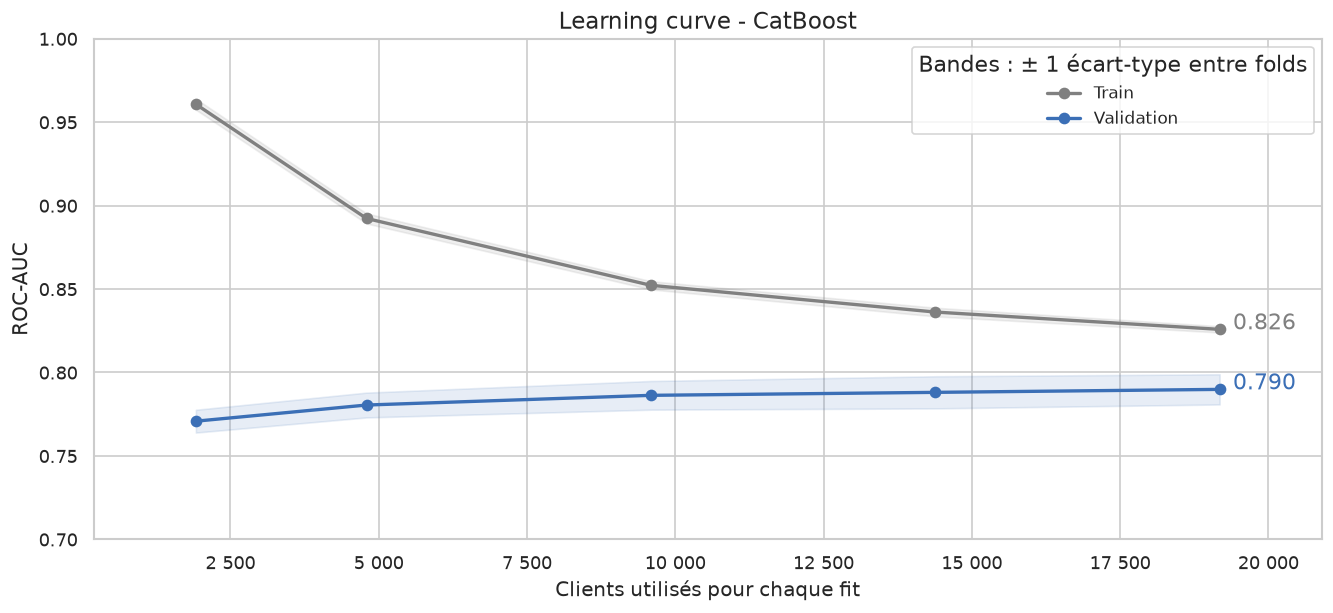

,Clients,ROC-AUC train,ROC-AUC validation
0,1917,0.961,0.771
1,4794,0.892,0.780
2,9588,0.852,0.786
3,14382,0.836,0.788
4,19177,0.826,0.790


In [50]:
tailles, scores_train_lc, scores_cv_lc = learning_curve(
    construire(nom_retenu, params_finaux),
    X_train_plus,
    y_train,
    train_sizes=[0.1, 0.25, 0.5, 0.75, 1.0],
    cv=cv,
    scoring="roc_auc",
    n_jobs=1,
)

fig,ax=plt.subplots(figsize=(11,5),layout='constrained')
for scores,couleur,nom in [(scores_train_lc,'grey','Train'),(scores_cv_lc,BLEU,'Validation')]:
    moyenne=scores.mean(axis=1);dispersion=scores.std(axis=1)
    ax.plot(tailles,moyenne,marker='o',lw=2,color=couleur,label=nom)
    ax.fill_between(tailles,moyenne-dispersion,moyenne+dispersion,color=couleur,alpha=.12)
    ax.annotate(f'{moyenne[-1]:.3f}',(tailles[-1],moyenne[-1]),xytext=(8,0),textcoords='offset points',color=couleur)
ax.set(xlabel='Clients utilisés pour chaque fit',ylabel='ROC-AUC',title=f'Learning curve - {nom_retenu}',ylim=(.7,1.0))
ax.xaxis.set_major_formatter(FuncFormatter(lambda x,pos:f'{x:,.0f}'.replace(',',' ')))
ax.margins(x=.1)
ax.legend(title='Bandes : ± 1 écart-type entre folds')
plt.show()
display(pd.DataFrame({'Clients':tailles,'ROC-AUC train':scores_train_lc.mean(axis=1),
                     'ROC-AUC validation':scores_cv_lc.mean(axis=1)}).round(3))


In [51]:
display(Markdown(
    f"Explication : Avec {tailles[0]:,} clients, la ROC-AUC vaut "
    f"{scores_train_lc[0].mean():.3f} sur le train et {scores_cv_lc[0].mean():.3f} en validation. "
    f"Avec {tailles[-1]:,} clients, ces scores deviennent {scores_train_lc[-1].mean():.3f} "
    f"et {scores_cv_lc[-1].mean():.3f}. "
    "Un écart qui se réduit avec davantage de données indique que l’overfitting diminue. "
    "La courbe de validation permet aussi de voir si davantage de données apporte encore un gain."
))

Explication : Avec 1 917 clients, la ROC-AUC vaut 0,961 sur le train et 0,771 en validation. Avec 19 177 clients, ces scores deviennent 0,826 et 0,790. Un écart qui se réduit avec davantage de données indique que l’overfitting diminue. La courbe de validation permet aussi de voir si davantage de données apporte encore un gain.

## 3.5 Résultats sur le test set

Le modèle, ses hyperparamètres, les 31 features et le threshold sont maintenant fixés à partir du train. On entraîne le modèle retenu sur tout le train, puis on ouvre le test set une seule fois pour calculer ROC-AUC, accuracy, precision, recall et F1. Les effectifs de la confusion matrix permettent de relier ces scores aux défauts manqués et aux fausses alertes.


Dans la ROC, `PAY_1` est utilisé comme un score de retard pour faire varier le threshold. Les métriques de la règle fixe `PAY_1 ≥ 1` sont données séparément dans le tableau.


,AUC,Accuracy,Precision,Recall,F1
Validation hors pli (entraînement),0.790,0.777,0.497,0.616,0.550
Test,0.780,0.774,0.492,0.600,0.541
Règle PAY_1 ≥ 1 sur le test,0.687,0.778,0.498,0.503,0.501


Explication : CatBoost, threshold 0,54. La ROC-AUC est de 0,780 sur le test contre 0,790 sur les prédictions OOF du train : l’écart est faible. 796 défauts sont détectés, 530 sont manqués et 823 alertes sont fausses, soit un recall de 60,0 % et une precision de 49,2 %. La règle `PAY_1 ≥ 1` obtient une AUC de 0,687 et un F1 de 0,501. Ces résultats restent propres à cette population.

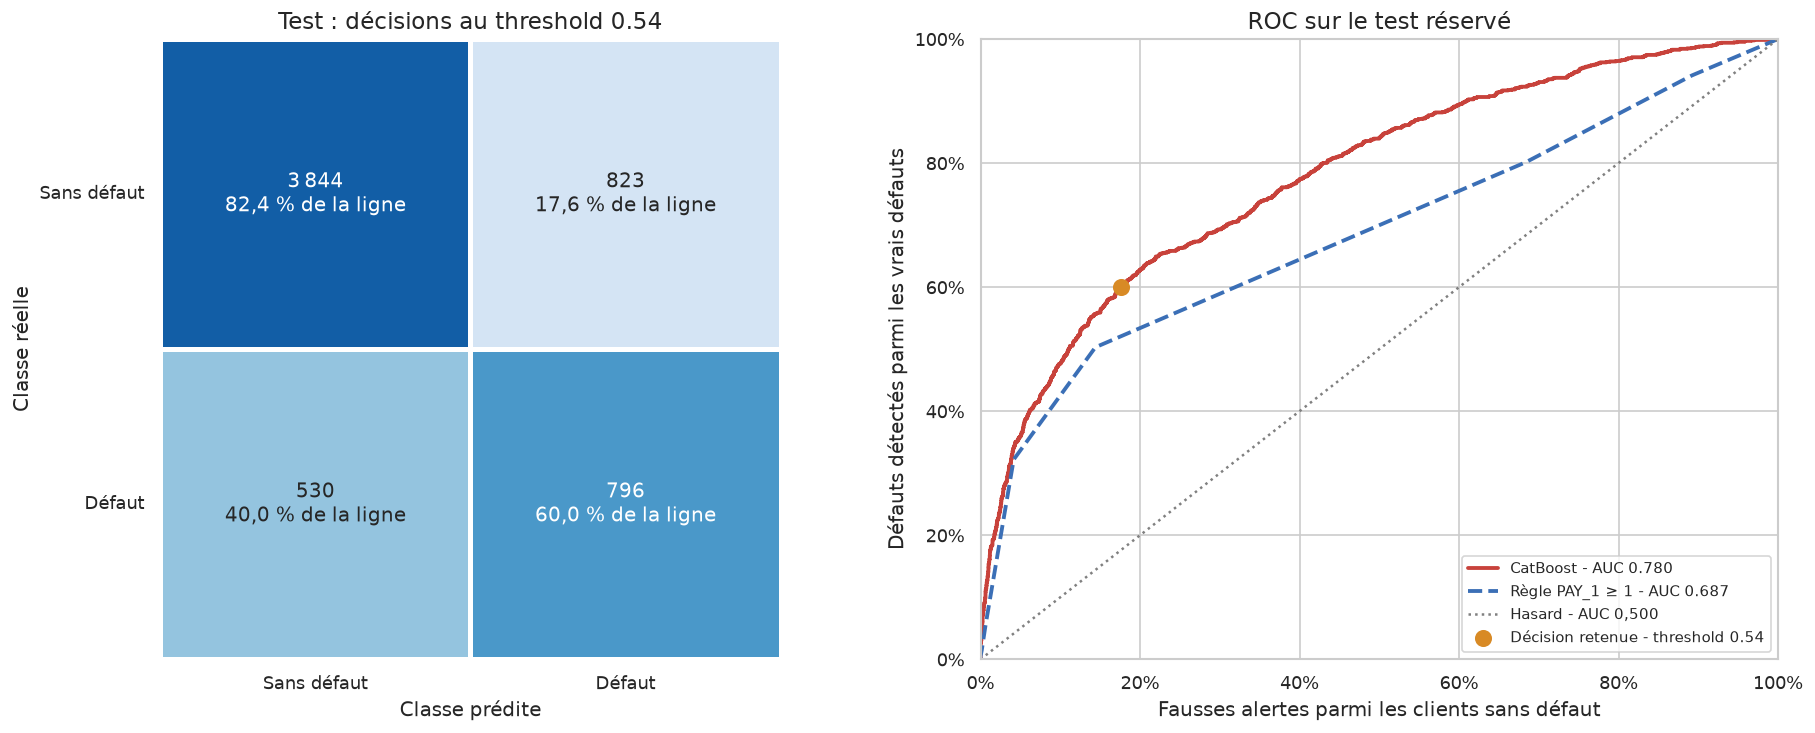

In [52]:
modele_final = construire(nom_retenu, params_finaux)
modele_final.fit(X_train_plus, y_train)
proba_test = modele_final.predict_proba(X_test_plus)[:, 1]

final = pd.DataFrame({
    "Validation hors pli (entraînement)": calculer_metriques(y_train, proba_oof_final, SEUIL),
    "Test": calculer_metriques(y_test, proba_test, SEUIL),
    "Règle PAY_1 ≥ 1 sur le test": calculer_metriques(y_test, X_test["PAY_1"].values, 1),
}).T
display(final.round(3))

prediction = (proba_test >= SEUIL).astype(int)
vrais = y_test.to_numpy()
detectes = int(((prediction == 1) & (vrais == 1)).sum())
manques = int(((prediction == 0) & (vrais == 1)).sum())
fausses = int(((prediction == 1) & (vrais == 0)).sum())
display(Markdown(
    f"Explication : {nom_retenu}, threshold {SEUIL:.2f}. La ROC-AUC est de {final.loc['Test','AUC']:.3f} sur le test "
    f"contre {final.iloc[0]['AUC']:.3f} sur les prédictions OOF du train : l’écart est faible. "
    f"{detectes} défauts sont détectés, {manques} sont manqués et {fausses} alertes sont fausses, "
    f"soit un recall de {final.loc['Test','Recall']:.1%} et une precision de {final.loc['Test','Precision']:.1%}. "
    f"La règle `PAY_1 ≥ 1` obtient une AUC de {final.iloc[2]['AUC']:.3f} et un F1 de {final.iloc[2]['F1']:.3f}. "
    "Ces résultats restent propres à cette population."
))

fig,axes=plt.subplots(1,2,figsize=(15,6),layout='constrained')
_cm_test=matrice_lisible(y_test,prediction,axes[0],f'Test : décisions au threshold {SEUIL:.2f}')
for nom,score,couleur,style in [(nom_retenu,proba_test,ROUGE,'-'),
                               ('Règle PAY_1 ≥ 1',X_test['PAY_1'].values,BLEU,'--')]:
    fpr,tpr,_=roc_curve(y_test,score)
    axes[1].plot(fpr,tpr,style,color=couleur,lw=2.3,label=f'{nom} - AUC {roc_auc_score(y_test,score):.3f}')
axes[1].plot([0,1],[0,1],':',color='grey',label='Hasard - AUC 0,500')
_fpr_choisi=_cm_test[0,1]/_cm_test[0].sum()
_tpr_choisi=_cm_test[1,1]/_cm_test[1].sum()
axes[1].scatter(_fpr_choisi,_tpr_choisi,s=85,color=ORANGE,zorder=5,
                label=f'Décision retenue - threshold {SEUIL:.2f}')
axes[1].set(title='ROC sur le test réservé',xlabel='Fausses alertes parmi les clients sans défaut',
            ylabel='Défauts détectés parmi les vrais défauts',xlim=(0,1),ylim=(0,1))
axes[1].xaxis.set_major_formatter(PercentFormatter(1))
axes[1].yaxis.set_major_formatter(PercentFormatter(1))
axes[1].legend(loc='lower right',fontsize=9)
plt.show()



### 3.5.1 Lire les scores du test : séparation, calibration et ciblage

La confusion matrix ne montre qu’un seul threshold. Trois vues complètent la lecture des scores sur le test réservé :

- **Distribution des scores par classe** : plus les deux histogrammes sont décalés, mieux le modèle sépare les classes. Le trait vertical est le threshold retenu ; tout ce qui est à droite déclenche une alerte.
- **Calibration** : on regroupe les clients en 10 tranches de score et on compare le score moyen au taux de défaut réellement observé. Un modèle calibré suit la diagonale. Le Brier score résume l’écart (plus bas = mieux).
- **Courbe de gains** : si l’on contrôle d’abord les clients les plus risqués selon le modèle, quelle part des défauts trouve-t-on en contrôlant x % des clients ? C’est la lecture la plus directe pour un service de recouvrement à capacité limitée.


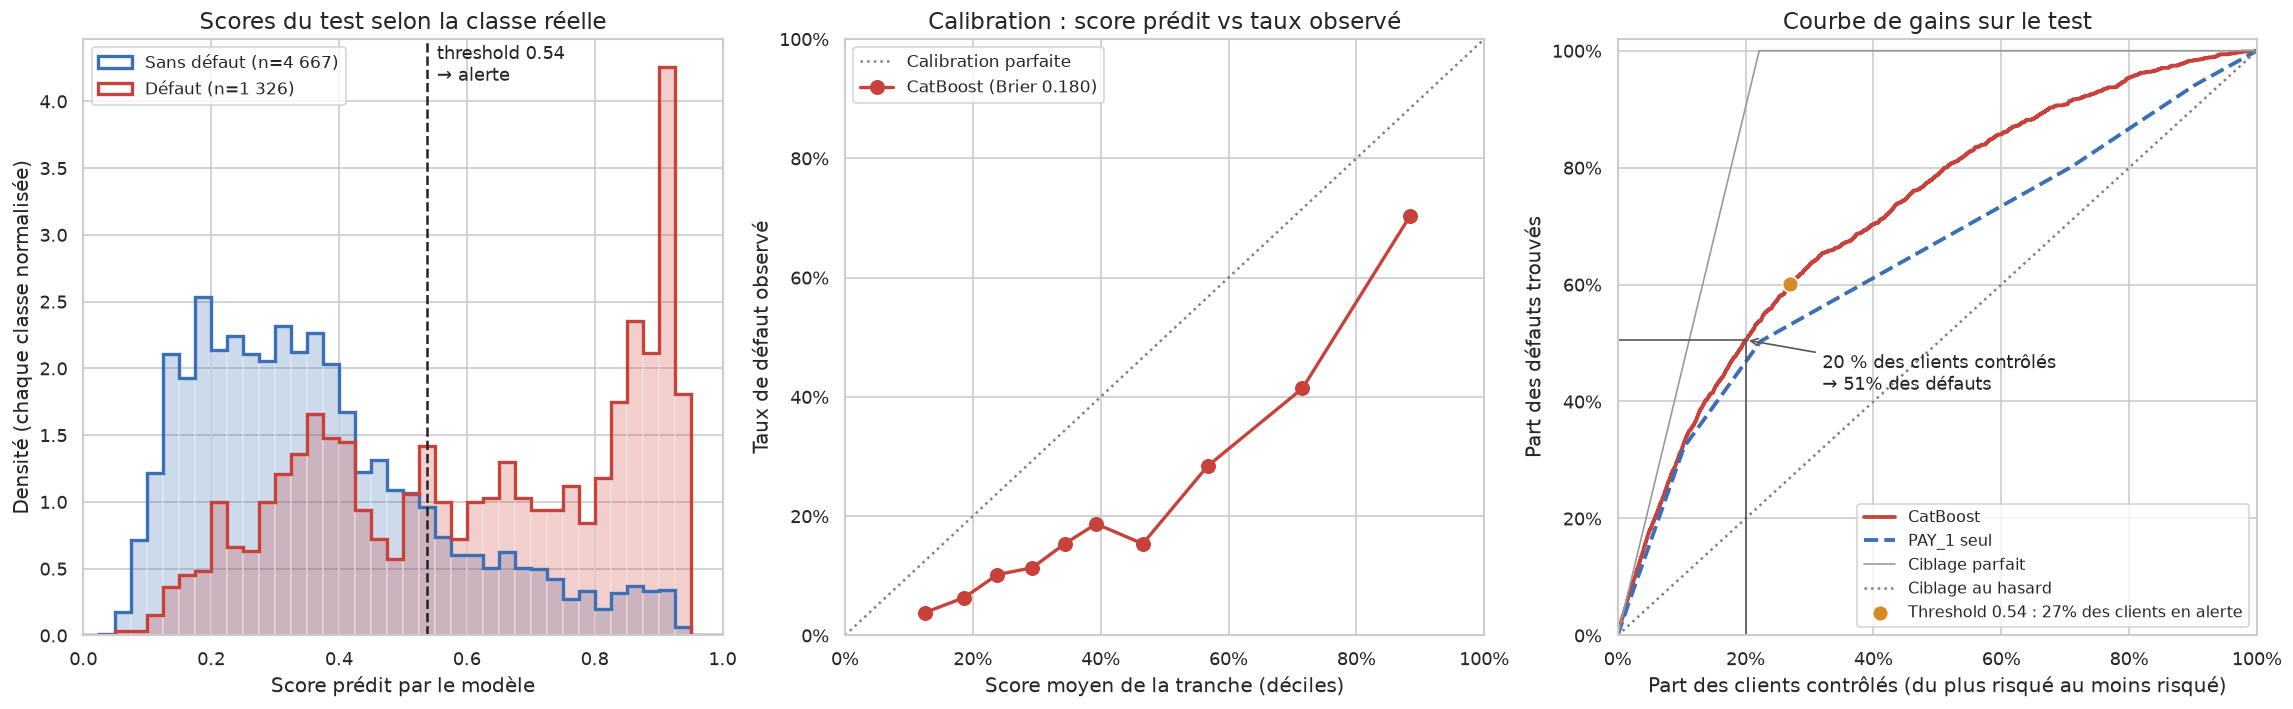

Explication : en contrôlant les 20 % de clients au score le plus élevé, on trouve 51 % des défauts du test, contre 47 % en triant sur `PAY_1` seul et 20 % au hasard. Au threshold 0,54, 27 % des clients sont en alerte. Le score moyen vaut 42,1 % alors que le taux de défaut réel du test est de 22,1 % : les points de calibration sont sous la diagonale. C’est l’effet attendu de `auto_class_weights=Balanced`, qui donne plus de poids aux défauts pendant le fit : le classement reste bon (AUC), mais le score ne doit pas être lu comme une probabilité réelle sans recalibration.

In [53]:

from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss

def courbe_gains(y_vrai, score):
    """Part des défauts captés quand on cible les clients par score décroissant (ex aequo interpolés)."""
    table = pd.DataFrame({'score': score, 'y': np.asarray(y_vrai)}).groupby('score')['y'].agg(['size', 'sum'])
    table = table.sort_index(ascending=False)
    x = np.r_[0, table['size'].cumsum() / len(score)]
    g = np.r_[0, table['sum'].cumsum() / table['sum'].sum()]
    return x, g

vrais_test = y_test.to_numpy()
fig, axes = plt.subplots(1, 3, figsize=(19, 5.8), layout='constrained')

# 1. Distribution des scores
ax = axes[0]
bornes = np.linspace(0, 1, 41)
for classe, couleur, nom in [(0, BLEU, 'Sans défaut'), (1, ROUGE, 'Défaut')]:
    ax.hist(proba_test[vrais_test == classe], bins=bornes, density=True, color=couleur, alpha=.25)
    ax.hist(proba_test[vrais_test == classe], bins=bornes, density=True, histtype='step', color=couleur, lw=2,
            label=f'{nom} (n={int((vrais_test == classe).sum()):,})'.replace(',', ' '))
ax.axvline(SEUIL, color='#222222', ls='--', lw=1.5)
ax.text(SEUIL + .015, ax.get_ylim()[1] * .93, f'threshold {SEUIL:.2f}\n→ alerte', fontsize=10.5)
ax.set(title='Scores du test selon la classe réelle', xlabel='Score prédit par le modèle',
       ylabel='Densité (chaque classe normalisée)', xlim=(0, 1))
ax.legend(loc='upper left', fontsize=10)

# 2. Calibration
ax = axes[1]
taux_obs, score_moyen = calibration_curve(vrais_test, proba_test, n_bins=10, strategy='quantile')
brier = brier_score_loss(vrais_test, proba_test)
ax.plot([0, 1], [0, 1], ':', color='grey', label='Calibration parfaite')
ax.plot(score_moyen, taux_obs, '-o', color=ROUGE, lw=2, markersize=8, label=f'{nom_retenu} (Brier {brier:.3f})')
ax.set(title='Calibration : score prédit vs taux observé', xlabel='Score moyen de la tranche (déciles)',
       ylabel='Taux de défaut observé', xlim=(0, 1), ylim=(0, 1))
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.legend(loc='upper left', fontsize=10)

# 3. Courbe de gains
ax = axes[2]
part_defauts = vrais_test.mean()
for nom, score, couleur, style in [(nom_retenu, proba_test, ROUGE, '-'),
                                  ('PAY_1 seul', X_test['PAY_1'].to_numpy(), BLEU, '--')]:
    x, g = courbe_gains(vrais_test, score)
    ax.plot(x, g, style, color=couleur, lw=2.3, label=nom)
ax.plot([0, part_defauts, 1], [0, 1, 1], color='#999999', lw=1, label='Ciblage parfait')
ax.plot([0, 1], [0, 1], ':', color='grey', label='Ciblage au hasard')
x_m, g_m = courbe_gains(vrais_test, proba_test)
capte_20 = float(np.interp(.2, x_m, g_m))
ax.vlines(.2, 0, capte_20, color='#555555', lw=1)
ax.hlines(capte_20, 0, .2, color='#555555', lw=1)
ax.annotate(f'20 % des clients contrôlés\n→ {capte_20:.0%} des défauts', (.2, capte_20), xytext=(.32, .42),
            fontsize=10.5, arrowprops={'arrowstyle': '->', 'color': '#555555'})
part_alertes = (proba_test >= SEUIL).mean()
ax.scatter(part_alertes, final.loc['Test', 'Recall'], s=90, color=ORANGE, edgecolor='white', zorder=5,
           label=f'Threshold {SEUIL:.2f} : {part_alertes:.0%} des clients en alerte')
ax.set(title='Courbe de gains sur le test', xlabel='Part des clients contrôlés (du plus risqué au moins risqué)',
       ylabel='Part des défauts trouvés', xlim=(0, 1), ylim=(0, 1.02))
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.legend(loc='lower right', fontsize=9.5)
plt.show()

x_r, g_r = courbe_gains(vrais_test, X_test['PAY_1'].to_numpy())
display(Markdown(
    f'Explication : en contrôlant les 20 % de clients au score le plus élevé, on trouve {capte_20:.0%} des défauts du test, '
    f'contre {np.interp(.2, x_r, g_r):.0%} en triant sur `PAY_1` seul et 20 % au hasard. '
    f'Au threshold {SEUIL:.2f}, {part_alertes:.0%} des clients sont en alerte. '
    f'Le score moyen vaut {proba_test.mean():.1%} alors que le taux de défaut réel du test est de {vrais_test.mean():.1%} : '
    'les points de calibration sont sous la diagonale. C’est l’effet attendu de `auto_class_weights=Balanced`, qui donne plus de poids aux défauts pendant le fit : '
    'le classement reste bon (AUC), mais le score ne doit pas être lu comme une probabilité réelle sans recalibration.'
))


## 3.6 Interprétation du modèle

### 3.6.1 Permutation importance

On mélange une feature et on mesure la baisse de ROC-AUC. Le calcul utilise un sous-ensemble de 20 % du train, avec un modèle fit sur les 80 % restants, pour ne pas réutiliser le test final. On répète le mélange cinq fois par feature.

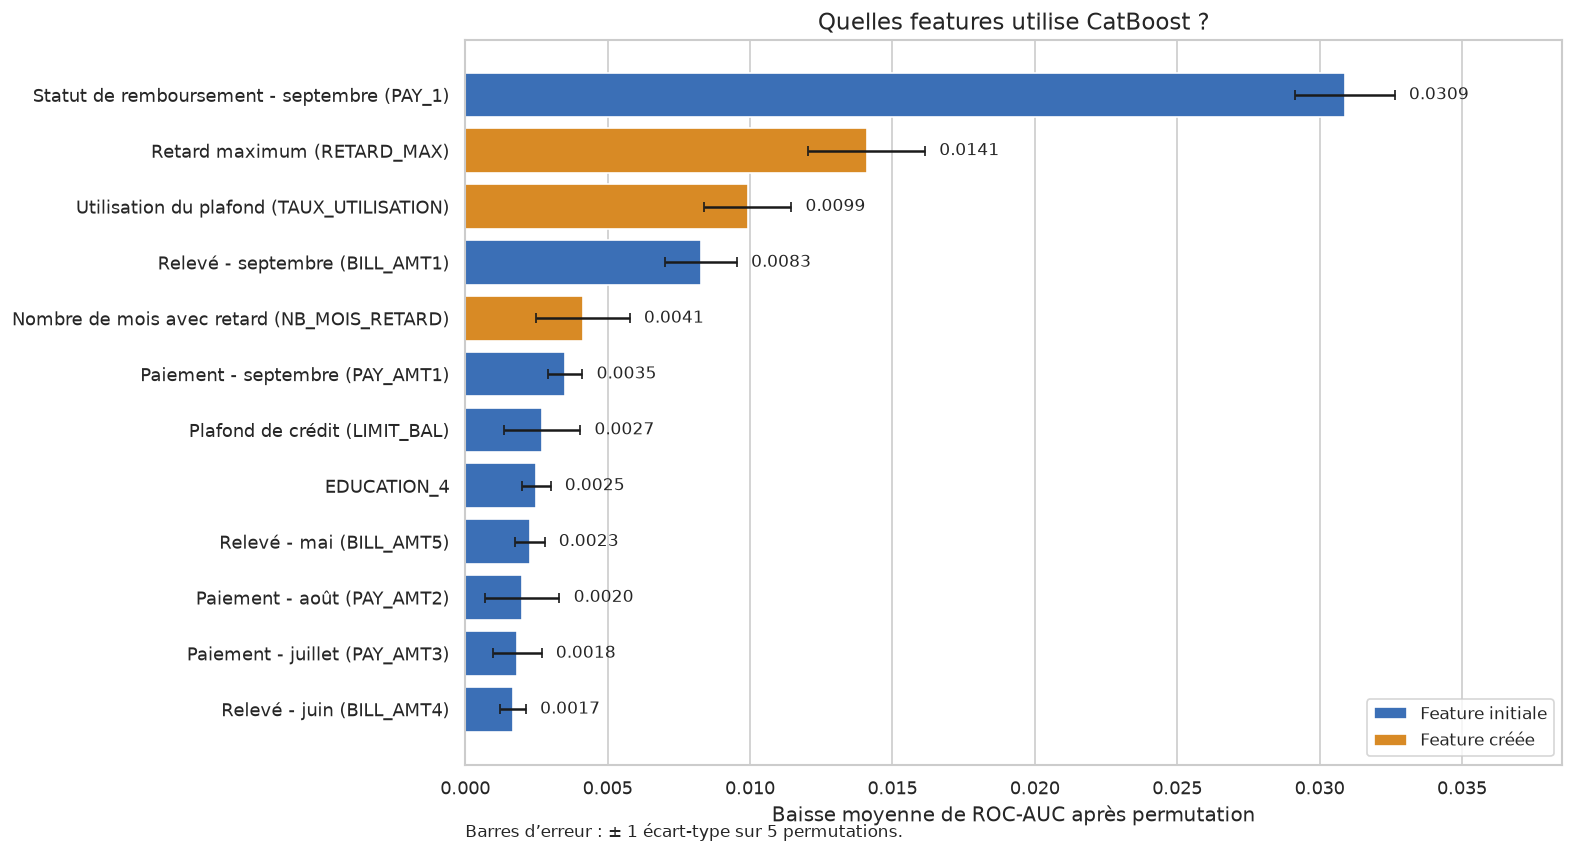

,Baisse de ROC-AUC
PAY_1,0.0309
RETARD_MAX,0.0141
TAUX_UTILISATION,0.0099
BILL_AMT1,0.0083
NB_MOIS_RETARD,0.0041
PAY_AMT1,0.0035
LIMIT_BAL,0.0027
EDUCATION_4,0.0025
BILL_AMT5,0.0023
PAY_AMT2,0.0020


In [54]:
pos_fit, pos_imp = train_test_split(
    np.arange(len(X_train_plus)),
    test_size=0.2,
    stratify=y_train,
    random_state=SEED,
)
modele_imp = clone(construire(nom_retenu, params_finaux))
modele_imp.fit(X_train_plus.iloc[pos_fit], y_train.iloc[pos_fit])
perm = permutation_importance(
    modele_imp,
    X_train_plus.iloc[pos_imp],
    y_train.iloc[pos_imp],
    scoring="roc_auc",
    n_repeats=5,
    random_state=SEED,
    n_jobs=1,
)
importance=pd.Series(perm.importances_mean,index=X_train_plus.columns).sort_values()
top=importance.tail(12)
_ecarts_perm=pd.Series(perm.importances_std,index=X_train_plus.columns).reindex(top.index)
fig,ax=plt.subplots(figsize=(13,7),layout='constrained')
ax.barh([nom_feature(c) for c in top.index],top.values,xerr=_ecarts_perm.values,
        color=[ORANGE if c in nouvelles else BLEU for c in top.index],capsize=3)
for i,(v,s) in enumerate(zip(top.values,_ecarts_perm.values)):
    ax.text(v+s+.0005,i,f'{v:.4f}',va='center',fontsize=10)
ax.axvline(0,color='grey',lw=1)
ax.margins(x=.18)
ax.set(xlabel='Baisse moyenne de ROC-AUC après permutation',title=f'Quelles features utilise {nom_retenu} ?')
ax.legend(handles=[Patch(facecolor=BLEU,label='Feature initiale'),Patch(facecolor=ORANGE,label='Feature créée')],loc='lower right')
ax.grid(axis='y',visible=False)
ax.text(0,-.1,'Barres d’erreur : ± 1 écart-type sur 5 permutations.',transform=ax.transAxes,fontsize=10)
plt.show()
display(importance.sort_values(ascending=False).head(12).rename('Baisse de ROC-AUC').to_frame().round(4))


In [55]:
_ordre_importance = importance.sort_values(ascending=False)
_resume_importance = ', '.join(f'`{nom}` : {valeur:.4f}' for nom, valeur in _ordre_importance.head(5).items())
display(Markdown(
    'Explication : Les plus fortes baisses de ROC-AUC après permutation sont : '
    + _resume_importance + '. Une grande baisse indique que le modèle utilise cette information. '
    'Des features corrélées peuvent se remplacer : leur importance individuelle ne résume donc pas tout leur intérêt. '
    'Ces résultats dépendent du modèle et ne montrent pas une relation causale.'
))

Explication : Les plus fortes baisses de ROC-AUC après permutation sont : `PAY_1` : 0,0309, `RETARD_MAX` : 0,0141, `TAUX_UTILISATION` : 0,0099, `BILL_AMT1` : 0,0083, `NB_MOIS_RETARD` : 0,0041. Une grande baisse indique que le modèle utilise cette information. Des features corrélées peuvent se remplacer : leur importance individuelle ne résume donc pas tout leur intérêt. Ces résultats dépendent du modèle et ne montrent pas une relation causale.

### 3.6.2 Partial dependence plots

Les PDP montrent comment la prédiction moyenne change lorsqu’on fait varier une feature dans l’échantillon. Ce sont des descriptions du modèle, pas des effets causaux.

Contrairement aux graphiques d’EDA, les PDP montrent des probabilités prédites moyennées, pas le taux de défaut observé dans chaque groupe de clients.


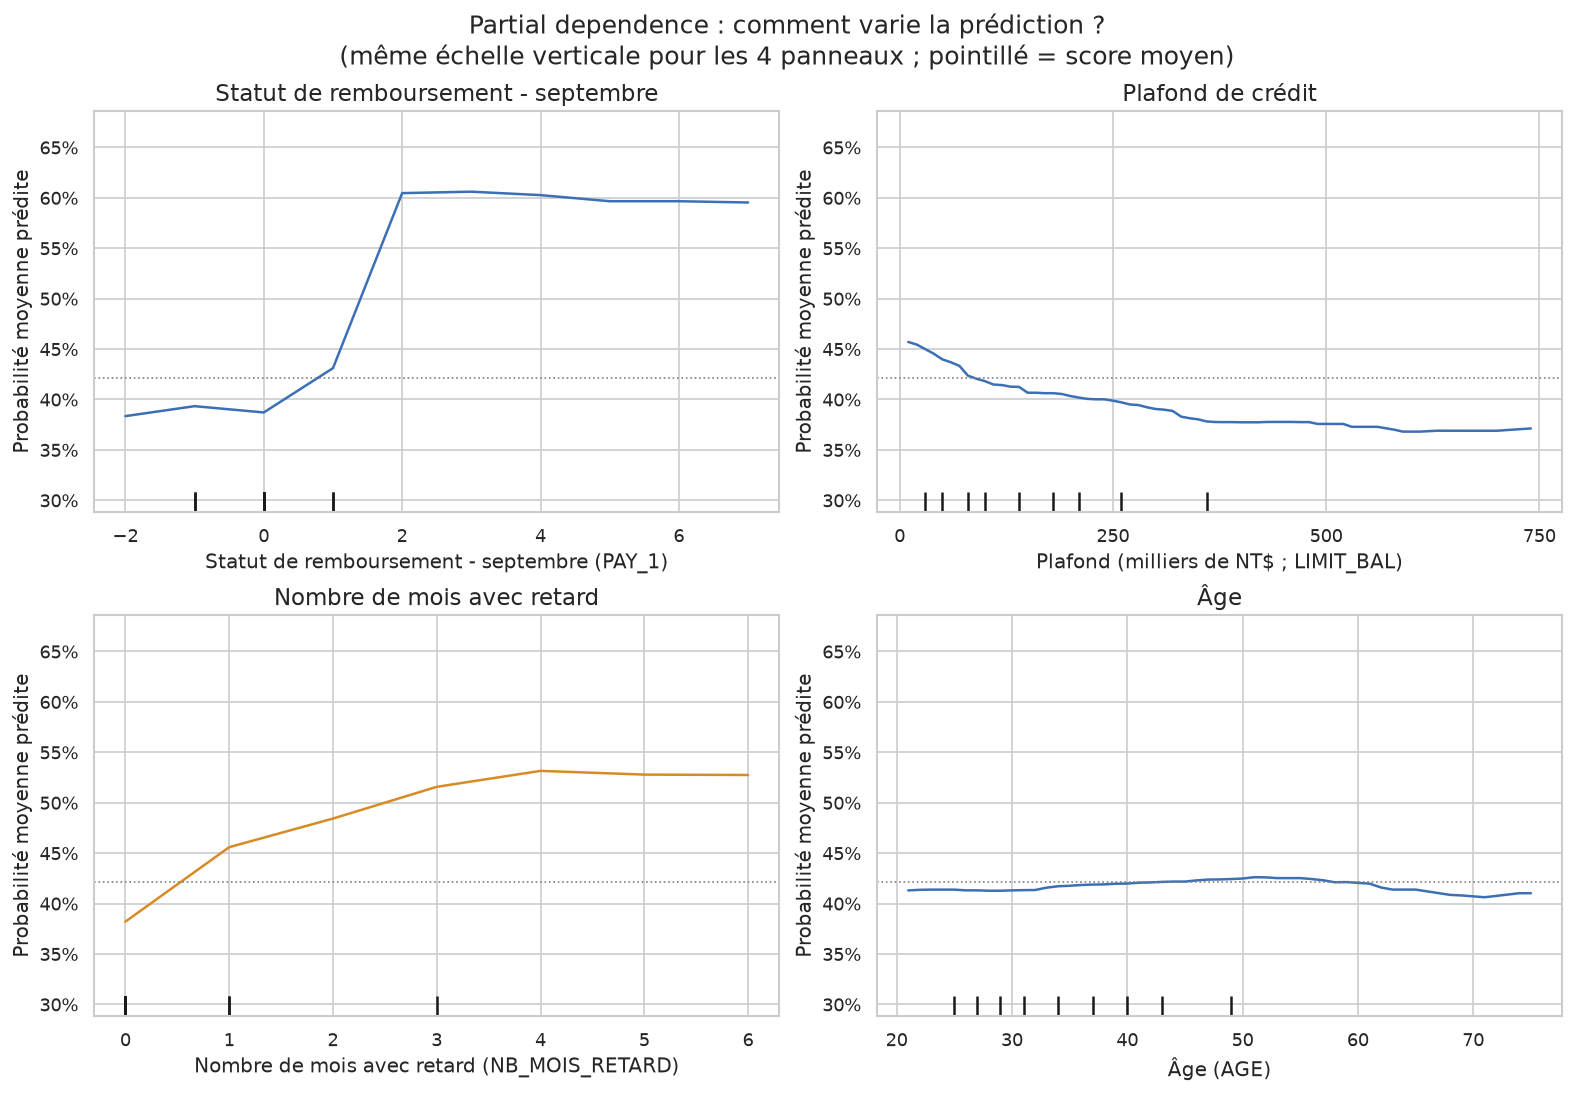

In [56]:
echantillon=X_train_plus.sample(3000,random_state=SEED).astype(float)
_features_pdp=['PAY_1','LIMIT_BAL','NB_MOIS_RETARD','AGE']
fig,axes=plt.subplots(2,2,figsize=(13,9),layout='constrained')
affichage=PartialDependenceDisplay.from_estimator(
    modele_final,echantillon,_features_pdp,response_method='predict_proba',method='brute',ax=axes)
for ax,nom in zip(axes.flat,_features_pdp):
    ax.set(title=NOMS_FEATURES.get(nom,nom),xlabel=nom_feature(nom),ylabel='Probabilité moyenne prédite')
    ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    if nom=='LIMIT_BAL':
        ax.xaxis.set_major_locator(MaxNLocator(nbins=4))
        ax.xaxis.set_major_formatter(FuncFormatter(lambda x,pos:f'{x/1000:g}'))
        ax.set_xlabel('Plafond (milliers de NT$ ; LIMIT_BAL)')
    for ligne in ax.get_lines():ligne.set_color(ORANGE if nom in nouvelles else BLEU)
_toutes=np.concatenate([r['average'][0] for r in affichage.pd_results])
for ax in axes.flat:
    ax.set_ylim(max(0,_toutes.min()-.08),min(1,_toutes.max()+.08))
    ax.axhline(proba_test.mean(),color='grey',ls=':',lw=1)
fig.suptitle('Partial dependence : comment varie la prédiction ?\n(même échelle verticale pour les 4 panneaux ; pointillé = score moyen)',fontsize=15)
plt.show()


In [57]:
_textes_pdp = []
for _feature, _pdp in zip(['PAY_1', 'LIMIT_BAL', 'NB_MOIS_RETARD', 'AGE'], affichage.pd_results):
    _grid = _pdp['grid_values'][0]
    _moyennes = _pdp['average'][0]
    _textes_pdp.append(
        f'Pour `{_feature}`, la prédiction moyenne va de {_moyennes[0]:.1%} '
        f'à {_moyennes[-1]:.1%} entre les valeurs {_grid[0]:g} et {_grid[-1]:g} de la grille.'
    )
display(Markdown('Explication : ' + ' '.join(_textes_pdp) +
    ' Ces courbes décrivent le comportement du modèle en faisant varier une feature. '
    'Elles ne mesurent pas un effet causal et peuvent créer des combinaisons peu réalistes entre features corrélées.'))
display(Markdown('Le saut le plus net apparaît pour `PAY_1` à partir du code 2 : le score moyen est alors proche de 60 %, contre environ 40 % pour les codes sans retard. L’âge fait beaucoup moins varier le score. Le modèle s’appuie donc surtout sur les incidents récents et répétés de remboursement, ce qui rejoint la permutation importance dominée par `PAY_1` et `RETARD_MAX`. Ici, CatBoost utilise `auto_class_weights=Balanced` : ces scores sont gonflés (voir la calibration en § 3.5.1) : on lit les écarts entre valeurs, pas le niveau absolu.'))


Explication : Pour `PAY_1`, la prédiction moyenne va de 38,3 % à 59,5 % entre les valeurs -2 et 7 de la grille. Pour `LIMIT_BAL`, la prédiction moyenne va de 45,7 % à 37,1 % entre les valeurs 10000 et 740000 de la grille. Pour `NB_MOIS_RETARD`, la prédiction moyenne va de 38,2 % à 52,7 % entre les valeurs 0 et 6 de la grille. Pour `AGE`, la prédiction moyenne va de 41,3 % à 41,0 % entre les valeurs 21 et 75 de la grille. Ces courbes décrivent le comportement du modèle en faisant varier une feature. Elles ne mesurent pas un effet causal et peuvent créer des combinaisons peu réalistes entre features corrélées.

Le saut le plus net apparaît pour `PAY_1` à partir du code 2 : le score moyen est alors proche de 60 %, contre environ 40 % pour les codes sans retard. L’âge fait beaucoup moins varier le score. Le modèle s’appuie donc surtout sur les incidents récents et répétés de remboursement, ce qui rejoint la permutation importance dominée par `PAY_1` et `RETARD_MAX`. Ici, CatBoost utilise `auto_class_weights=Balanced` : ces scores sont gonflés (voir la calibration en § 3.5.1) : on lit les écarts entre valeurs, pas le niveau absolu.

### 3.6.3 Valeurs SHAP : pourquoi ce client ?

La permutation importance et les PDP décrivent le modèle **en moyenne**. Les valeurs SHAP l’expliquent **client par client** : pour chaque prédiction, elles répartissent l’écart entre le score du client et le score moyen entre les features. La somme des contributions redonne exactement la prédiction du client, exprimée en log-odds : le logarithme de p / (1 − p), l’échelle sur laquelle CatBoost additionne ses arbres.

CatBoost les calcule directement (`get_feature_importance(type='ShapValues')`, algorithme TreeSHAP), sans bibliothèque supplémentaire. On les calcule sur le test réservé : on explique des décisions déjà prises, sans rien choisir sur ces données.

- **Graphique 1** : chaque point est un client. La position horizontale donne la contribution de la feature à son score (à droite, elle augmente le risque). La couleur donne la valeur de la feature pour ce client, de bleu (basse) à rouge (haute).
- **Graphique 2** : la décomposition du score d’un client signalé par le modèle, du score moyen jusqu’à son score final.

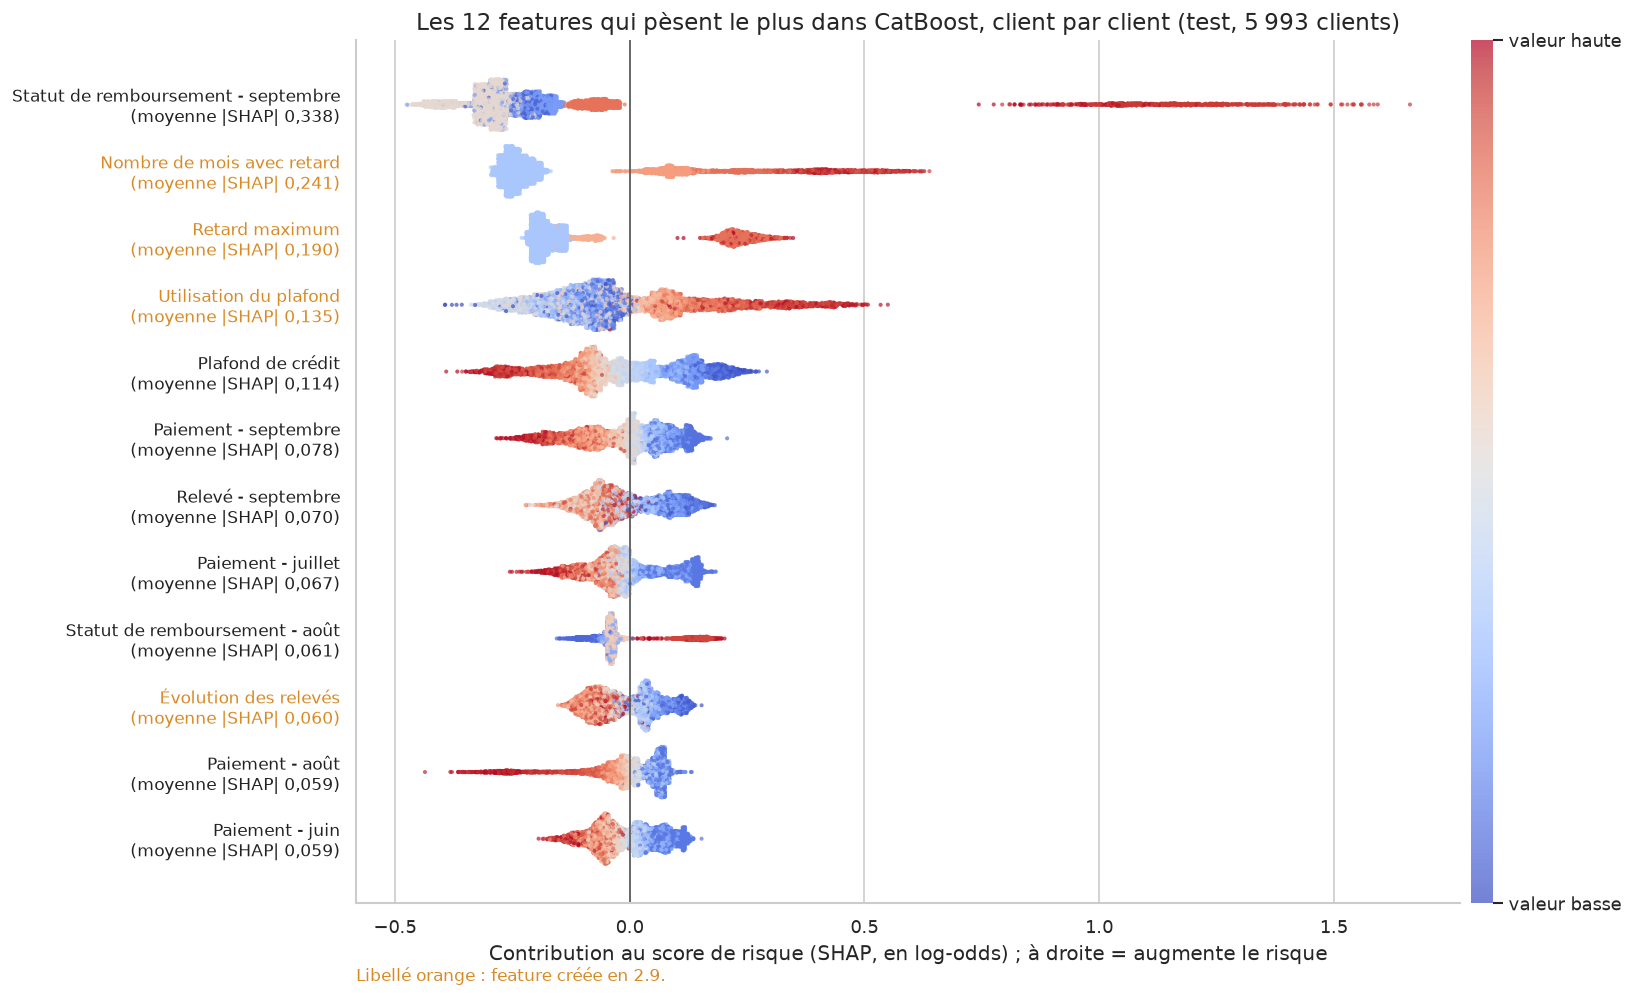

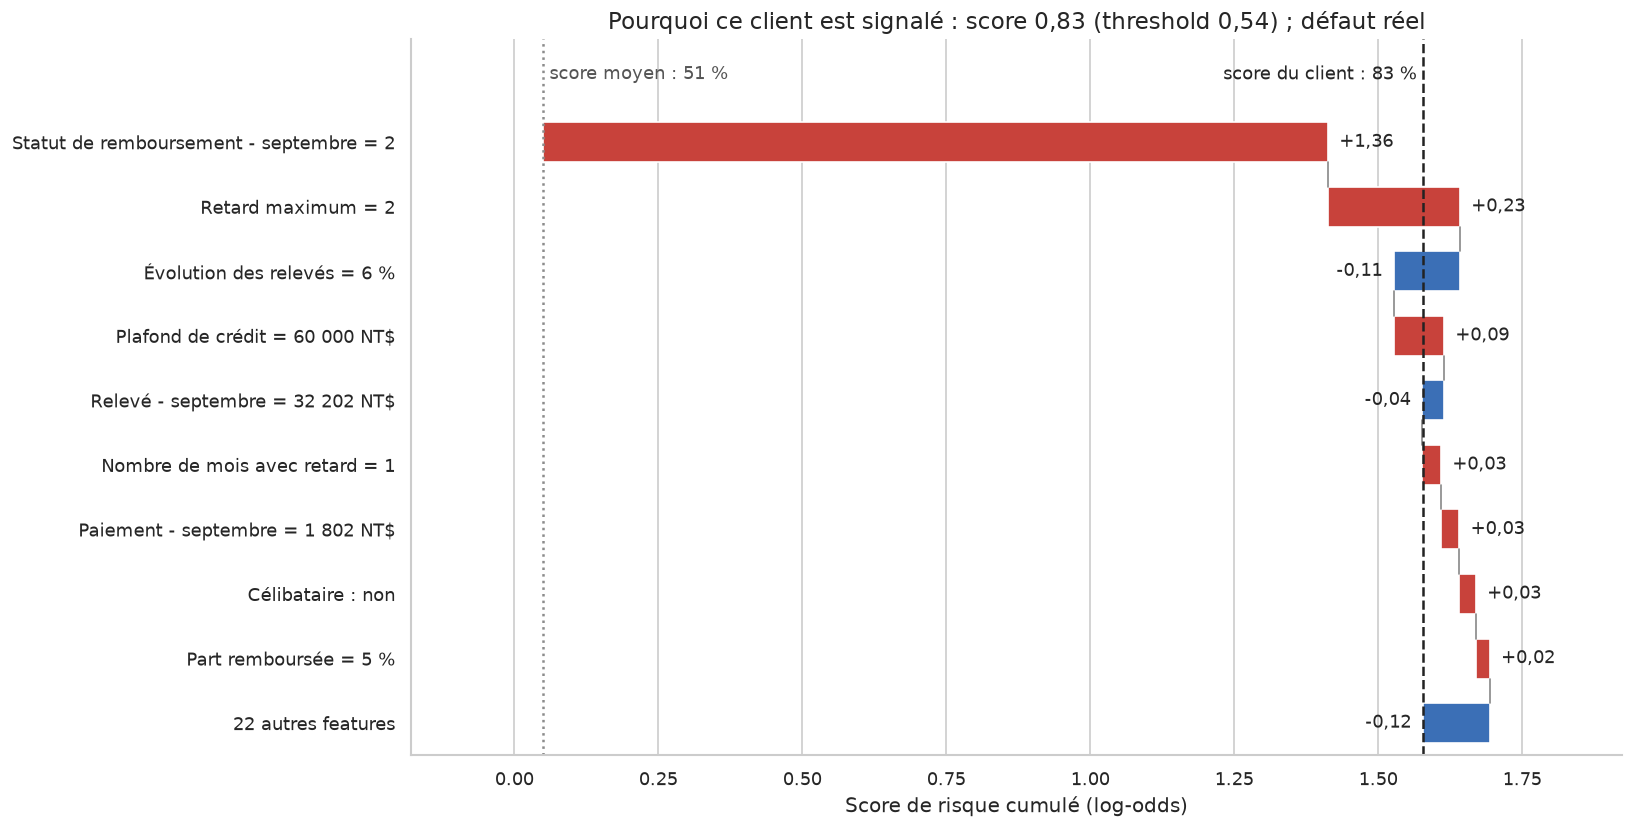

Explication : sur le test, les features les plus influentes sont `PAY_1`, `NB_MOIS_RETARD`, `RETARD_MAX`, ce qui rejoint la permutation importance (§ 3.6.1). 4 des 12 premières sont des features créées au § 2.9 : `NB_MOIS_RETARD`, `RETARD_MAX`, `TAUX_UTILISATION`, `EVOLUTION_DETTE`. Le graphique 1 montre ce qu’une importance moyenne cache : pour `PAY_1`, le nuage isolé à droite rassemble les clients en retard en septembre, et son étalement montre que le même retard pèse plus ou moins selon le reste du profil. Pour le client du graphique 2, le score part de 51 % (score moyen) et arrive à 83 %. Ce qui le fait monter le plus : `PAY_1` (+1,36), `RETARD_MAX` (+0,23), `LIMIT_BAL` (+0,09). Ce qui le fait baisser : `EVOLUTION_DETTE` (-0,11), `BILL_AMT1` (-0,04). C’est ce type de décomposition qu’on peut présenter à un chargé de clientèle pour justifier une alerte. Deux limites : le modèle utilise `auto_class_weights=Balanced`, donc les pourcentages sont gonflés (§ 3.5.1) et seuls les écarts se lisent ; et des features corrélées (`PAY_1`, `RETARD_MAX`, `NB_MOIS_RETARD`) se partagent la même information. Les valeurs SHAP décrivent le modèle, pas une relation causale.

In [58]:
from catboost import Pool

_shap_brut = modele_final.get_feature_importance(Pool(X_test_plus, y_test), type='ShapValues')
shap_test = pd.DataFrame(_shap_brut[:, :-1], columns=X_test_plus.columns, index=X_test_plus.index)
base_shap = float(_shap_brut[0, -1])                       # score moyen du modèle, en log-odds
assert np.allclose(_shap_brut.sum(1), modele_final.predict(X_test_plus, prediction_type='RawFormulaVal'))
importance_shap = shap_test.abs().mean().sort_values(ascending=False)
_top_shap = importance_shap.head(12).index
sigmoide = lambda z: 1 / (1 + np.exp(-z))

# 1. Vue d'ensemble : un point par client
fig, ax = plt.subplots(figsize=(13.5, 8.2), layout='constrained')
_rng = np.random.default_rng(SEED)
for j, col in enumerate(_top_shap):
    x = shap_test[col].to_numpy()
    couleur = X_test_plus[col].rank(pct=True).to_numpy()   # rang de la valeur : robuste aux montants extrêmes
    dens, bords = np.histogram(x, bins=60)
    largeur = dens[np.clip(np.digitize(x, bords) - 1, 0, 59)] / dens.max()   # plus de clients = nuage plus épais
    y = j + _rng.uniform(-.38, .38, len(x)) * largeur
    nuage = ax.scatter(x, y, c=couleur, cmap='coolwarm', vmin=0, vmax=1, s=6, alpha=.7, linewidths=0, rasterized=True)
ax.axvline(0, color='#555555', lw=1)
ax.set_yticks(range(len(_top_shap)),
              [format_fr(f'{NOMS_FEATURES.get(col, col)}\n(moyenne |SHAP| {importance_shap[col]:.3f})') for col in _top_shap],
              fontsize=10)
for etiquette, col in zip(ax.get_yticklabels(), _top_shap):
    etiquette.set_color(ORANGE if col in nouvelles else '#222222')
ax.invert_yaxis()
ax.set(xlabel='Contribution au score de risque (SHAP, en log-odds) ; à droite = augmente le risque',
       title=f'Les 12 features qui pèsent le plus dans {nom_retenu}, client par client '
             f'(test, {format_fr(f"{len(X_test_plus):,}")} clients)')
barre = fig.colorbar(nuage, ax=ax, pad=.01, aspect=40)
barre.set_ticks([0, 1], labels=['valeur basse', 'valeur haute'])
barre.outline.set_visible(False)
ax.text(0, -.09, 'Libellé orange : feature créée en 2.9.', transform=ax.transAxes, fontsize=10, color=ORANGE)
ax.grid(axis='y', visible=False)
sns.despine(ax=ax)
plt.show()

# 2. Un client : défaut réel, détecté par le modèle, score proche de la médiane des défauts détectés
_detectes = np.flatnonzero((proba_test >= SEUIL) & (vrais_test == 1))
_pos = _detectes[np.argmin(np.abs(proba_test[_detectes] - np.median(proba_test[_detectes])))]
_contrib = shap_test.iloc[_pos]
_valeurs = X_test_plus.iloc[_pos]
_ordre = _contrib.abs().sort_values(ascending=False).index
_garde, _reste = list(_ordre[:9]), _ordre[9:]

_INDICATRICES = {'SEX_2': 'Femme', 'EDUCATION_2': 'Études : université', 'EDUCATION_3': 'Études : lycée',
                 'EDUCATION_4': 'Études : autre', 'MARRIAGE_2': 'Célibataire', 'MARRIAGE_3': 'Situation familiale : autre'}

def _libelle(col, v):
    if col in _INDICATRICES:
        return f'{_INDICATRICES[col]} : {"oui" if v == 1 else "non"}'
    return format_fr(f'{NOMS_FEATURES.get(col, col)} = {_valeur_lisible(col, v)}')

def _valeur_lisible(col, v):
    if col in ('LIMIT_BAL',) or col.startswith(('BILL_AMT', 'PAY_AMT')):
        return f'{v:,.0f} NT$'.replace(',', ' ')
    if col in ('TAUX_UTILISATION', 'PART_REMBOURSEE', 'EVOLUTION_DETTE'):
        return f'{v:.0%}'
    return f'{v:g}'

_etapes = [(_libelle(col, _valeurs[col]), _contrib[col]) for col in _garde]
_etapes.append((f'{len(_reste)} autres features', _contrib[_reste].sum()))

fig, ax = plt.subplots(figsize=(13.5, 6.8), layout='constrained')
cumul = base_shap
for k, (nom, v) in enumerate(_etapes):
    ax.barh(k, v, left=cumul, color=ROUGE if v > 0 else BLEU, height=.62)
    ax.text(cumul + v + (.02 if v > 0 else -.02), k, format_fr(f'{v:+.2f}'), va='center',
            ha='left' if v > 0 else 'right', fontsize=10.5)
    if k < len(_etapes) - 1:
        ax.plot([cumul + v] * 2, [k + .31, k + .69], color='#888888', lw=1)
    cumul += v
ax.axvline(base_shap, color='#8C8C8C', ls=':', lw=1.5)
ax.axvline(cumul, color='#222222', ls='--', lw=1.5)
ax.set_yticks(range(len(_etapes)), [nom for nom, _ in _etapes], fontsize=10.5)
_chemin = base_shap + np.r_[0, np.cumsum([v for _, v in _etapes])]
_ecart = _chemin.max() - _chemin.min()
ax.set_xlim(_chemin.min() - .14 * _ecart, _chemin.max() + .14 * _ecart)
ax.set_ylim(len(_etapes) - .5, -1.6)
ax.text(base_shap, -1.05, format_fr(f' score moyen : {sigmoide(base_shap):.0%}'), va='center', fontsize=10.5, color='#555555')
ax.text(cumul, -1.05, format_fr(f'score du client : {sigmoide(cumul):.0%} '), va='center', ha='right', fontsize=10.5)
ax.set(xlabel='Score de risque cumulé (log-odds)',
       title=format_fr(f'Pourquoi ce client est signalé : score {proba_test[_pos]:.2f} (threshold {SEUIL:.2f}) ; défaut réel'))
ax.grid(axis='y', visible=False)
sns.despine(ax=ax)
plt.show()

_top3 = list(_top_shap[:3])
_nouv = [col for col in _top_shap if col in nouvelles]
_monte = [col for col in _garde if _contrib[col] > 0][:3]
_baisse = [col for col in _garde if _contrib[col] < 0][:2]
display(Markdown(
    'Explication : sur le test, les features les plus influentes sont ' + ', '.join(f'`{col}`' for col in _top3)
    + f', ce qui rejoint la permutation importance (§ 3.6.1). {len(_nouv)} des 12 premières sont des features créées au § 2.9'
    + (' : ' + ', '.join(f'`{col}`' for col in _nouv) if _nouv else '') + '. '
    'Le graphique 1 montre ce qu’une importance moyenne cache : pour `PAY_1`, le nuage isolé à droite rassemble les clients en retard en septembre, '
    'et son étalement montre que le même retard pèse plus ou moins selon le reste du profil. '
    f'Pour le client du graphique 2, le score part de {sigmoide(base_shap):.0%} (score moyen) et arrive à {proba_test[_pos]:.0%}. '
    'Ce qui le fait monter le plus : ' + ', '.join(f'`{col}` ({_contrib[col]:+.2f})' for col in _monte) + '. '
    + ('Ce qui le fait baisser : ' + ', '.join(f'`{col}` ({_contrib[col]:+.2f})' for col in _baisse) + '. ' if _baisse else '')
    + 'C’est ce type de décomposition qu’on peut présenter à un chargé de clientèle pour justifier une alerte. '
    'Deux limites : le modèle utilise `auto_class_weights=Balanced`, donc les pourcentages sont gonflés (§ 3.5.1) et seuls les écarts se lisent ; '
    'et des features corrélées (`PAY_1`, `RETARD_MAX`, `NB_MOIS_RETARD`) se partagent la même information. '
    'Les valeurs SHAP décrivent le modèle, pas une relation causale.'
))

## 3.7 Récapitulatif

### 3.7.1 Tous les résultats

In [59]:
tous = pd.DataFrame(resultats).T.sort_values("AUC", ascending=False)
display(tous.round(3))


,AUC,Accuracy,Precision,Recall,F1,Temps (s)
Gradient boosting + variables,0.786,0.820,0.677,0.361,0.471,0.394
Gradient boosting,0.784,0.820,0.676,0.360,0.470,0.344
Forêt aléatoire,0.779,0.818,0.659,0.367,0.471,3.859
Réseau de neurones,0.766,0.819,0.665,0.364,0.471,0.748
Régression logistique + variables,0.761,0.809,0.645,0.300,0.410,0.204
Arbre (profondeur 6),0.759,0.819,0.664,0.366,0.472,0.232
KNN (k=200),0.752,0.804,0.663,0.233,0.345,0.679
Bayésien naïf,0.734,0.565,0.307,0.768,0.439,0.161
Régression logistique,0.725,0.810,0.706,0.239,0.357,0.174
SVM (noyau RBF),0.720,0.819,0.694,0.328,0.445,7.940


In [60]:
display(Markdown('### 3.7.2 Comparaison en nested cross-validation'))
display(bilan_externe.round(4))
_meilleurs = bilan_externe.loc[MODELES].sort_values('AUC externe moyenne', ascending=False)
_ecart = _meilleurs.iloc[0]['AUC externe moyenne'] - _meilleurs.iloc[1]['AUC externe moyenne']
display(Markdown(
    f"Explication : {_meilleurs.index[0]} arrive en tête des modèles individuels "
    f"avec une ROC-AUC externe de {_meilleurs.iloc[0]['AUC externe moyenne']:.4f} "
    f"(écart-type {_meilleurs.iloc[0]['Écart-type externe']:.4f}). "
    f"L’écart avec {_meilleurs.index[1]} est de {_ecart:.4f}. "
    "L’écart-type résume les variations entre folds ; ce n’est pas un intervalle de confiance. "
    "Le classement observé ne démontre pas une supériorité sur d’autres populations."
))

### 3.7.2 Comparaison en nested cross-validation

,AUC externe moyenne,Écart-type externe,AUC externe min,AUC externe max
Modèle,,,,
CatBoost,0.7897,0.0101,0.7787,0.8033
XGBoost,0.7890,0.0102,0.7775,0.8032
LightGBM,0.7888,0.0094,0.7758,0.8012
HistGradientBoosting,0.7883,0.0097,0.7757,0.8005
Random forest,0.7877,0.0097,0.7746,0.8002
Vote (logistique + forêt + boosting du pli),0.7862,0.0106,0.7739,0.7982
MLP,0.7752,0.0098,0.7616,0.7869
Decision tree,0.7723,0.0074,0.7605,0.7776
KNN,0.7708,0.0110,0.7547,0.7840


Explication : CatBoost arrive en tête des modèles individuels avec une ROC-AUC externe de 0,7897 (écart-type 0,0101). L’écart avec XGBoost est de 0,0006. L’écart-type résume les variations entre folds ; ce n’est pas un intervalle de confiance. Le classement observé ne démontre pas une supériorité sur d’autres populations.

In [61]:
_rang=bilan_externe.loc[MODELES].sort_values('AUC externe moyenne',ascending=False)
_moyenne=_rang.iloc[0]['AUC externe moyenne'];_std=_rang.iloc[0]['Écart-type externe']
_ecart_suivant=_moyenne-_rang.iloc[1]['AUC externe moyenne']
_gain_lr=resultats['Régression logistique + variables']['AUC']-resultats['Régression logistique']['AUC']
_gain_gb=resultats['Gradient boosting + variables']['AUC']-resultats['Gradient boosting']['AUC']
_auc_regle=final.iloc[2]['AUC'];_f1_regle=final.iloc[2]['F1']
_accuracy_majoritaire=(y_test==0).mean()
display(Markdown(
    '## 3.8 Conclusion et limites\n\n'
    'Les retards récents et répétés apportent davantage d’information que plusieurs variables de profil. '
    f'Les cinq features créées améliorent surtout la logistic regression dans le diagnostic initial : '
    f'le gain d’AUC est de {_gain_lr:+.3f}, contre {_gain_gb:+.3f} pour le boosting. '
    'Leur intérêt dépend donc de la capacité du modèle à reconstruire ces relations à partir des variables de départ.\n\n'
    f'La nested CV retient {nom_retenu}, avec une ROC-AUC externe moyenne de {_moyenne:.4f} '
    f'et un écart-type de {_std:.4f}. L’écart avec {_rang.index[1]} n’est que de {_ecart_suivant:.4f}. '
    'Ce résultat désigne le meilleur score observé dans ce benchmark, sans démontrer une supériorité générale sur les autres ensembles d’arbres.\n\n'
    f'Sur les {len(y_test):,} observations réservées, la ROC-AUC est de {final.loc["Test","AUC"]:.3f}, '
    f'contre {_auc_regle:.3f} pour PAY_1 seul. Le F1 vaut {final.loc["Test","F1"]:.3f}, '
    f'contre {_f1_regle:.3f} pour la règle fixe. Au threshold {SEUIL:.2f}, le modèle détecte '
    f'{detectes} des {int(y_test.sum())} défauts ({final.loc["Test","Recall"]:.1%}), '
    f'en manque {manques} et produit {fausses} fausses alertes. '
    f'Sa precision est de {final.loc["Test","Precision"]:.1%} : environ une alerte sur deux correspond à un défaut.\n\n'
    f'L’accuracy de {final.loc["Test","Accuracy"]:.1%} reste inférieure aux {_accuracy_majoritaire:.1%} '
    'd’une réponse toujours « sans défaut ». Ce n’est pas une amélioration de toutes les métriques : '
    'le modèle accepte davantage de fausses alertes pour détecter des défauts. Maximiser le F1 fixe un compromis statistique, '
    'pas un optimum économique ; il manque le coût d’un défaut non détecté, celui d’une fausse alerte et la capacité de traitement.\n\n'
    'Les données décrivent une population à Taïwan en 2005. Un split aléatoire ne mesure pas la stabilité sur une autre période ou une autre banque. '
    'La suppression de 35 lignes identiques hors ID est une convention de nettoyage : elle ne prouve pas qu’il s’agit des mêmes personnes. '
    'Les codes non documentés et les ratios de montants demandent aussi une clarification métier. '
    'Le choix de la meilleure famille parmi plusieurs scores externes reste une sélection, et le score OOF final n’est pas une nouvelle estimation indépendante.\n\n'
    'La suite serait de valider le modèle sur une autre période, examiner les faux négatifs et les faux positifs par groupes suffisamment représentés, '
    'puis choisir le threshold avec des coûts explicites. '
    f'La courbe de calibration (section 3.5) montre un score moyen de {proba_test.mean():.1%} pour un taux réel de {y_test.mean():.1%} : '
    'avec `auto_class_weights=Balanced`, les scores surestiment le risque et devraient être recalibrés (Platt ou isotonic, sur le train) avant d’être lus comme des probabilités. '
    'Des informations comme les revenus, les autres engagements ou l’ancienneté pourraient être étudiées '
    'si elles sont disponibles au moment de la prédiction. Les importances et les PDP décrivent le comportement du modèle ; ils ne démontrent pas une causalité.'
))


## 3.8 Conclusion et limites

Les retards récents et répétés apportent davantage d’information que plusieurs variables de profil. Les cinq features créées améliorent surtout la logistic regression dans le diagnostic initial : le gain d’AUC est de +0,036, contre +0,002 pour le boosting. Leur intérêt dépend donc de la capacité du modèle à reconstruire ces relations à partir des variables de départ.

La nested CV retient CatBoost, avec une ROC-AUC externe moyenne de 0,7897 et un écart-type de 0,0101. L’écart avec XGBoost n’est que de 0,0006. Ce résultat désigne le meilleur score observé dans ce benchmark, sans démontrer une supériorité générale sur les autres ensembles d’arbres.

Sur les 5 993 observations réservées, la ROC-AUC est de 0,780, contre 0,687 pour PAY_1 seul. Le F1 vaut 0,541, contre 0,501 pour la règle fixe. Au threshold 0,54, le modèle détecte 796 des 1326 défauts (60,0 %), en manque 530 et produit 823 fausses alertes. Sa precision est de 49,2 % : environ une alerte sur deux correspond à un défaut.

L’accuracy de 77,4 % reste inférieure aux 77,9 % d’une réponse toujours « sans défaut ». Ce n’est pas une amélioration de toutes les métriques : le modèle accepte davantage de fausses alertes pour détecter des défauts. Maximiser le F1 fixe un compromis statistique, pas un optimum économique ; il manque le coût d’un défaut non détecté, celui d’une fausse alerte et la capacité de traitement.

Les données décrivent une population à Taïwan en 2005. Un split aléatoire ne mesure pas la stabilité sur une autre période ou une autre banque. La suppression de 35 lignes identiques hors ID est une convention de nettoyage : elle ne prouve pas qu’il s’agit des mêmes personnes. Les codes non documentés et les ratios de montants demandent aussi une clarification métier. Le choix de la meilleure famille parmi plusieurs scores externes reste une sélection, et le score OOF final n’est pas une nouvelle estimation indépendante.

La suite serait de valider le modèle sur une autre période, examiner les faux négatifs et les faux positifs par groupes suffisamment représentés, puis choisir le threshold avec des coûts explicites. La courbe de calibration (section 3,5) montre un score moyen de 42,1 % pour un taux réel de 22,1 % : avec `auto_class_weights=Balanced`, les scores surestiment le risque et devraient être recalibrés (Platt ou isotonic, sur le train) avant d’être lus comme des probabilités. Des informations comme les revenus, les autres engagements ou l’ancienneté pourraient être étudiées si elles sont disponibles au moment de la prédiction. Les importances et les PDP décrivent le comportement du modèle ; ils ne démontrent pas une causalité.